# Two-hour microclimate forecasting
## Eight sensors · 120 future minutes · GPU training · reusable Joblib model

This notebook compares **persistence, Ridge regression, GRU, and a temporal
convolutional network (TCN)**. Given the latest 120 consecutive one-minute sensor
readings, it predicts all eight readings at every minute from **+1 to +120**.

The winner is selected on validation data **before** examining the test results.
All test comparisons use identical forecast origins. A final worked example loads
the exported artifact and shows the input, predictions, actual readings, and errors.

**Interpretation:** evaluation covers the supplied time series, not independent
field validation. Chronological separation alone does not establish independence
when source patterns recur. Existing provenance documents remain authoritative.
Future sensor readings are the prediction targets; no independent reference
instrument or calibration measurements are supplied. R² > 0.75 is a target, not
a promised result or proof of calibration. No growth or post-sale dynamics are
assumed by the forecasting model.

Run cells in order. The notebook uses the project's `.venv` environment and
requires an NVIDIA GPU for neural-model training. No dataset files are rewritten.


## Saved training record — results restored

This notebook contains the recorded results of the completed model comparison:
**60 GRU epochs, 60 TCN epochs, the GRU export, evaluation metrics and graphs**.
The visible outputs were restored from the retained training histories, metrics,
figures and export-verification records after directory cleanup. **Training was
not rerun during restoration.** Execution counters are cleared rather than
inventing a new kernel execution history.

You can read the saved tables and graphs without rerunning any cells. The deleted
local environment is needed only to execute code again; installation instructions
are in the project README. Choose a Python 3.12 environment with the listed
CUDA/PyTorch requirements before rerunning. Running all cells trains again.

The standalone `training_report.html` beside this notebook is readable in a normal
browser without Jupyter. `training_record.json` records the evidence-file hashes.


In [ ]:
from pathlib import Path
import copy, hashlib, importlib.metadata, json, math, os, random, time
import numpy as np
import pandas as pd
import matplotlib
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
import joblib
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from threadpoolctl import threadpool_limits
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

PROJECT = Path.cwd().resolve()
while not (PROJECT / 'outputs').is_dir():
    if PROJECT.parent == PROJECT:
        raise FileNotFoundError('Run this notebook within the project directory.')
    PROJECT = PROJECT.parent
RESULTS = PROJECT / 'outputs' / 'forecasting_results'
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
paths = sorted((PROJECT / 'outputs').glob('*microclimate.csv'))
assert len(paths) == 1, 'Expected exactly one source CSV in outputs/.'
DATA_PATH = paths[0]
PROVENANCE_PATH = DATA_PATH.with_suffix('.provenance.json')
SOURCE_HASH = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
CONFIG = dict(history=120, horizon=120, seed=42, batch_size=128, max_epochs=60,
              early_stopping_patience=8, lr_patience=3, learning_rate=.001,
              weight_decay=.0001, gradient_clip=1.0, train_fraction=.70,
              validation_end_fraction=.85, ridge_alphas=[1., 10., 100.])
SEED, H, F = CONFIG['seed'], CONFIG['history'], CONFIG['horizon']
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
threadpool_limits(limits=4)
if not torch.cuda.is_available():
    raise RuntimeError('CUDA unavailable. Select the project GPU kernel and a CUDA-enabled PyTorch build; neural training will not silently fall back to CPU.')
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = torch.device('cuda')
probe = torch.ones((32, 32), device=DEVICE) @ torch.ones((32, 32), device=DEVICE)
assert probe[0, 0].item() == 32
print('GPU:', torch.cuda.get_device_name(0))
print('VRAM (GiB):', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))
print('PyTorch:', torch.__version__, '| CUDA runtime:', torch.version.cuda)
print('Float32 inference; mixed-precision neural training. Seed:', SEED)
VERSIONS = {p: importlib.metadata.version(p) for p in
            ['torch', 'numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'joblib', 'nbformat', 'nbclient', 'ipykernel']}
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 115, 'font.size': 10, 'axes.titlesize': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = {'Persistence': '#8b8b8b', 'Ridge': '#b56a22', 'GRU': '#207aab', 'TCN': '#268263'}
figure_files = []
def savefig(name):
    path = FIGURES / f'{name}.png'
    plt.gcf().savefig(path, dpi=150, bbox_inches='tight', facecolor='white')
    figure_files.append(path.name)
    plt.show()
    plt.close()
display(pd.Series(CONFIG, name='Configuration').to_frame())


GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
VRAM (GiB): 5.72
PyTorch: 2.7.1+cu126 | CUDA runtime: 12.6
Float32 inference; mixed-precision neural training. Seed: 42


,Configuration
history,120
horizon,120
seed,42
batch_size,128
max_epochs,60
early_stopping_patience,8
lr_patience,3
learning_rate,0.001
weight_decay,0.0001
gradient_clip,1.0


## 1. Inspect the series
Timestamps are UTC. Values retain their original units. Missing minute bins are
left missing. Structural transitions documented in the sidecar are excluded from
forecast windows; excluding them does not make this independent field validation.


45,644 rows; 46,108 minute bins; 464 missing minute bins.
UTC coverage: 2026-10-08 05:36:00+00:00 to 2026-11-09 06:03:00+00:00


,count,mean,std,min,25%,50%,75%,max
Temp (°C),45644.0,28.3734,1.3904,25.2900,27.3100,28.6200,29.5800,31.2200
Humidity (%),45644.0,88.2447,1.8401,82.4500,87.1700,88.9100,89.6600,91.0100
CO2 (ppm),45644.0,1138.3127,59.2933,983.0000,1103.0000,1139.0000,1169.0000,1363.0000
PM1.0 (µg/m³),45644.0,5.8109,8.2527,0.0000,0.0000,2.0000,7.0000,45.0000
PM2.5 (µg/m³),45644.0,12.2678,13.0945,0.0000,3.0000,7.0000,18.0000,91.0000
PM10 (µg/m³),45644.0,14.8505,15.6858,0.0000,4.0000,9.0000,20.0000,106.0000
Methane (ppm),45644.0,0.8324,0.1775,0.4833,0.6884,0.8163,0.9442,2.0097
Ammonia (ppm),45644.0,3.2110,0.8700,1.3240,2.5890,3.0258,3.6696,8.0565


,Temp (°C),Humidity (%),CO2 (ppm),PM1.0 (µg/m³),PM2.5 (µg/m³),PM10 (µg/m³),Methane (ppm),Ammonia (ppm)
Timestamp (UTC),,,,,,,,
2026-10-08 05:36:00+00:00,29.84,86.33,1138.0,0.0,1.0,2.0,0.620704,2.566574
2026-10-08 05:37:00+00:00,29.94,86.84,1152.0,0.0,3.0,5.0,0.820851,3.323202
2026-10-08 05:38:00+00:00,30.06,87.29,1146.0,3.0,13.0,14.0,0.994753,5.209115


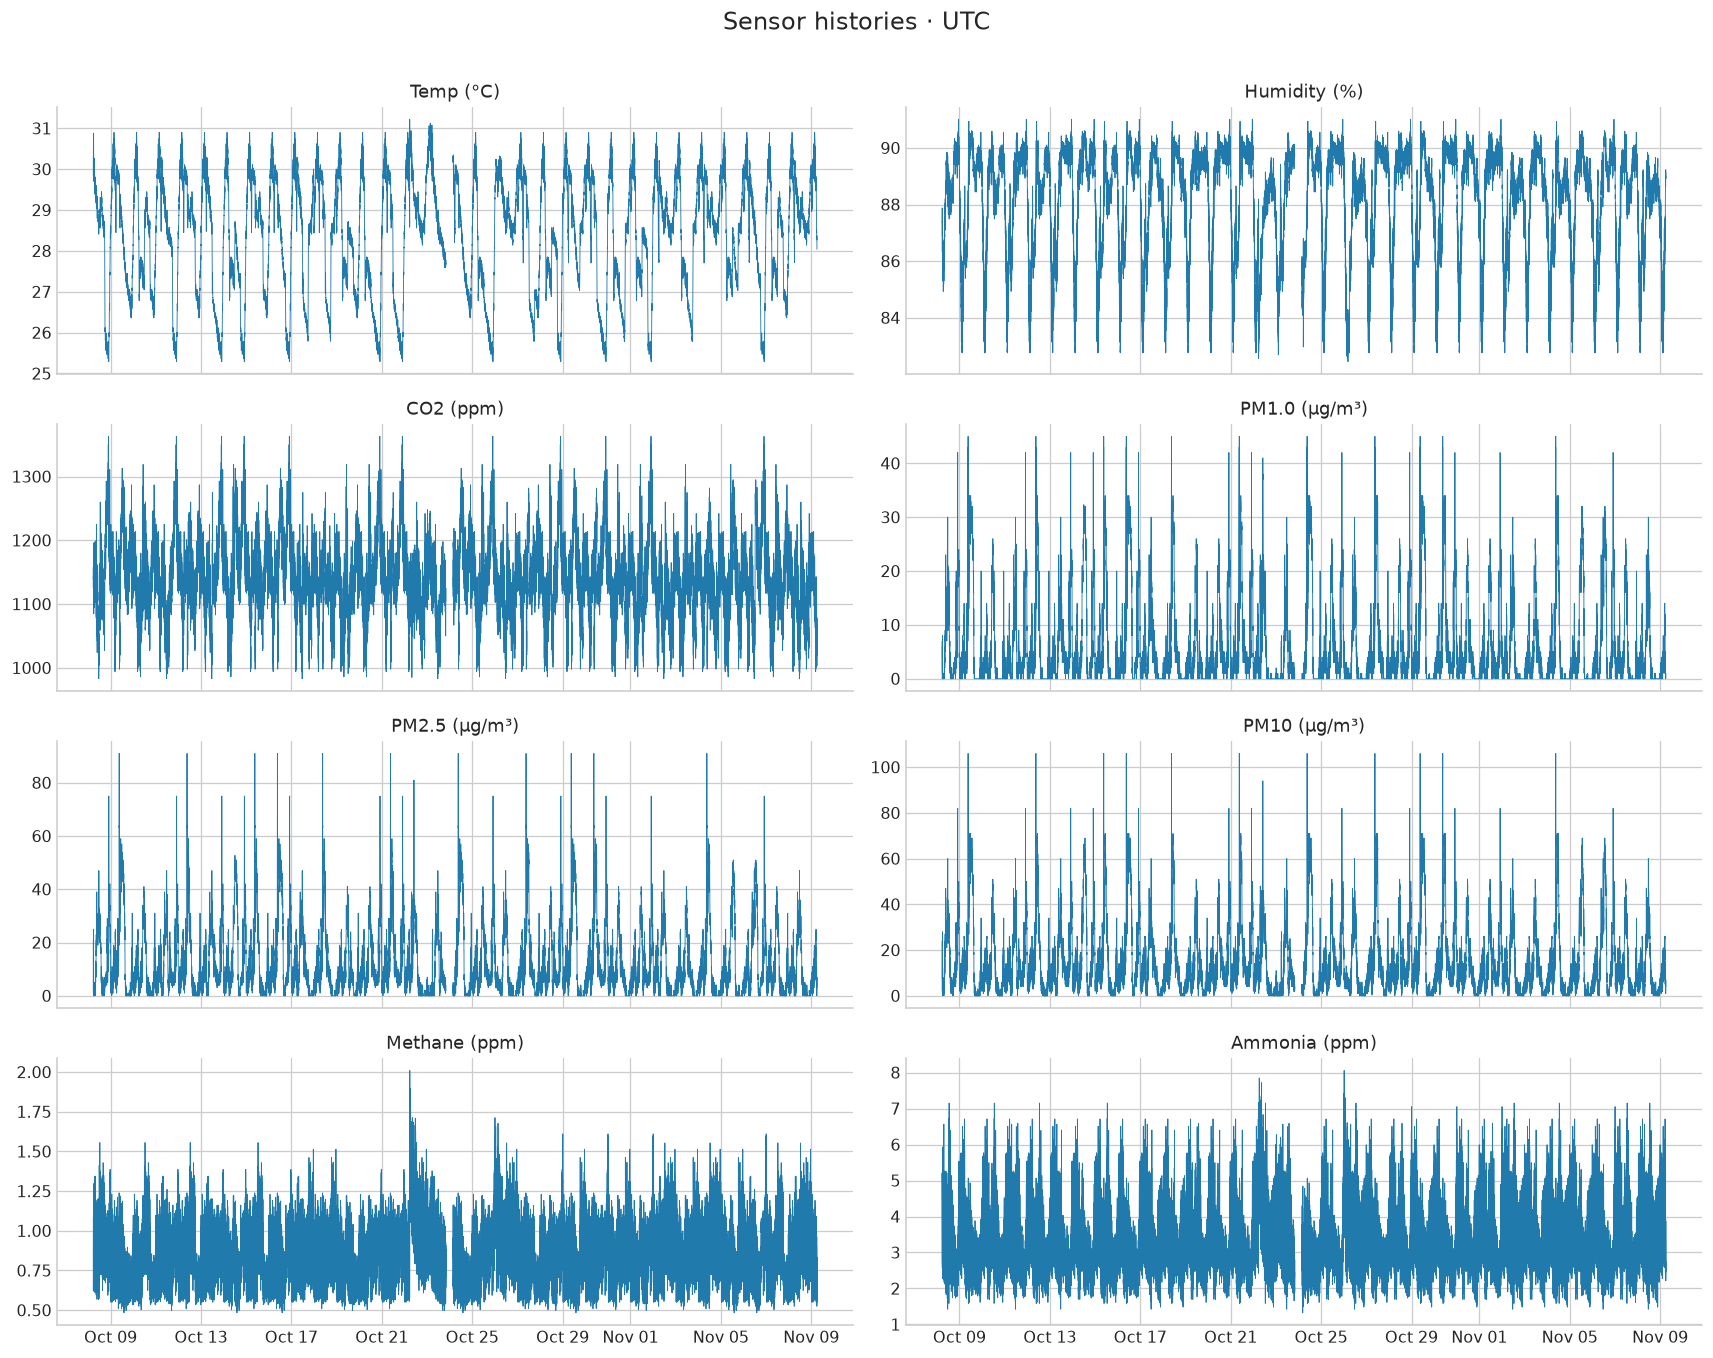

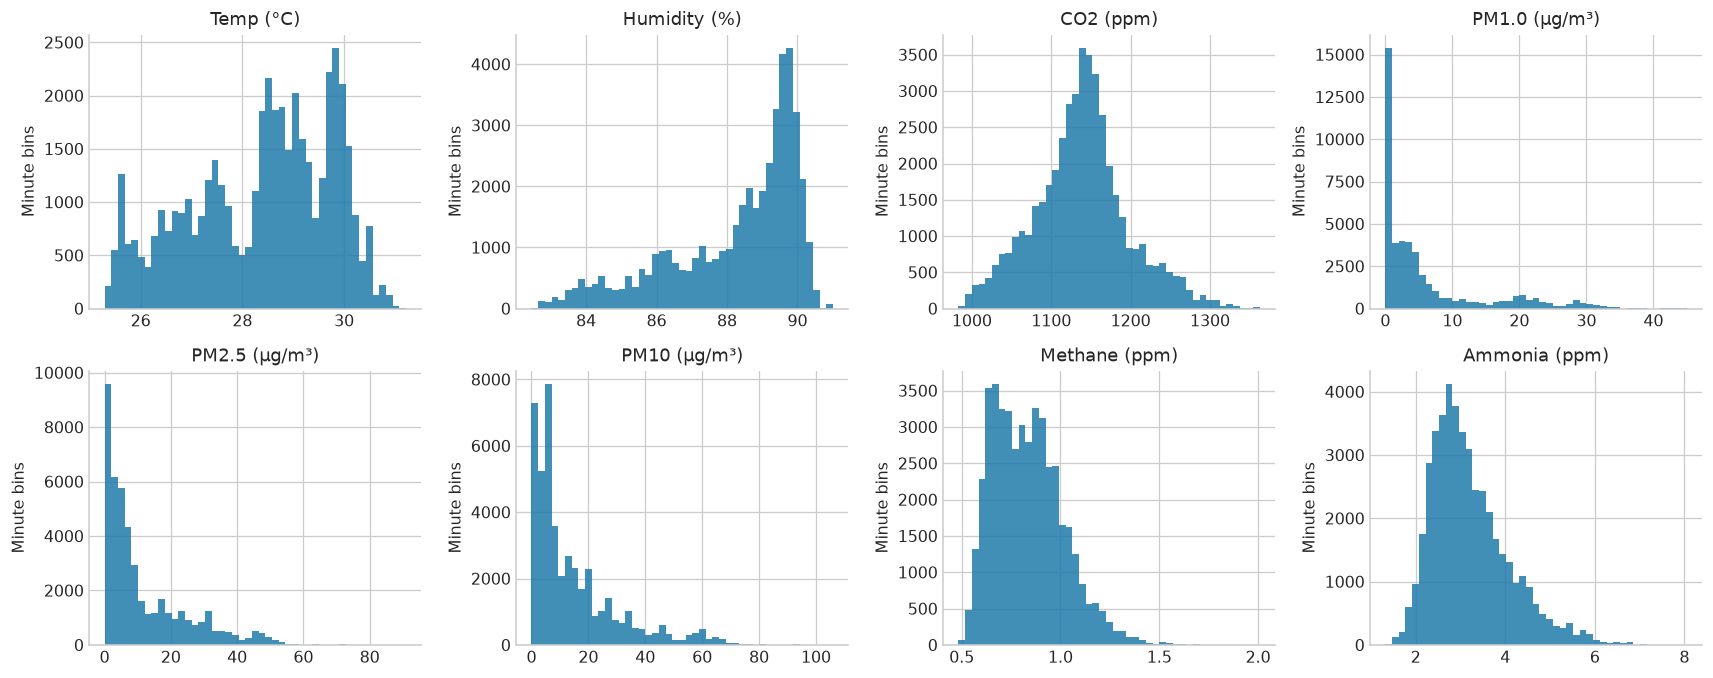

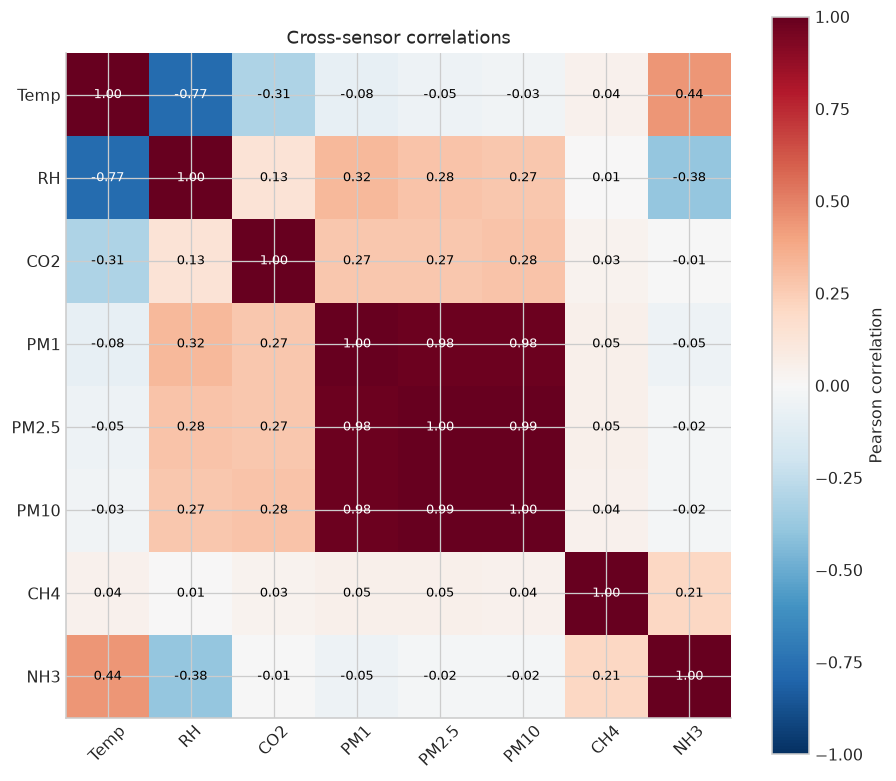

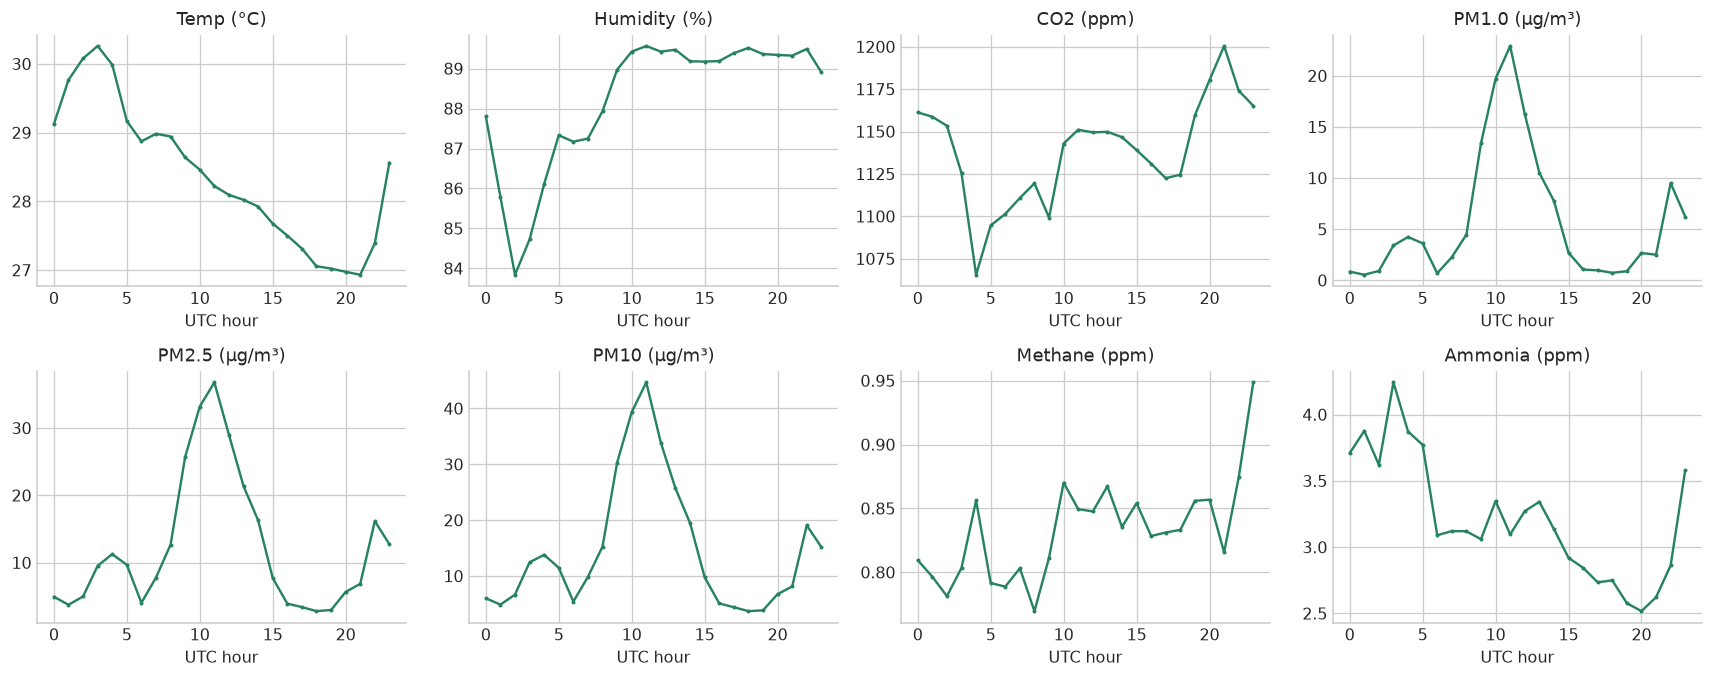

In [ ]:
raw = pd.read_csv(DATA_PATH)
assert raw.shape[1] == 9 and raw.columns[0] == 'Timestamp (UTC)'
timestamps = pd.to_datetime(raw.iloc[:, 0], utc=True, errors='raise')
assert not timestamps.duplicated().any(), 'Duplicate timestamps require resolution.'
SENSORS = list(raw.columns[1:])
SHORT = ['Temp', 'RH', 'CO2', 'PM1', 'PM2.5', 'PM10', 'CH4', 'NH3']
UNITS = ['°C', 'percentage points', 'ppm', 'µg/m³', 'µg/m³', 'µg/m³', 'ppm', 'ppm']
observations = raw.iloc[:, 1:].apply(pd.to_numeric, errors='raise').set_axis(timestamps).sort_index()
assert np.isfinite(observations.to_numpy()).all()
assert observations.resample('1min').size().max() == 1
data = observations.resample('1min').mean()
provenance = json.loads(PROVENANCE_PATH.read_text())
assert provenance['dataset_sha256'] == SOURCE_HASH
blocked = pd.Series(False, index=data.index)
for block in provenance['blocks']:
    start = pd.Timestamp(block['output_start_utc'])
    end = start + pd.Timedelta(minutes=max(1, block['crossfade_minutes']) - 1)
    blocked.loc[start:end] = True
for key in ['source_first_timestamp_utc', 'source_last_timestamp_utc']:
    blocked.loc[pd.Timestamp(provenance[key]).floor('min')] = True
valid = data.notna().all(axis=1)
print(f'{len(observations):,} rows; {len(data):,} minute bins; {(~valid).sum():,} missing minute bins.')
print('UTC coverage:', data.index[0], 'to', data.index[-1])
display(data.describe().T.round(4))
display(data.head(3))

fig, axes = plt.subplots(4, 2, figsize=(15, 12), sharex=True)
for j, ax in enumerate(axes.flat):
    ax.plot(data.index, data.iloc[:, j], lw=.55, color='#207aab')
    ax.set_title(SENSORS[j]); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
fig.suptitle('Sensor histories · UTC', fontsize=15)
fig.tight_layout(rect=[0, 0, 1, .97]); savefig('01_sensor_histories')

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for j, ax in enumerate(axes.flat):
    ax.hist(data.iloc[:, j].dropna(), bins=45, color='#207aab', alpha=.85)
    ax.set_title(SENSORS[j]); ax.set_ylabel('Minute bins')
fig.tight_layout(); savefig('02_distributions')

fig, ax = plt.subplots(figsize=(8, 7))
corr = data.corr().to_numpy()
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(8), SHORT, rotation=45); ax.set_yticks(range(8), SHORT)
for i in range(8):
    for j in range(8):
        ax.text(j, i, f'{corr[i,j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(corr[i,j]) > .65 else 'black')
fig.colorbar(im, ax=ax, label='Pearson correlation'); ax.set_title('Cross-sensor correlations')
fig.tight_layout(); savefig('03_correlations')

hourly = data.groupby(data.index.hour).mean()
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for j, ax in enumerate(axes.flat):
    ax.plot(hourly.index, hourly.iloc[:, j], color='#268263', marker='.', ms=3)
    ax.set_title(SENSORS[j]); ax.set_xlabel('UTC hour')
fig.tight_layout(); savefig('04_hourly_patterns')


## 2. Construct chronological forecast windows
For an origin **t**, input spans **t−119 … t**, while targets span **t+1 … t+120**.
All 240 minute bins must be observed and free of documented transitions.
Targets cannot cross split boundaries. Validation/test inputs can use already
available earlier history. No future sensor values enter the input.

Scaling uses only observations before the training cutoff. Recurrent inputs have
shape `[batch, 120, 10]`; predictions have shape `[batch, 120, 8]`.


,partition,windows,first_origin_utc,last_origin_utc
0,train,11193,2026-10-08 07:36:00+00:00,2026-10-30 10:03:00+00:00
1,validation,1686,2026-10-30 15:31:00+00:00,2026-11-04 08:47:00+00:00
2,test,1729,2026-11-04 14:33:00+00:00,2026-11-09 04:03:00+00:00


Training cutoff: 2026-10-30 15:31:36+00:00 | Validation cutoff: 2026-11-04 10:47:48+00:00


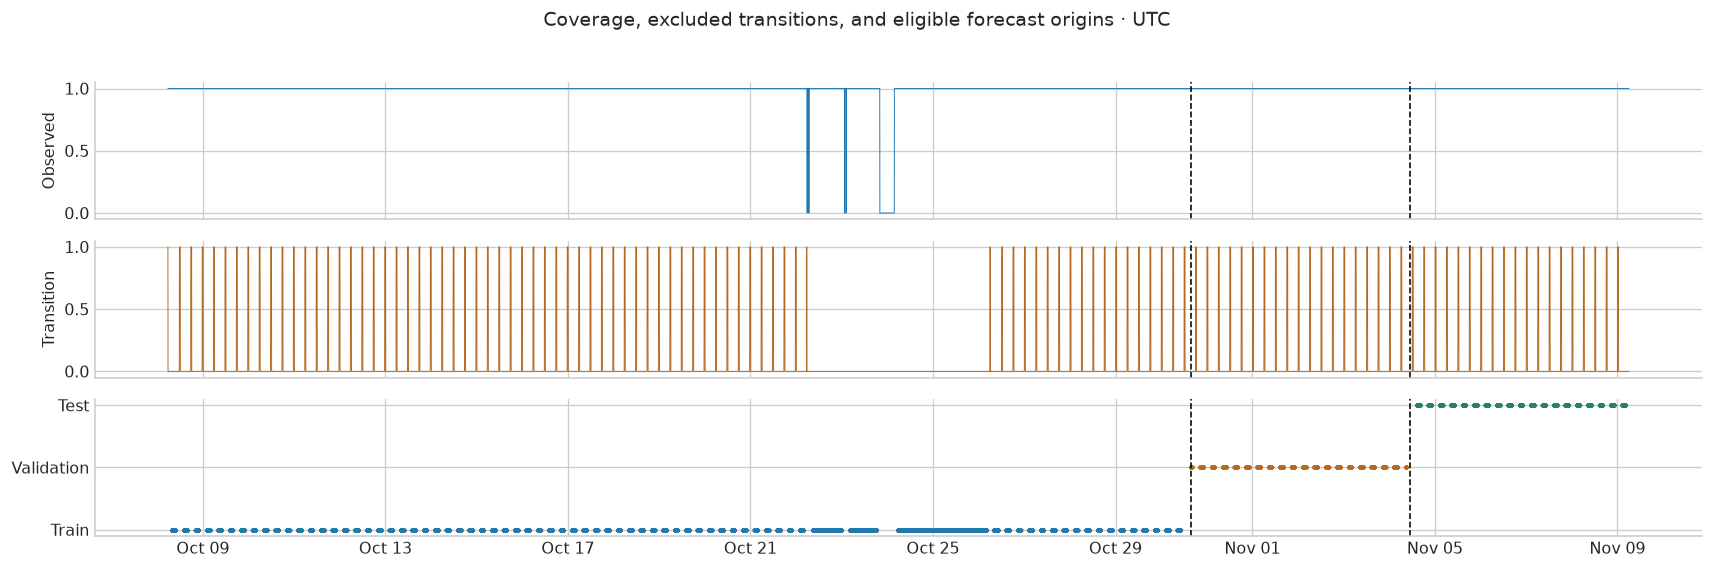

In [ ]:
span = data.index[-1] + pd.Timedelta(minutes=1) - data.index[0]
TRAIN_END = data.index[0] + CONFIG['train_fraction'] * span
VAL_END = data.index[0] + CONFIG['validation_end_fraction'] * span
eligible = (valid & ~blocked).rolling(H + F).sum().shift(-F).eq(H + F)
origin = data.index
first_target, last_target = origin + pd.Timedelta(minutes=1), origin + pd.Timedelta(minutes=F)
masks = {'train': eligible & (last_target < TRAIN_END),
         'validation': eligible & (first_target >= TRAIN_END) & (last_target < VAL_END),
         'test': eligible & (first_target >= VAL_END)}
positions = {k: np.flatnonzero(v.to_numpy()) for k, v in masks.items()}
assert all(len(v) > 0 for v in positions.values())
train_rows = data.loc[data.index < TRAIN_END]
MEAN = train_rows.mean().to_numpy(dtype=np.float32)
STD = train_rows.std(ddof=0).to_numpy(dtype=np.float32)
assert np.isfinite(MEAN).all() and (STD > 0).all()
Z = ((data.to_numpy(dtype=np.float32) - MEAN) / STD).astype(np.float32)
phase = 2*np.pi*(data.index.hour*60 + data.index.minute)/1440
time_features = np.column_stack([np.sin(phase), np.cos(phase)]).astype(np.float32)
INPUTS = np.column_stack([Z, time_features]).astype(np.float32)
split_table = pd.DataFrame([{'partition': k, 'windows': len(v),
                             'first_origin_utc': str(data.index[v[0]]),
                             'last_origin_utc': str(data.index[v[-1]])} for k, v in positions.items()])
display(split_table)
print('Training cutoff:', TRAIN_END, '| Validation cutoff:', VAL_END)

class WindowDataset(Dataset):
    def __init__(self, indices): self.indices = indices
    def __len__(self): return len(self.indices)
    def __getitem__(self, item):
        t = self.indices[item]
        return torch.from_numpy(INPUTS[t-H+1:t+1].copy()), torch.from_numpy(Z[t+1:t+F+1].copy())

generator = torch.Generator().manual_seed(SEED)
loaders = {k: DataLoader(WindowDataset(v), batch_size=CONFIG['batch_size'],
                         shuffle=(k=='train'), generator=generator if k=='train' else None,
                         num_workers=0, pin_memory=True) for k, v in positions.items()}
def targets(indices):
    return np.stack([Z[t+1:t+F+1] for t in indices])
Y = {k: targets(v) for k, v in positions.items()}
LAST = {k: Z[v] for k, v in positions.items()}
def unscale(a): return np.asarray(a)*STD + MEAN
def project(a):
    a = np.array(a, dtype=np.float32, copy=True)
    a[..., 1] = np.clip(a[..., 1], 0, 100)
    a[..., 2:] = np.maximum(a[..., 2:], 0)
    a[..., 3:6] = np.maximum.accumulate(a[..., 3:6], axis=-1)
    return a
def normalized_mse(actual_z, predicted_original):
    return float(np.mean(((predicted_original-MEAN)/STD-actual_z)**2, dtype=np.float64))

fig, axes = plt.subplots(3, 1, figsize=(15, 5), sharex=True)
axes[0].plot(data.index, valid.astype(int), lw=.6); axes[0].set_ylabel('Observed')
axes[1].plot(data.index, blocked.astype(int), lw=.6, color='#b56a22'); axes[1].set_ylabel('Transition')
for label, color in [('train', '#207aab'), ('validation', '#b56a22'), ('test', '#268263')]:
    ix = positions[label]
    axes[2].scatter(data.index[ix], np.full(len(ix), {'train':0,'validation':1,'test':2}[label]),
                    s=2, color=color, label=label)
axes[2].set_yticks([0,1,2], ['Train','Validation','Test'])
for ax in axes:
    ax.axvline(TRAIN_END, color='black', ls='--', lw=1)
    ax.axvline(VAL_END, color='black', ls='--', lw=1)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
fig.suptitle('Coverage, excluded transitions, and eligible forecast origins · UTC')
fig.tight_layout(rect=[0,0,1,.95]); savefig('05_window_coverage')


## 3. Models and fair selection
**Persistence** repeats the most recent reading at every forecast horizon.
**Ridge** uses current readings, lags 15/30/60/119, trailing means/stds over
30/60/120 minutes, and time of day. Its targets are changes from the latest reading.
Alpha is selected from 1, 10, and 100 using validation only.

**GRU** uses two 64-unit recurrent layers and a 128-unit dense head.
**TCN** uses six causal residual blocks (32 channels, two kernel-three convolutions
per block, dilations 1/2/4/8/16/32) and a 128-unit dense head. Both predict changes
from the latest reading, producing all future horizons directly.

Training minimizes normalized MSE. Epoch checkpoints and early stopping use raw
normalized validation MSE. Final candidate selection uses validation MSE after
the **same physical projection** used for every candidate: humidity 0–100%,
nonnegative concentrations, and ordered particulate fractions. This distinction
is recorded in the training histories and leaderboard. The test set does not
select architectures, hyperparameters, checkpoints, or the final winner.

Research motivation: [Zeng et al. (AAAI 2023)](https://arxiv.org/abs/2205.13504)
shows why strong linear alternatives deserve comparison; [Bai et al. (2018)](https://arxiv.org/abs/1803.01271)
motivates comparing convolutional and recurrent sequence models. Neither establishes
a guaranteed winner here. [Time-series evaluation guidance](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html)
explains why ordered evaluation matters.


In [ ]:
validation_predictions, candidate_models, train_seconds = {}, {}, {}
raw_validation_predictions = {}
raw_validation_predictions['Persistence'] = unscale(np.repeat(LAST['validation'][:,None,:], F, axis=1))
validation_predictions['Persistence'] = project(raw_validation_predictions['Persistence'])
train_seconds['Persistence'] = 0.0

def engineered(x):
    # x: standardized sensor values plus time features, oldest to newest.
    pieces = [x[:, -1, :8]]
    pieces += [x[:, -1-lag, :8] for lag in [15,30,60,119]]
    for window in [30,60,120]:
        pieces += [x[:, -window:, :8].mean(axis=1), x[:, -window:, :8].std(axis=1, ddof=0)]
    return np.column_stack(pieces + [x[:, -1, 8:10]]).astype(np.float32)

def input_windows(indices):
    return np.stack([INPUTS[t-H+1:t+1] for t in indices])

class GRUForecaster(nn.Module):
    def __init__(self):
        super().__init__()
        self.horizon = 120
        self.gru = nn.GRU(10,64,num_layers=2,dropout=.1,batch_first=True)
        self.head = nn.Sequential(nn.Linear(64,128),nn.ReLU(),nn.Linear(128,self.horizon*8))
    def forward(self,x):
        _, state = self.gru(x)
        return self.head(state[-1]).reshape(-1,self.horizon,8)+x[:,-1,None,:8]

class CausalConv(nn.Module):
    def __init__(self, channels_in, channels_out, dilation):
        super().__init__()
        self.padding = 2*dilation
        self.conv = nn.Conv1d(channels_in,channels_out,3,dilation=dilation)
    def forward(self,x):
        return self.conv(nn.functional.pad(x,(self.padding,0)))

class ResidualBlock(nn.Module):
    def __init__(self, channels_in, dilation):
        super().__init__()
        self.body = nn.Sequential(CausalConv(channels_in,32,dilation),nn.ReLU(),nn.Dropout(.1),
                                  CausalConv(32,32,dilation),nn.ReLU(),nn.Dropout(.1))
        self.skip = nn.Conv1d(channels_in,32,1) if channels_in != 32 else nn.Identity()
    def forward(self,x): return nn.functional.relu(self.body(x)+self.skip(x))

class TCNForecaster(nn.Module):
    def __init__(self):
        super().__init__()
        self.horizon = 120
        self.blocks = nn.Sequential(*[ResidualBlock(10 if i==0 else 32,d) for i,d in enumerate([1,2,4,8,16,32])])
        self.head = nn.Sequential(nn.Linear(32,128),nn.ReLU(),nn.Linear(128,self.horizon*8))
    def forward(self,x):
        state = self.blocks(x.transpose(1,2))[:,:,-1]
        return self.head(state).reshape(-1,self.horizon,8)+x[:,-1,None,:8]

def neural_predictions(model, loader, device=DEVICE):
    model.eval()
    chunks = []
    with torch.inference_mode():
        for x,_ in loader:
            chunks.append(model(x.to(device, non_blocking=True)).float().cpu().numpy())
    return np.concatenate(chunks)

def train_neural(name, model_class):
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    generator.manual_seed(SEED)
    model = model_class().to(DEVICE)
    print(name, 'parameters:', f'{sum(p.numel() for p in model.parameters()):,}')
    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=CONFIG['weight_decay'])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=.5, patience=CONFIG['lr_patience'])
    scaler = torch.amp.GradScaler('cuda')
    best, best_state, stale, rows = np.inf, None, 0, []
    started = time.perf_counter()
    for epoch in range(1, CONFIG['max_epochs']+1):
        epoch_start = time.perf_counter()
        model.train(); total_se=total_ae=total_count=0
        for x,y in loaders['train']:
            x,y = x.to(DEVICE,non_blocking=True), y.to(DEVICE,non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda',dtype=torch.float16):
                prediction = model(x)
                loss = nn.functional.mse_loss(prediction,y)
            if not torch.isfinite(loss): raise FloatingPointError(f'{name}: nonfinite training loss')
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(),CONFIG['gradient_clip'])
            scaler.step(optimizer); scaler.update()
            error = prediction.detach().float()-y
            total_se += error.square().sum().item(); total_ae += error.abs().sum().item(); total_count += error.numel()
        validation_z = neural_predictions(model,loaders['validation'])
        residual = validation_z-Y['validation']
        val_mse = float(np.mean(residual**2,dtype=np.float64))
        val_mae = float(np.mean(np.abs(residual),dtype=np.float64))
        if not np.isfinite(val_mse): raise FloatingPointError(f'{name}: nonfinite validation loss')
        improved = val_mse < best-1e-8
        if improved:
            best, stale = val_mse, 0
            best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else: stale += 1
        lr = optimizer.param_groups[0]['lr']
        scheduler.step(val_mse)
        rows.append(dict(epoch=epoch, train_mse=total_se/total_count, train_mae=total_ae/total_count,
                         validation_mse=val_mse, validation_mae=val_mae, learning_rate=lr,
                         seconds=time.perf_counter()-epoch_start, is_new_best=improved))
        pd.DataFrame(rows).to_csv(RESULTS/f'{name.lower()}_training_history.csv',index=False)
        print(f'{name} epoch {epoch:02d}: train MSE={rows[-1]["train_mse"]:.4f}; validation MSE={val_mse:.4f}; {rows[-1]["seconds"]:.1f}s',flush=True)
        if stale >= CONFIG['early_stopping_patience']:
            print('Early stopping; restoring best validation checkpoint.'); break
    model.load_state_dict(best_state)
    candidate_models[name] = model
    raw_validation_predictions[name] = unscale(neural_predictions(model,loaders['validation']))
    validation_predictions[name] = project(raw_validation_predictions[name])
    train_seconds[name] = time.perf_counter()-started
    return pd.DataFrame(rows)


In [ ]:
X_RIDGE = {k: engineered(input_windows(positions[k])) for k in ['train','validation']}
ridge_target = (Y['train']-LAST['train'][:,None,:]).reshape(len(Y['train']), -1)
ridge_trials, ridge_best, ridge_best_score = [], None, np.inf
started = time.perf_counter()
for alpha in CONFIG['ridge_alphas']:
    fitted = make_pipeline(StandardScaler(), Ridge(alpha=alpha, solver='cholesky'))
    fitted.fit(X_RIDGE['train'], ridge_target)
    raw_prediction = unscale(fitted.predict(X_RIDGE['validation']).reshape(-1,F,8) + LAST['validation'][:,None,:])
    prediction = project(raw_prediction)
    score = normalized_mse(Y['validation'], prediction)
    ridge_trials.append({'alpha':alpha, 'validation_normalized_mse':score})
    if score < ridge_best_score:
        ridge_best_score, ridge_best = score, fitted
        raw_validation_predictions['Ridge'] = raw_prediction
        validation_predictions['Ridge'] = prediction
candidate_models['Ridge'] = ridge_best
train_seconds['Ridge'] = time.perf_counter()-started
display(pd.DataFrame(ridge_trials))
pd.DataFrame(ridge_trials).to_csv(RESULTS/'ridge_validation_trials.csv', index=False)



**Saved completed-run results.** Restored from retained run artifacts; training was not rerun.

alpha,validation_normalized_mse
1,0.249282
10,0.255504
100,0.269056


## 4. Train on the GPU
These two cells perform the neural training. Histories are saved after every
epoch. GPU runs with a fixed seed are reproducible within normal numerical
tolerances; bit-for-bit results across different CUDA versions are not guaranteed.


In [ ]:
gru_history = train_neural('GRU', GRUForecaster)


**Saved completed-run results.** Restored from retained run artifacts; training was not rerun.

GRU: recorded training history (60 completed epochs)
epoch 01: train MSE=0.624135; validation MSE=0.507056; validation MAE=0.468636; time=1.155s
epoch 02: train MSE=0.450443; validation MSE=0.364629; validation MAE=0.402365; time=0.531s
epoch 03: train MSE=0.352632; validation MSE=0.306470; validation MAE=0.372243; time=0.544s
epoch 04: train MSE=0.312566; validation MSE=0.288224; validation MAE=0.360362; time=0.536s
epoch 05: train MSE=0.290302; validation MSE=0.275148; validation MAE=0.352209; time=0.581s
epoch 06: train MSE=0.275071; validation MSE=0.263182; validation MAE=0.341041; time=0.576s
epoch 07: train MSE=0.263219; validation MSE=0.255368; validation MAE=0.333591; time=0.562s
epoch 08: train MSE=0.254694; validation MSE=0.246915; validation MAE=0.328244; time=0.551s
epoch 09: train MSE=0.247104; validation MSE=0.240367; validation MAE=0.320774; time=0.567s
epoch 10: train MSE=0.241801; validation MSE=0.233656; validation MAE=0.316219; time=0.571s
epoch 11: train MSE=0.23658

In [ ]:
tcn_history = train_neural('TCN', TCNForecaster)


**Saved completed-run results.** Restored from retained run artifacts; training was not rerun.

TCN: recorded training history (60 completed epochs)
epoch 01: train MSE=0.570417; validation MSE=0.352171; validation MAE=0.406080; time=22.354s
epoch 02: train MSE=0.350769; validation MSE=0.304146; validation MAE=0.371447; time=21.555s
epoch 03: train MSE=0.313626; validation MSE=0.285962; validation MAE=0.358415; time=21.622s
epoch 04: train MSE=0.293514; validation MSE=0.273229; validation MAE=0.352394; time=21.684s
epoch 05: train MSE=0.279677; validation MSE=0.263393; validation MAE=0.342557; time=21.567s
epoch 06: train MSE=0.269528; validation MSE=0.253877; validation MAE=0.330960; time=21.523s
epoch 07: train MSE=0.261586; validation MSE=0.248076; validation MAE=0.325972; time=21.480s
epoch 08: train MSE=0.255514; validation MSE=0.241122; validation MAE=0.321600; time=21.586s
epoch 09: train MSE=0.250052; validation MSE=0.236608; validation MAE=0.315935; time=21.616s
epoch 10: train MSE=0.245590; validation MSE=0.232212; validation MAE=0.312438; time=21.628s
epoch 11: train M

**Saved completed-run results.** Restored from retained run artifacts; training was not rerun.

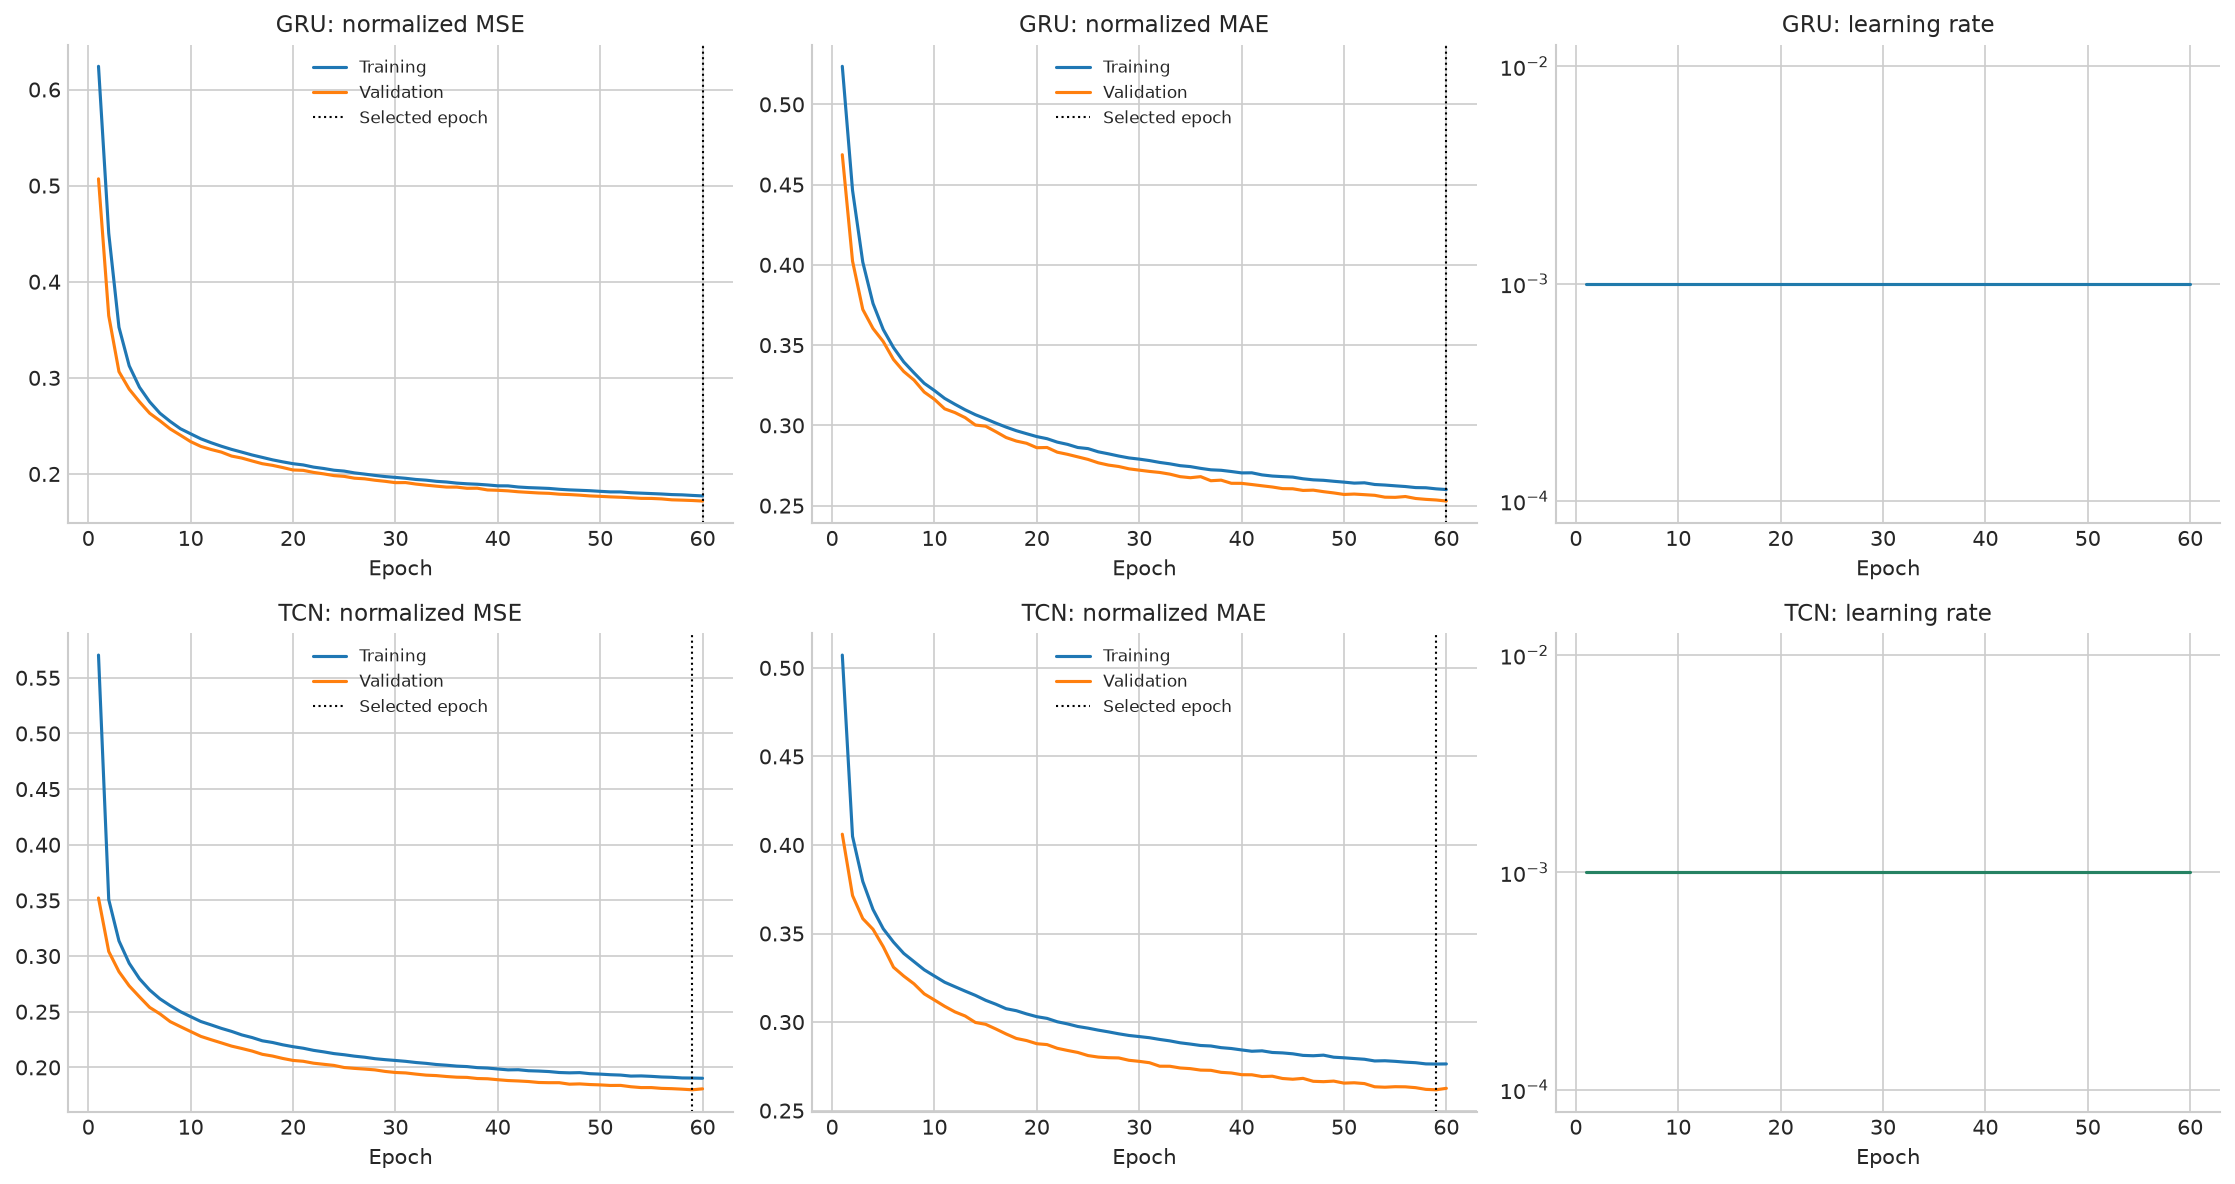

model,validation_normalized_mse,validation_normalized_mae,training_seconds
GRU,0.171678,0.251539,33.4508
TCN,0.179771,0.261061,1296.69
Ridge,0.249282,0.329932,0.289955
Persistence,0.788327,0.593655,0


**Validation-selected winner: GRU.** Selection was frozen before test evaluation.

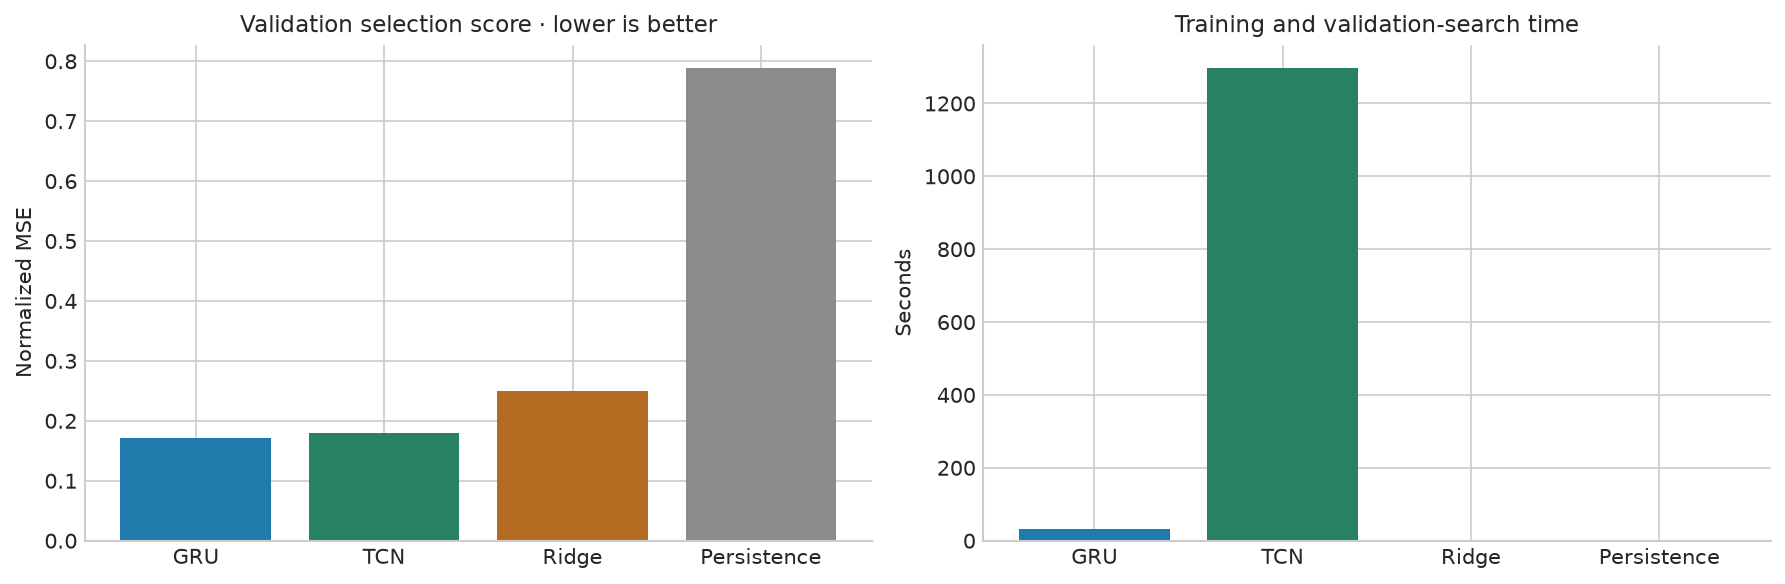

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row,(name,history) in enumerate([('GRU',gru_history),('TCN',tcn_history)]):
    for col,metric in enumerate(['mse','mae']):
        ax=axes[row,col]
        ax.plot(history.epoch,history[f'train_{metric}'],label='Training')
        ax.plot(history.epoch,history[f'validation_{metric}'],label='Validation')
        best_epoch=int(history.loc[history.validation_mse.idxmin(),'epoch'])
        ax.axvline(best_epoch,color='black',ls=':',lw=1,label='Selected epoch')
        ax.set_title(f'{name}: normalized {metric.upper()}');ax.set_xlabel('Epoch');ax.legend(fontsize=8)
    axes[row,2].plot(history.epoch,history.learning_rate,color=COLORS[name])
    axes[row,2].set_title(f'{name}: learning rate');axes[row,2].set_xlabel('Epoch');axes[row,2].set_yscale('log')
fig.tight_layout();savefig('06_training_curves')

leaderboard = pd.DataFrame([dict(model=name,
    validation_normalized_mse=normalized_mse(Y['validation'],prediction),
    validation_normalized_mae=float(np.mean(np.abs((prediction-MEAN)/STD-Y['validation']),dtype=np.float64)),
    training_seconds=train_seconds[name]) for name,prediction in validation_predictions.items()])
leaderboard=leaderboard.sort_values(['validation_normalized_mse','model']).reset_index(drop=True)
WINNER=leaderboard.iloc[0]['model']
selection=dict(winner=WINNER,selection_rule='Minimum projected validation MSE, normalized per sensor; equal sensor/horizon weights.',
               train_end_utc=str(TRAIN_END),validation_end_utc=str(VAL_END),
               leaderboard=leaderboard.to_dict('records'),test_used_for_selection=False)
(RESULTS/'selection.json').write_text(json.dumps(selection,indent=2))
leaderboard.to_csv(RESULTS/'validation_leaderboard.csv',index=False)
display(leaderboard.round(5))
display(Markdown(f'**Locked validation-selected winner: {WINNER}.** The test set is evaluated next; this choice will not be changed.'))

fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(leaderboard.model,leaderboard.validation_normalized_mse,color=[COLORS[x] for x in leaderboard.model])
axes[0].set_title('Validation selection score · lower is better');axes[0].set_ylabel('Normalized MSE')
axes[1].bar(leaderboard.model,leaderboard.training_seconds,color=[COLORS[x] for x in leaderboard.model])
axes[1].set_title('Training and validation-search time');axes[1].set_ylabel('Seconds')
fig.tight_layout();savefig('07_validation_selection')


## 5. Final test evaluation
For actual targets \(y\), forecasts \(\hat y\), and \(n\) examples:

\[
R^2=1-\frac{\sum(y-\hat y)^2}{\sum(y-\bar y)^2},\qquad
RMSE=\sqrt{\frac1n\sum(y-\hat y)^2},\qquad
MAE=\frac1n\sum|y-\hat y|.
\]

R² can be negative; it is undefined for a constant target. R² is not simply a
correlation coefficient. RMSE and MAE use sensor units; humidity errors are
percentage points. All-horizon summaries flatten origins and horizons **within
each sensor**. The same future time can occur in multiple overlapping forecasts:
these are forecast evaluations, not independent observations or confidence samples.
No pooled MAE/RMSE mixes different sensor units.

All candidates below were locked using training/validation only. Comparing their
test scores does not change the exported winner. A negative improvement percentage
means deterioration against persistence.


In [ ]:
actual_test=unscale(Y['test'])
X_TEST=engineered(input_windows(positions['test']))
raw_test_predictions={'Persistence':unscale(np.repeat(LAST['test'][:,None,:],F,axis=1))}
raw_test_predictions['Ridge']=unscale(candidate_models['Ridge'].predict(X_TEST).reshape(-1,F,8)+LAST['test'][:,None,:])
for name in ['GRU','TCN']:
    raw_test_predictions[name]=unscale(neural_predictions(candidate_models[name],loaders['test']))
test_predictions={name:project(prediction) for name,prediction in raw_test_predictions.items()}

def metric_values(y,p):
    y,p=np.asarray(y,dtype=np.float64),np.asarray(p,dtype=np.float64)
    error=p-y
    mae=float(np.mean(np.abs(error)));rmse=float(np.sqrt(np.mean(error**2)))
    denominator=float(np.sum((y-y.mean())**2))
    r2=float(1-np.sum(error**2)/denominator) if denominator>1e-12 else np.nan
    return dict(r2=r2,rmse=rmse,mae=mae)

rows=[];summary_rows=[];raw_rows=[]
for name,prediction in test_predictions.items():
    for j,sensor in enumerate(SENSORS):
        for lead in range(F):
            rows.append(dict(model=name,sensor=sensor,horizon_minutes=lead+1,
                             **metric_values(actual_test[:,lead,j],prediction[:,lead,j])))
        summary_rows.append(dict(model=name,sensor=sensor,units=UNITS[j],
                                 **metric_values(actual_test[:,:,j].ravel(),prediction[:,:,j].ravel())))
        raw_rows.append(dict(model=name,sensor=sensor,horizon_minutes=120,
                             **metric_values(actual_test[:,-1,j],raw_test_predictions[name][:,-1,j])))
metrics=pd.DataFrame(rows)
summary_metrics=pd.DataFrame(summary_rows)
endpoint=metrics[metrics.horizon_minutes==120].copy()
baseline=endpoint[endpoint.model=='Persistence'].set_index('sensor')
for metric in ['mae','rmse']:
    denom=endpoint.sensor.map(baseline[metric]).to_numpy()
    endpoint[f'{metric}_improvement_percent']=np.divide(100*(denom-endpoint[metric].to_numpy()),denom,
                                                       out=np.full(len(endpoint),np.nan),where=denom!=0)
endpoint['r2_above_075']=endpoint.r2>.75
endpoint['validation_selected']=endpoint.model.eq(WINNER)
metrics.to_csv(RESULTS/'metrics_by_horizon.csv',index=False)
summary_metrics.to_csv(RESULTS/'metrics_all_horizons.csv',index=False)
endpoint.to_csv(RESULTS/'metrics_at_120_minutes.csv',index=False)
pd.DataFrame(raw_rows).to_csv(RESULTS/'raw_metrics_at_120_minutes.csv',index=False)
display(Markdown('### Exactly two hours ahead: all locked candidates'))
display(endpoint.round(4).reset_index(drop=True))
display(Markdown(f'### {WINNER}: per-sensor summary over all 120 horizons'))
display(summary_metrics[summary_metrics.model==WINNER].round(4).reset_index(drop=True))
np.savez_compressed(RESULTS/'test_predictions.npz',actual=actual_test,
                    origin_utc_ns=data.index[positions['test']].asi8,
                    **{f'projected_{k}':v for k,v in test_predictions.items()},
                    **{f'raw_{k}':v for k,v in raw_test_predictions.items()})


**Saved completed-run results.** Restored from retained run artifacts; training was not rerun.

### Exactly +120 minutes: all locked candidates

model,sensor,horizon_minutes,r2,rmse,mae,mae_improvement_percent,rmse_improvement_percent,r2_above_075,validation_selected
Persistence,Temp (°C),120,-0.0582433,1.02256,0.795651,0,0,False,False
Persistence,Humidity (%),120,-1.90601,1.83338,1.30447,0,0,False,False
Persistence,CO2 (ppm),120,-0.78597,76.6241,63.7386,0,0,False,False
Persistence,PM1.0 (µg/m³),120,0.00344036,8.13322,5.0214,0,0,False,False
Persistence,PM2.5 (µg/m³),120,0.117091,11.9601,8.08791,0,0,False,False
Persistence,PM10 (µg/m³),120,0.107131,13.8826,9.4199,0,0,False,False
Persistence,Methane (ppm),120,-0.506482,0.224841,0.175564,0,0,False,False
Persistence,Ammonia (ppm),120,-0.609004,1.06495,0.814598,0,0,False,False
Ridge,Temp (°C),120,0.932921,0.257447,0.190336,76.078,74.8232,True,False
Ridge,Humidity (%),120,0.850886,0.415302,0.33217,74.5359,77.3478,True,False


### Selected model: all-horizon per-sensor summary

model,sensor,units,r2,rmse,mae
GRU,Temp (°C),°C,0.991505,0.112242,0.0887236
GRU,Humidity (%),percentage points,0.967076,0.293448,0.226339
GRU,CO2 (ppm),ppm,0.808368,25.2511,18.9759
GRU,PM1.0 (µg/m³),µg/m³,0.95802,1.41228,0.877194
GRU,PM2.5 (µg/m³),µg/m³,0.958969,2.24435,1.60644
GRU,PM10 (µg/m³),µg/m³,0.955812,2.64041,1.90627
GRU,Methane (ppm),ppm,0.388802,0.138062,0.110702
GRU,Ammonia (ppm),ppm,0.490176,0.641493,0.498103


**Saved completed-run results.** Restored from retained run artifacts; training was not rerun.

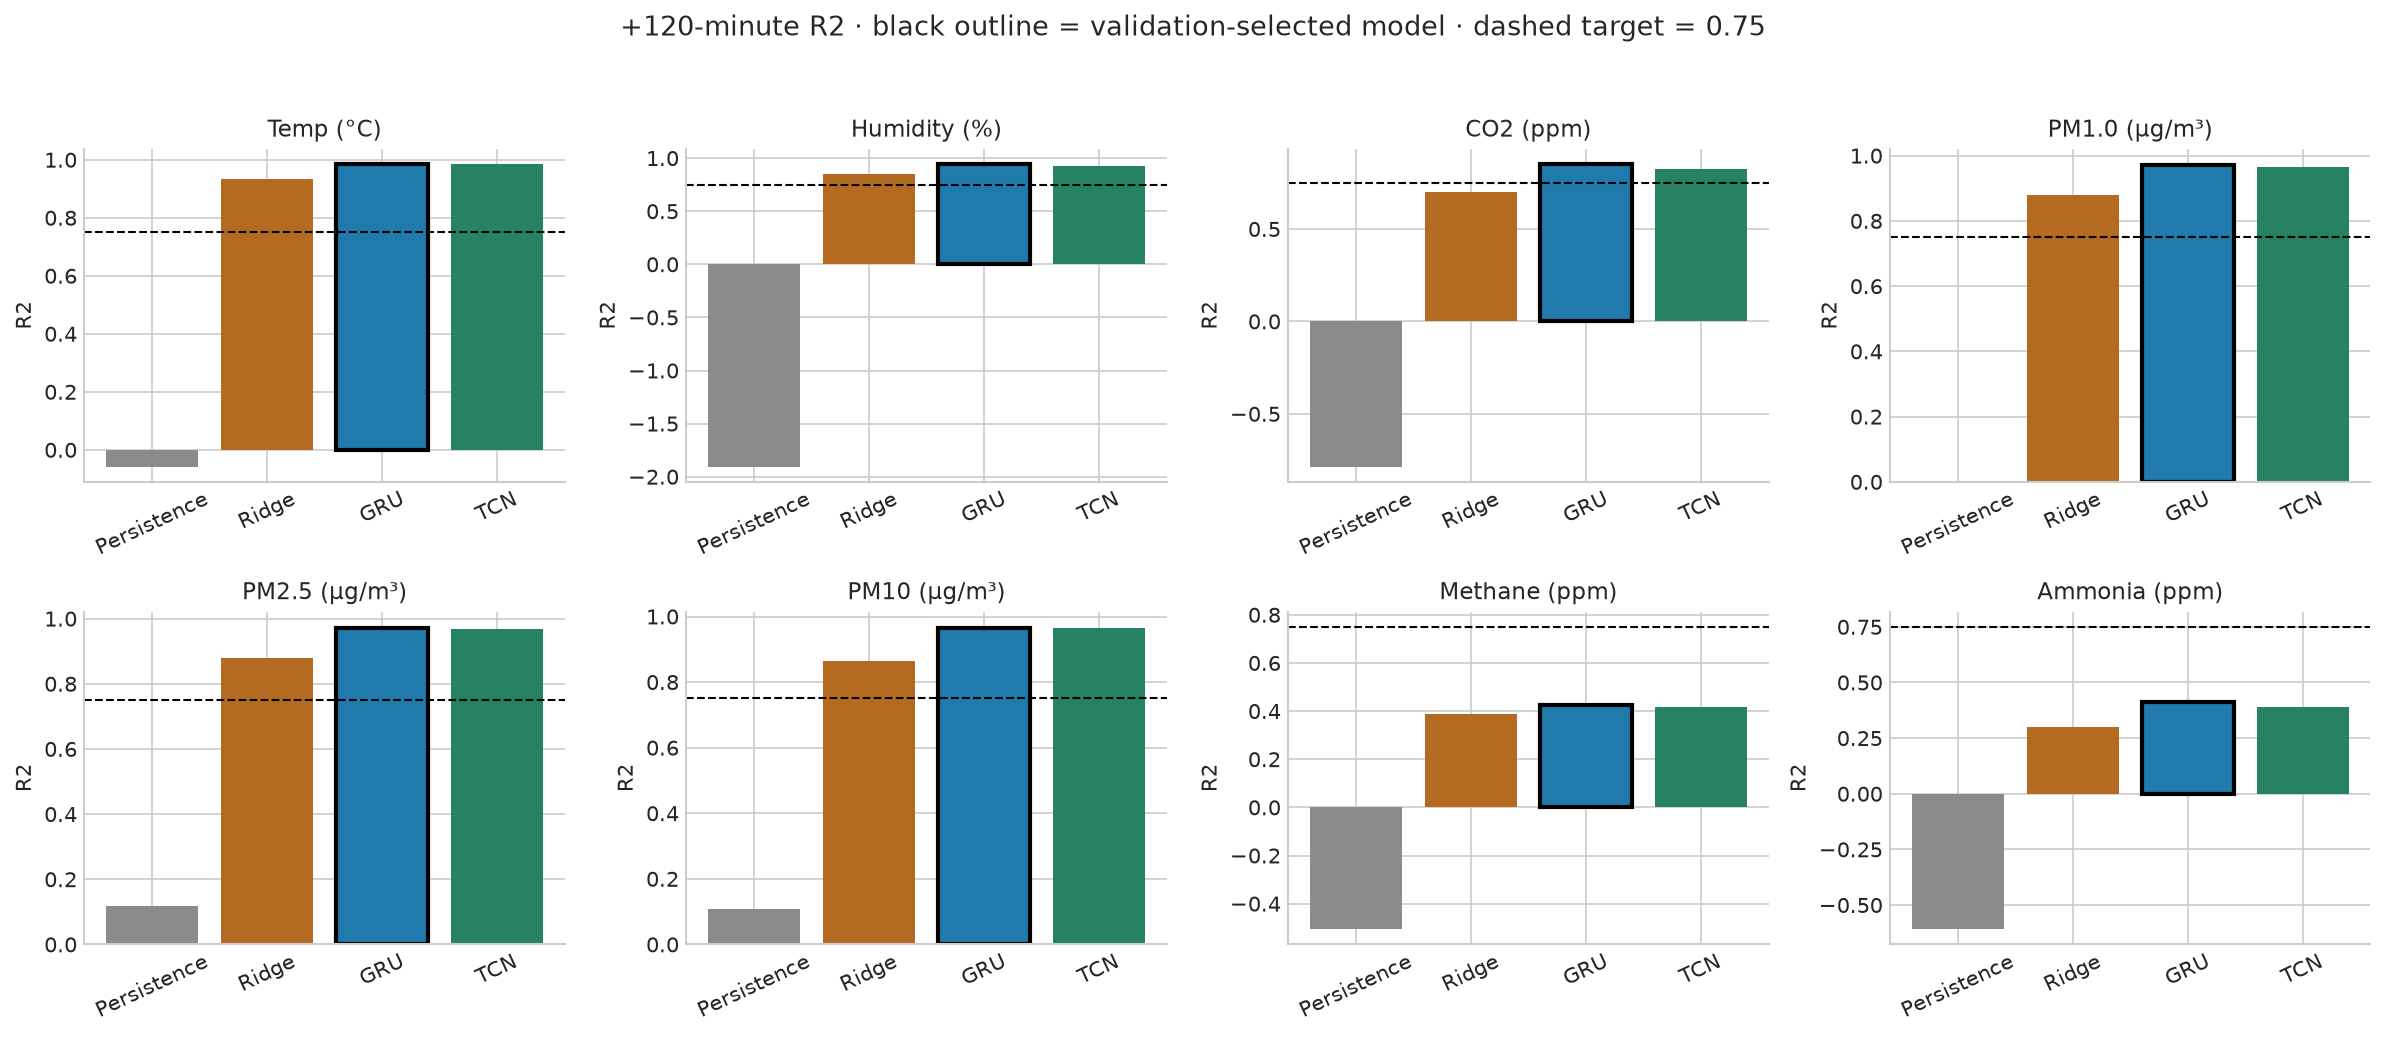

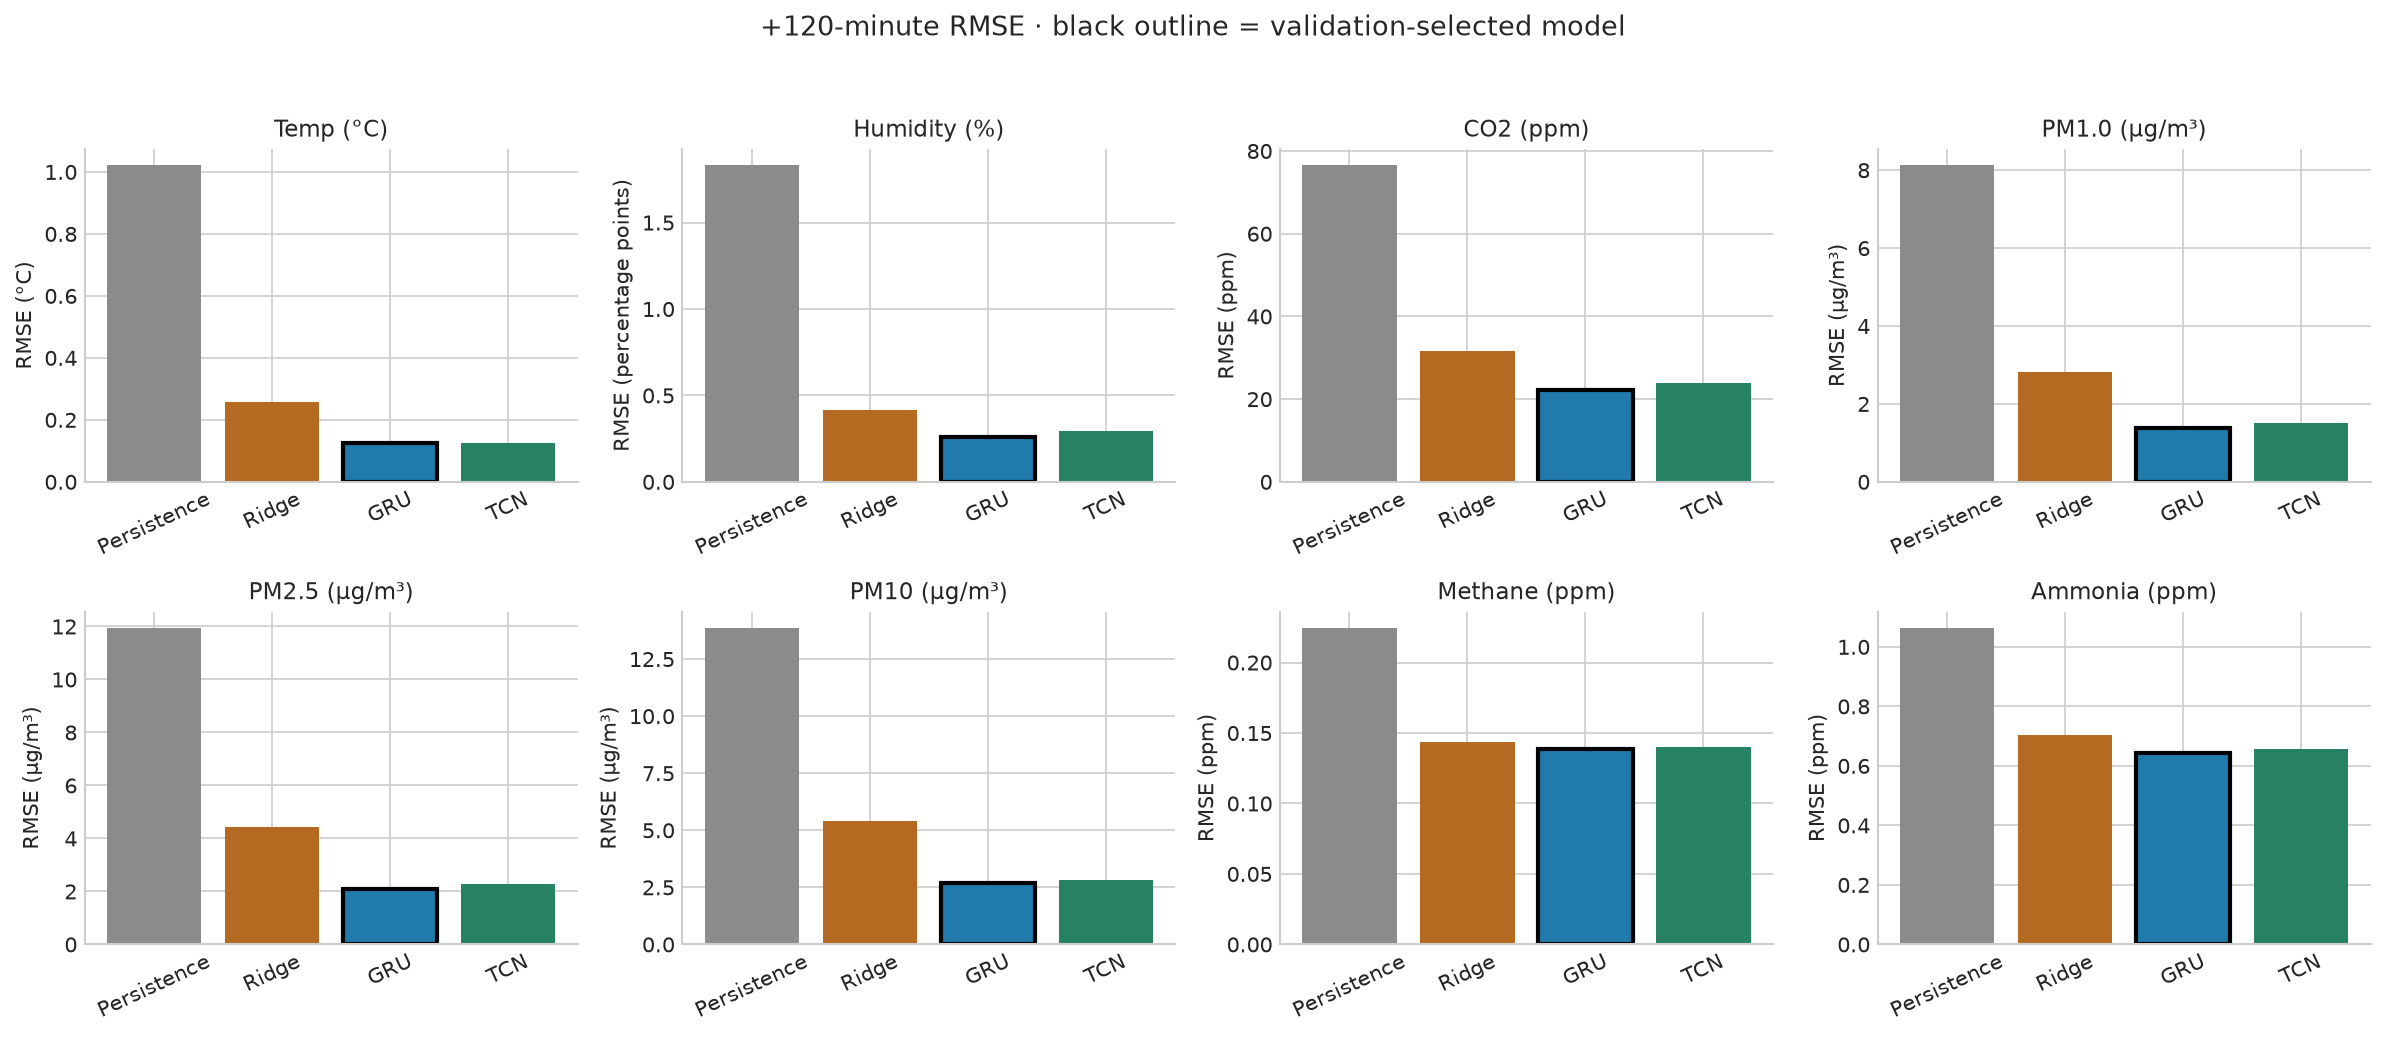

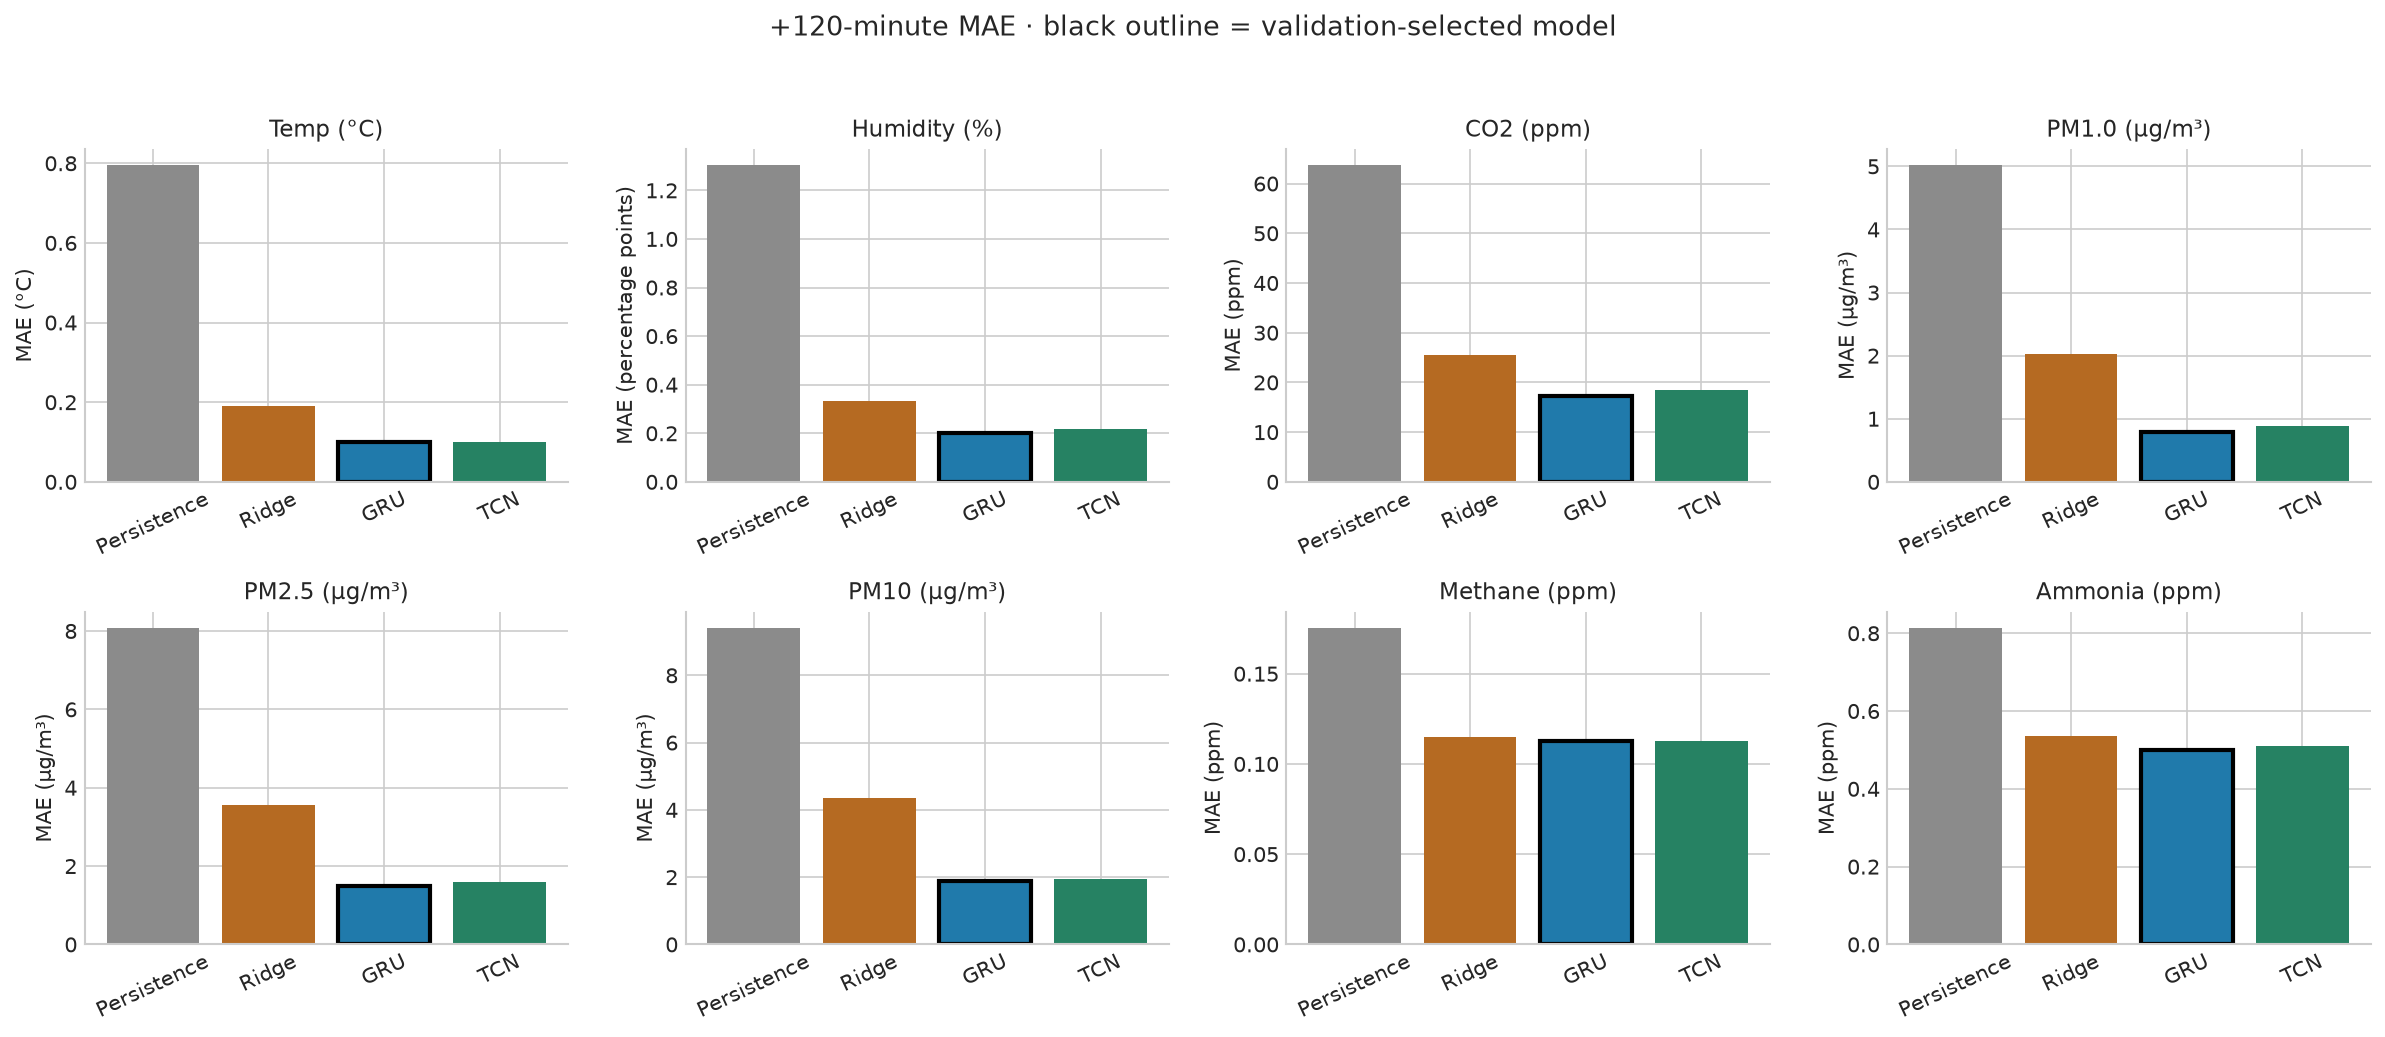

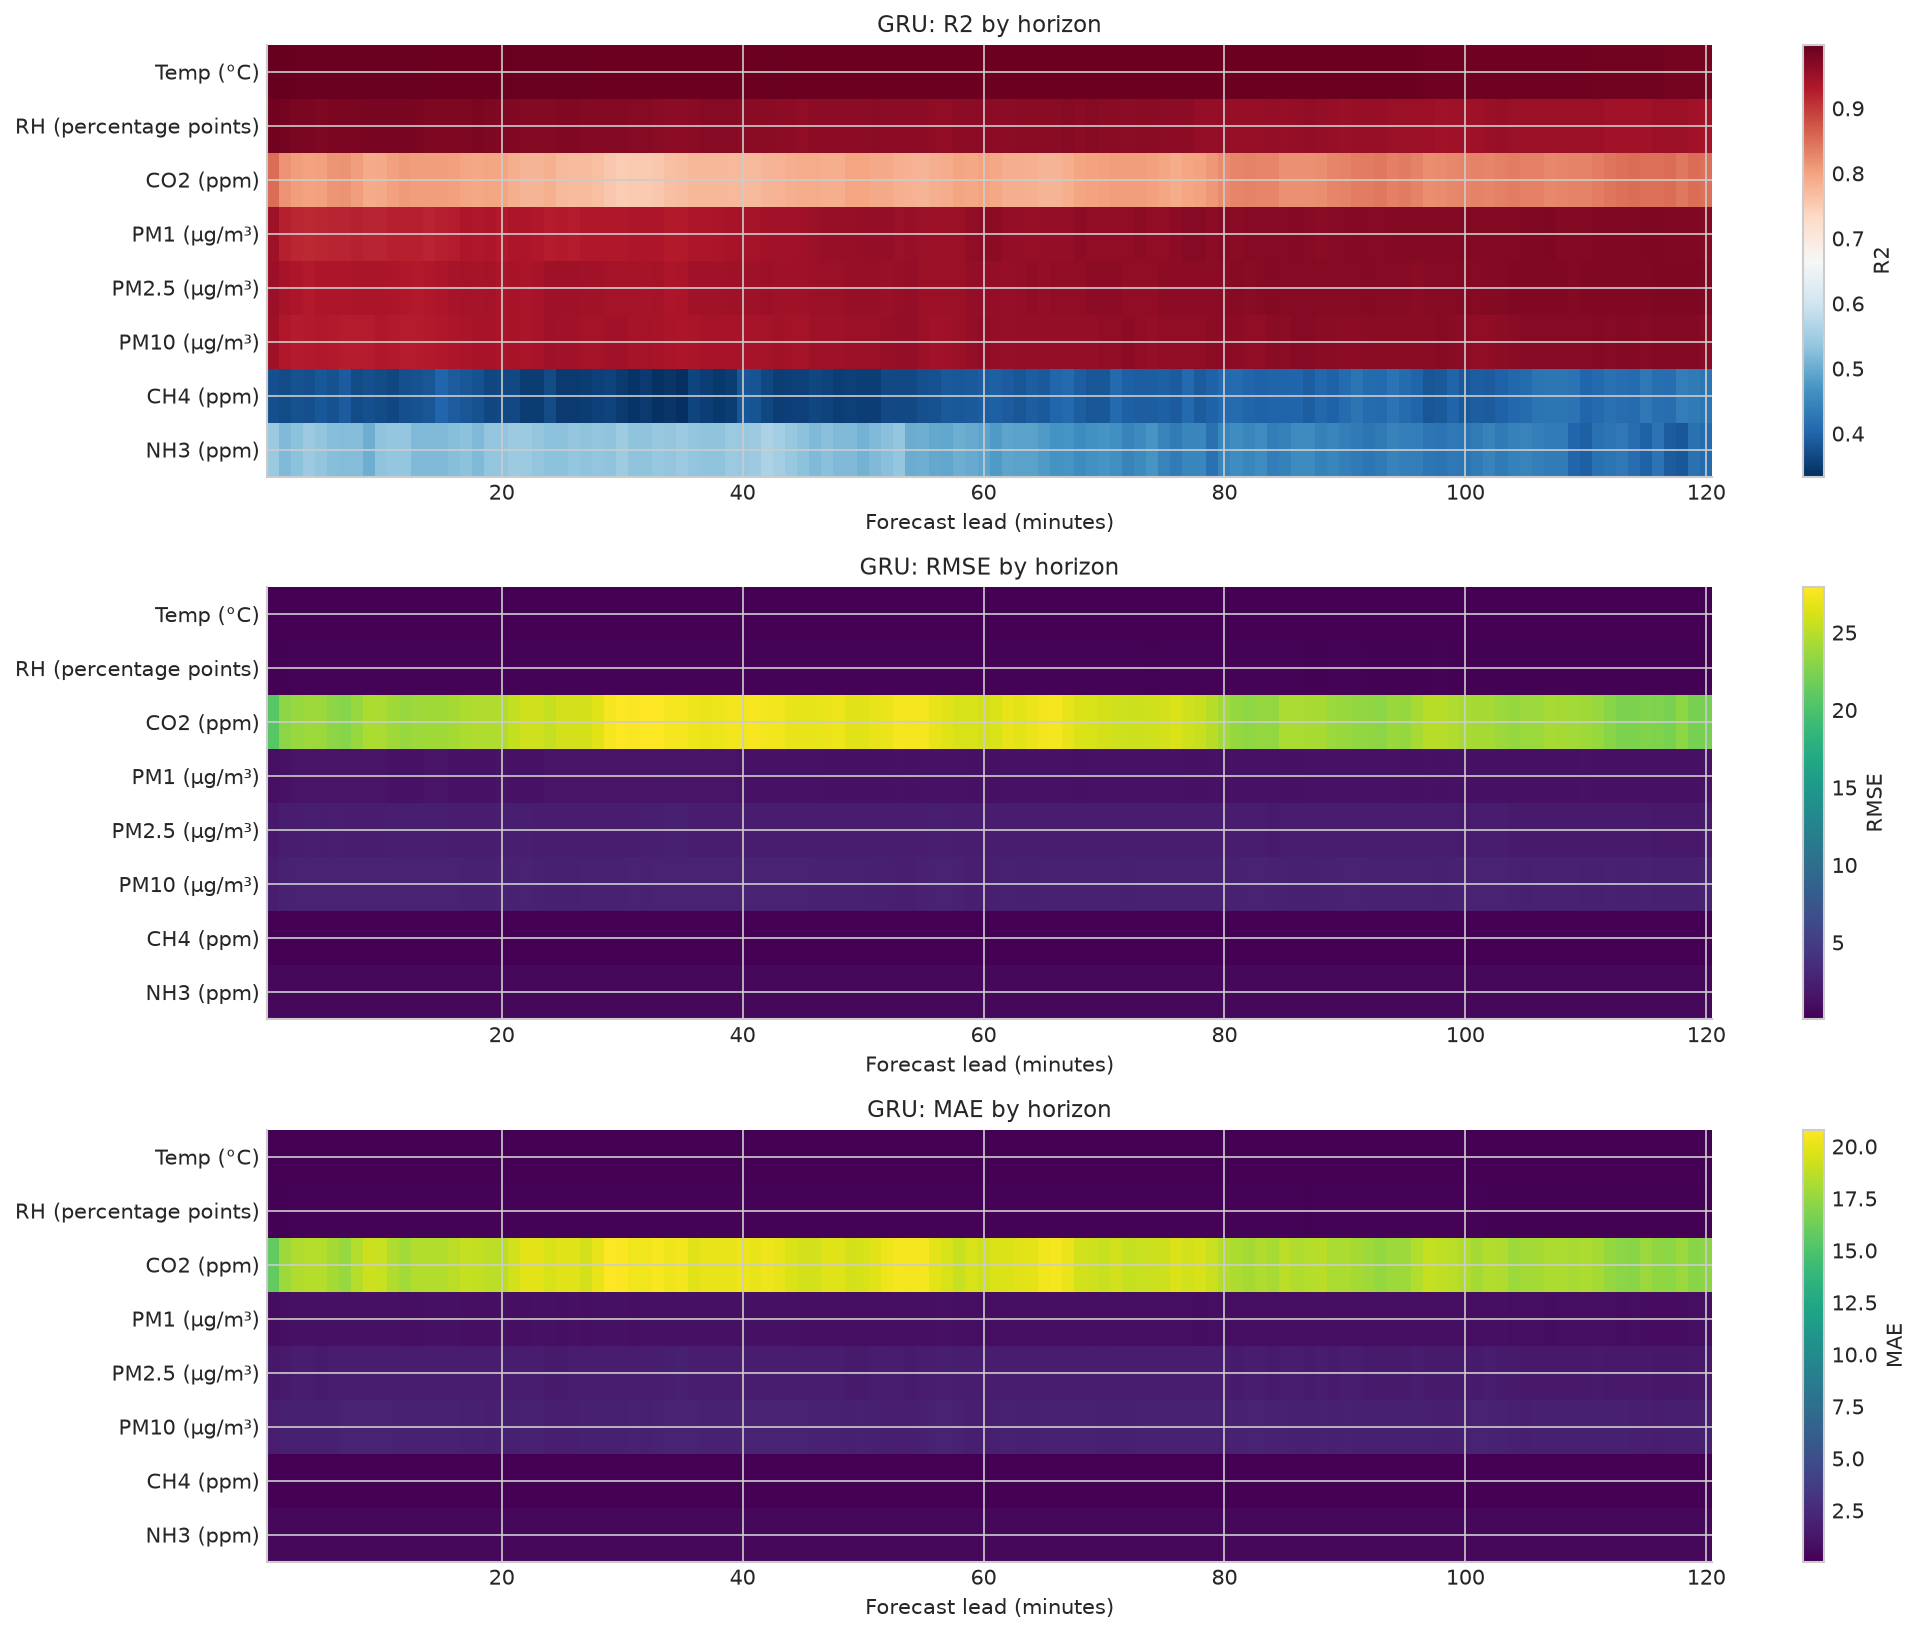

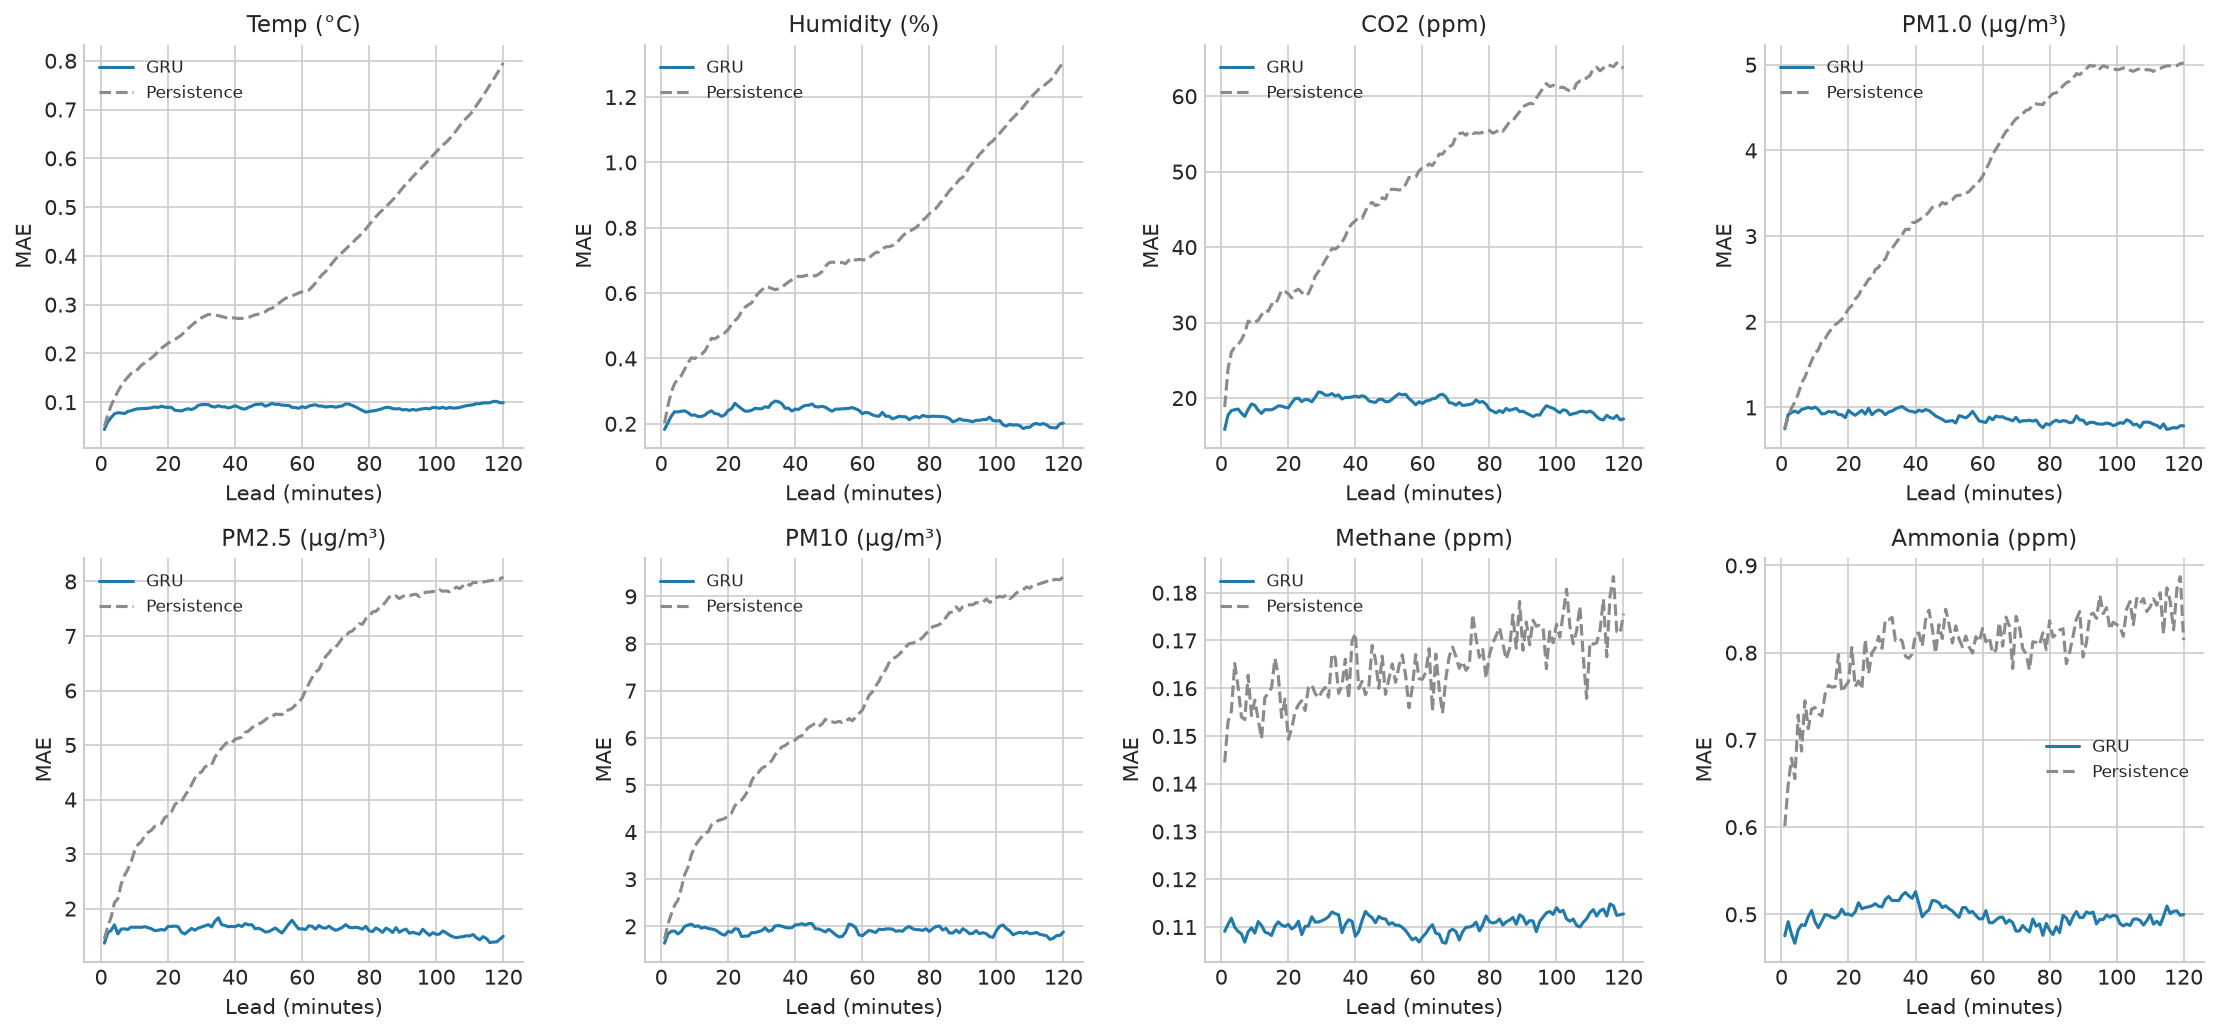

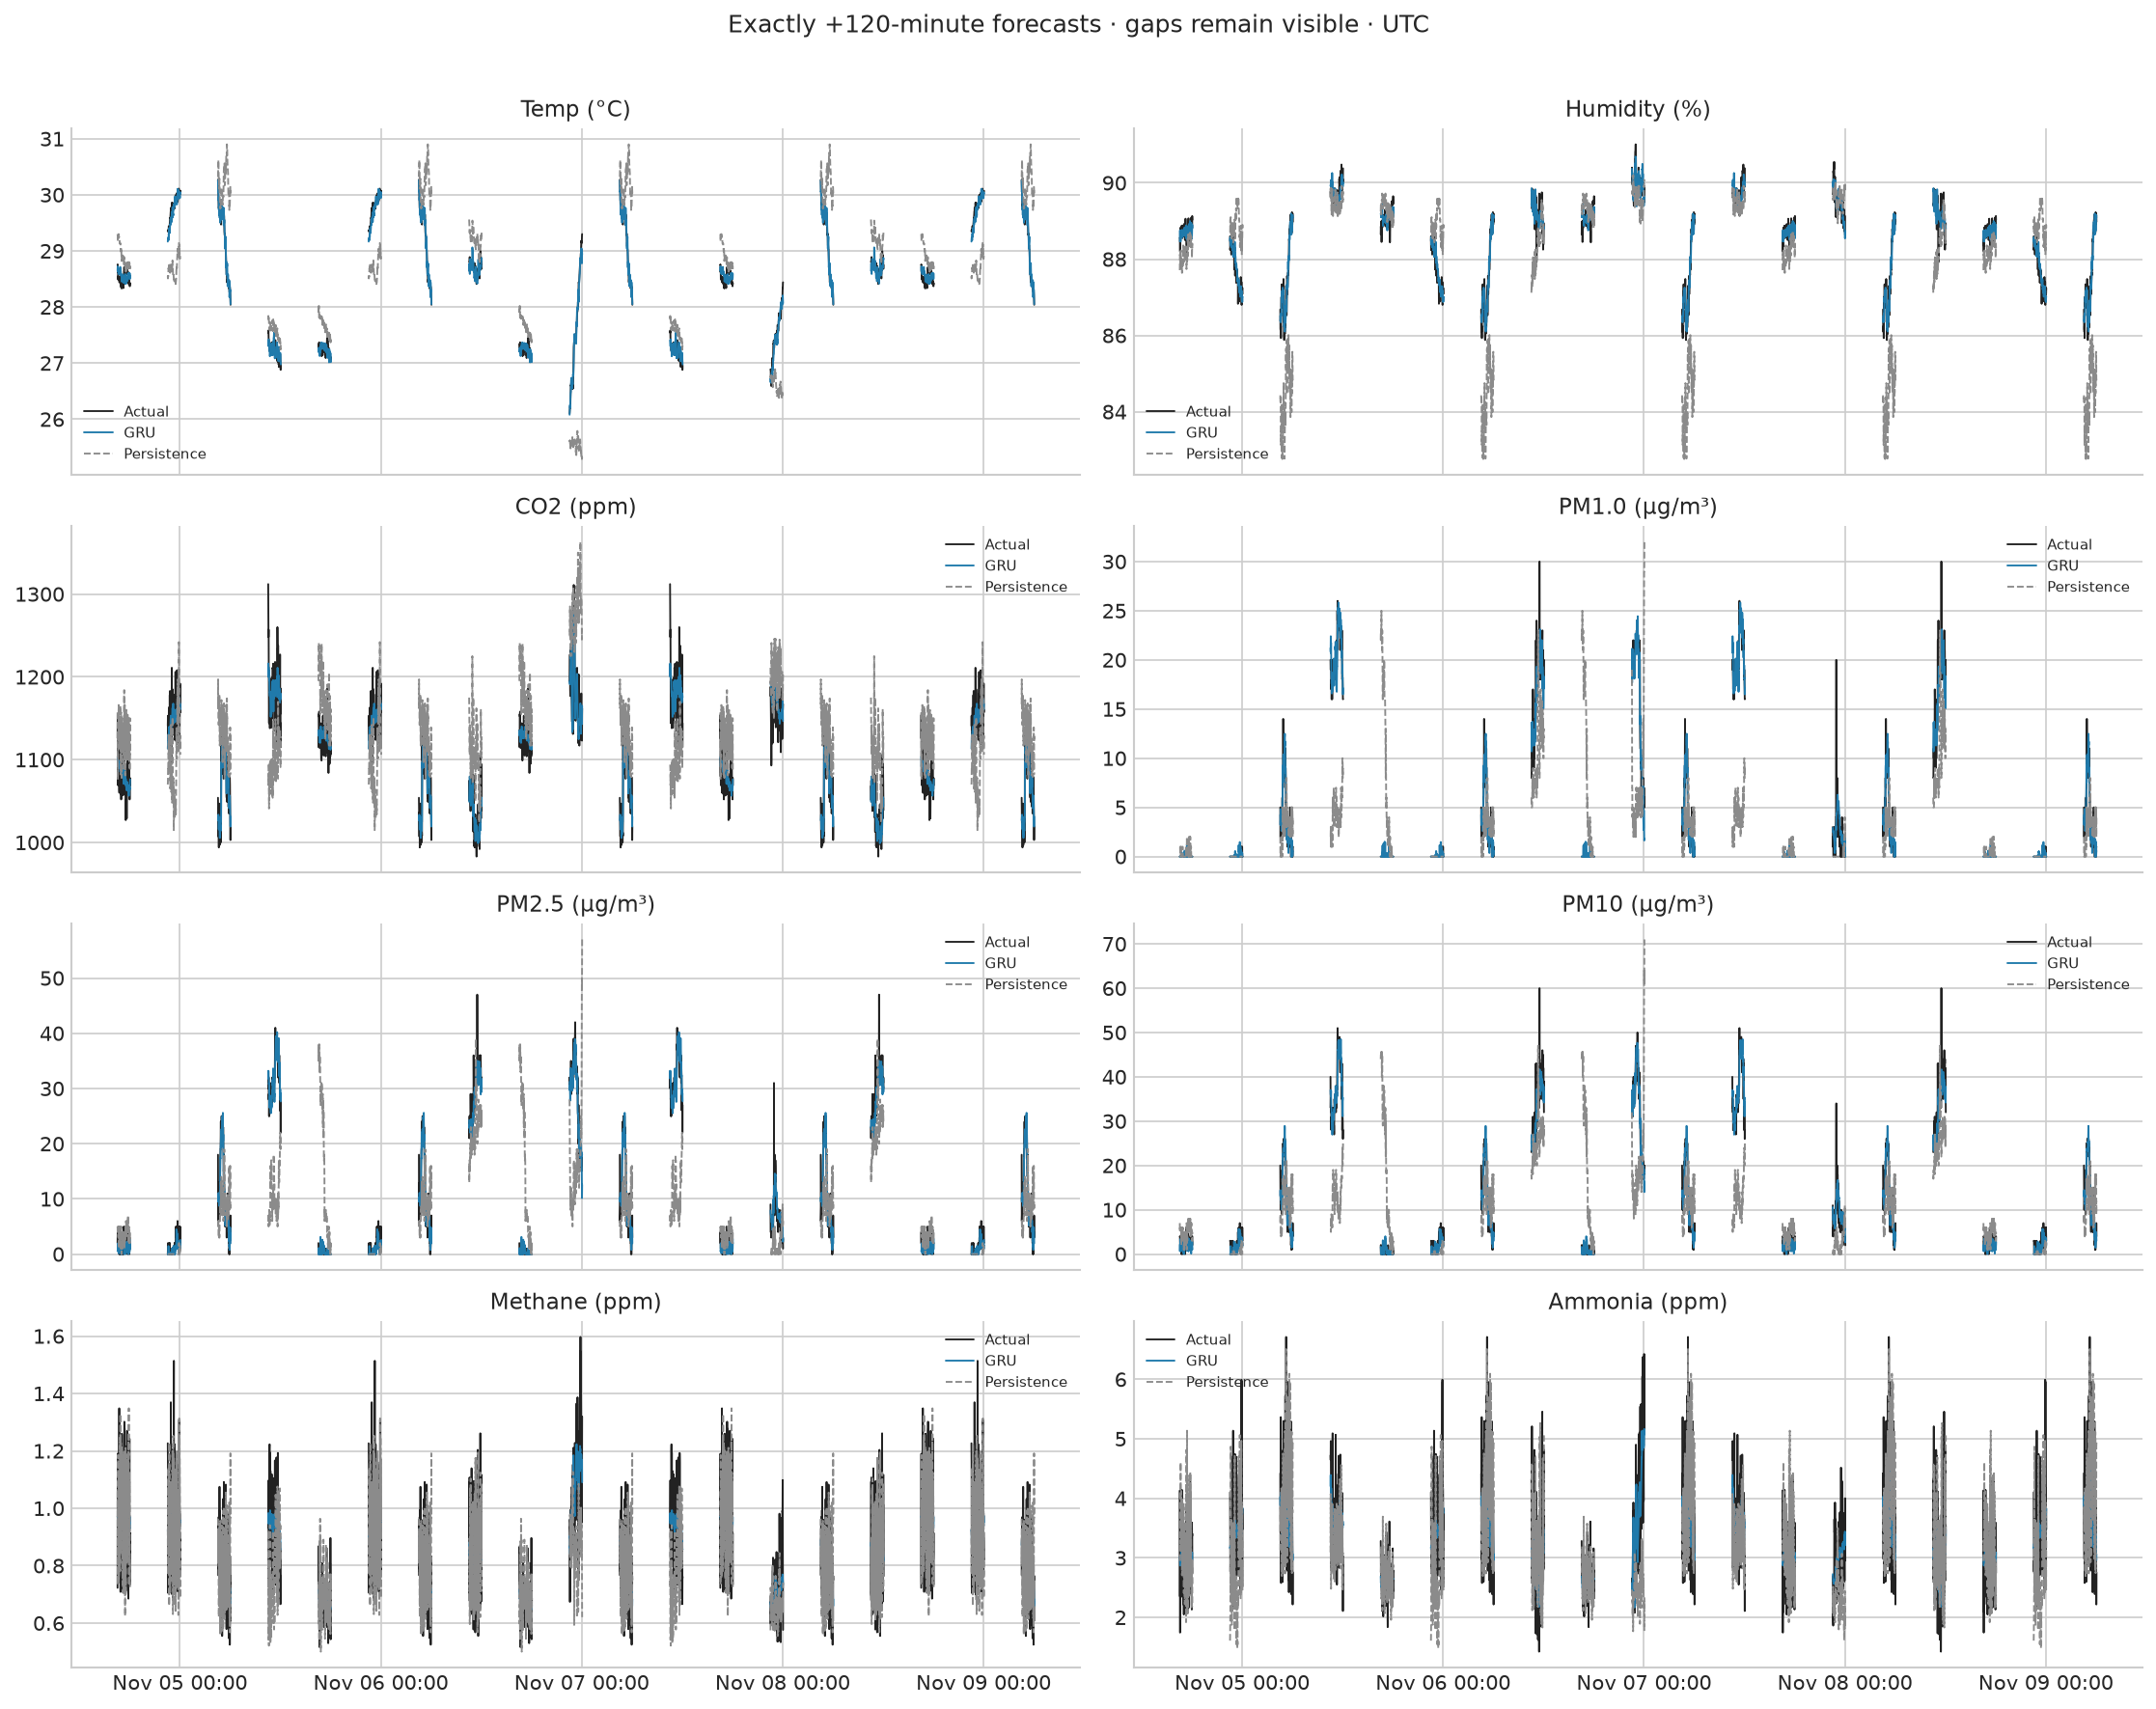

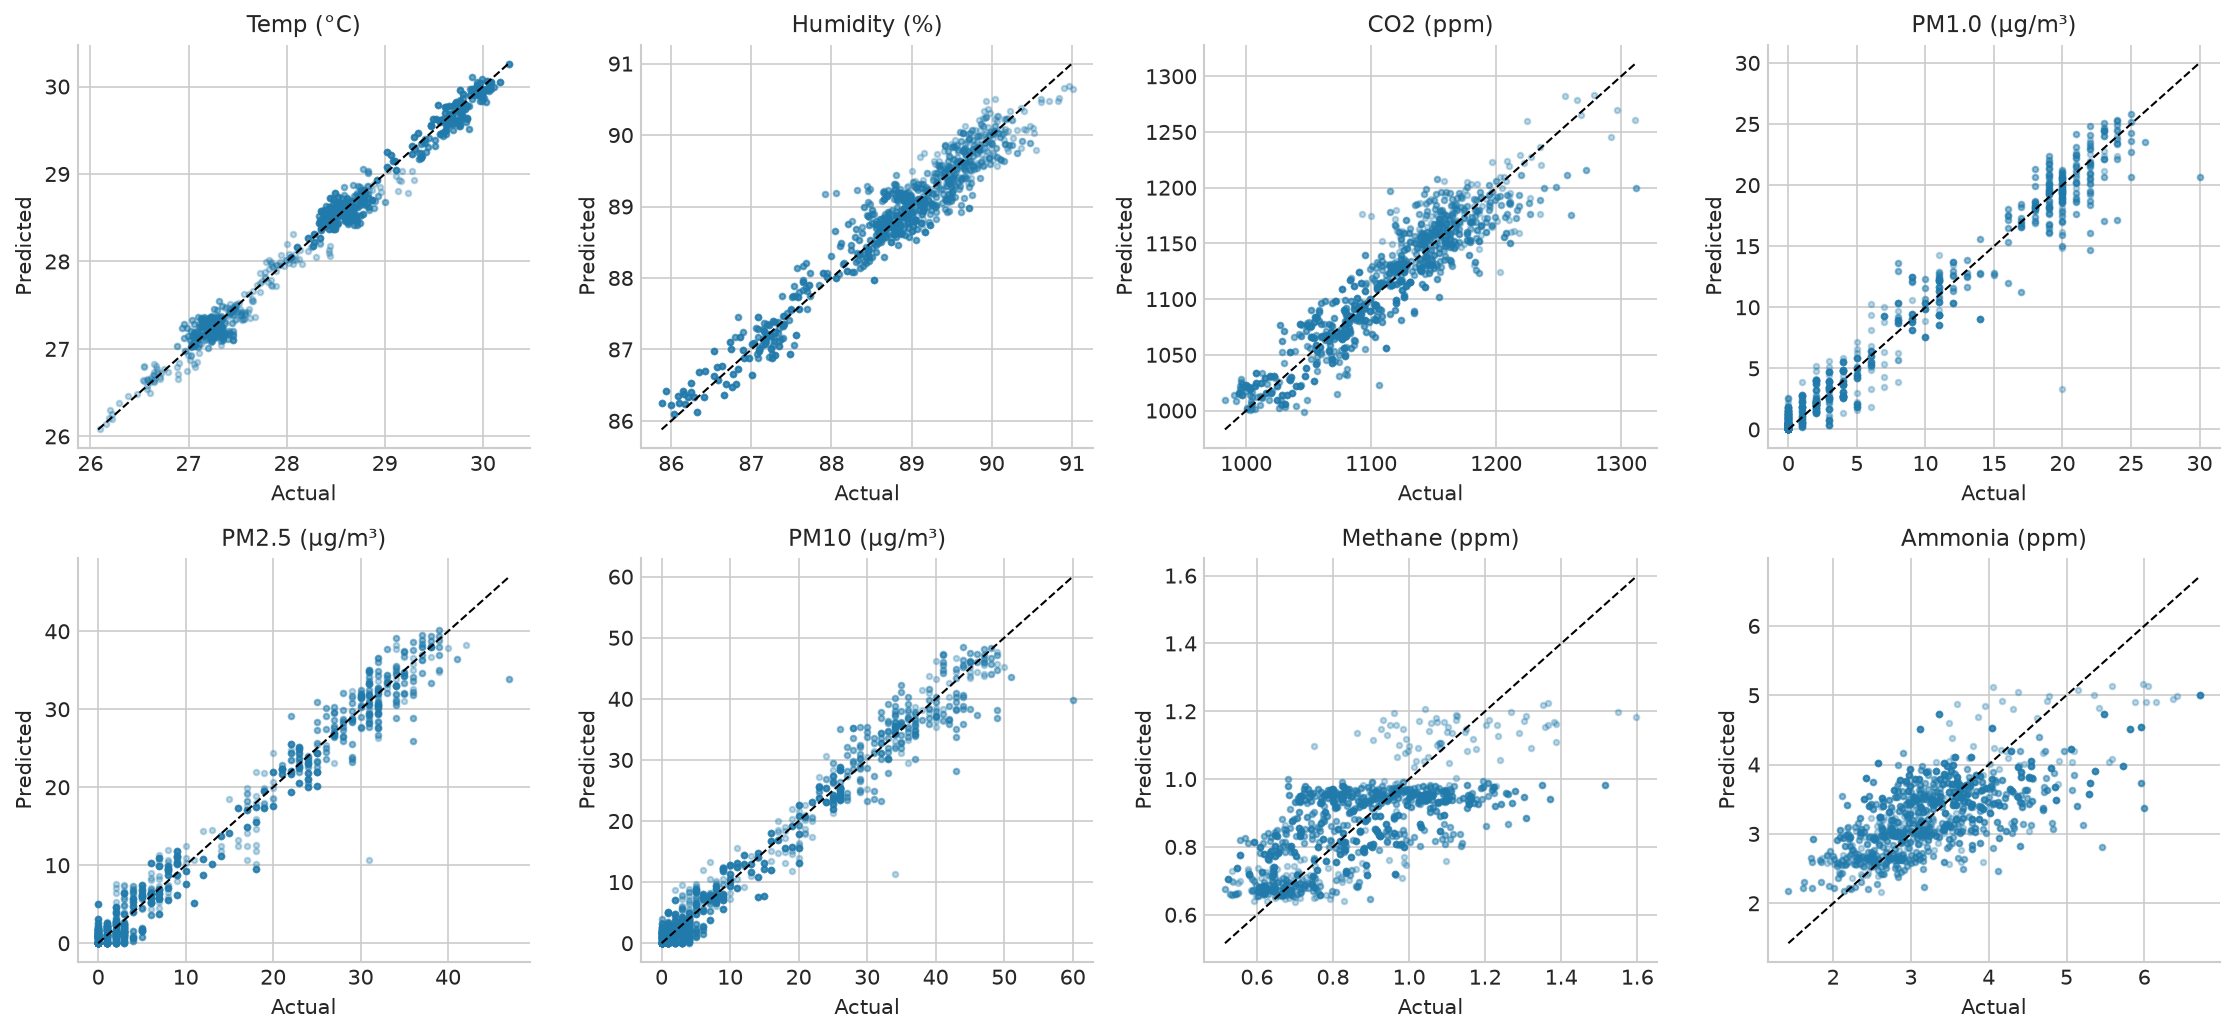

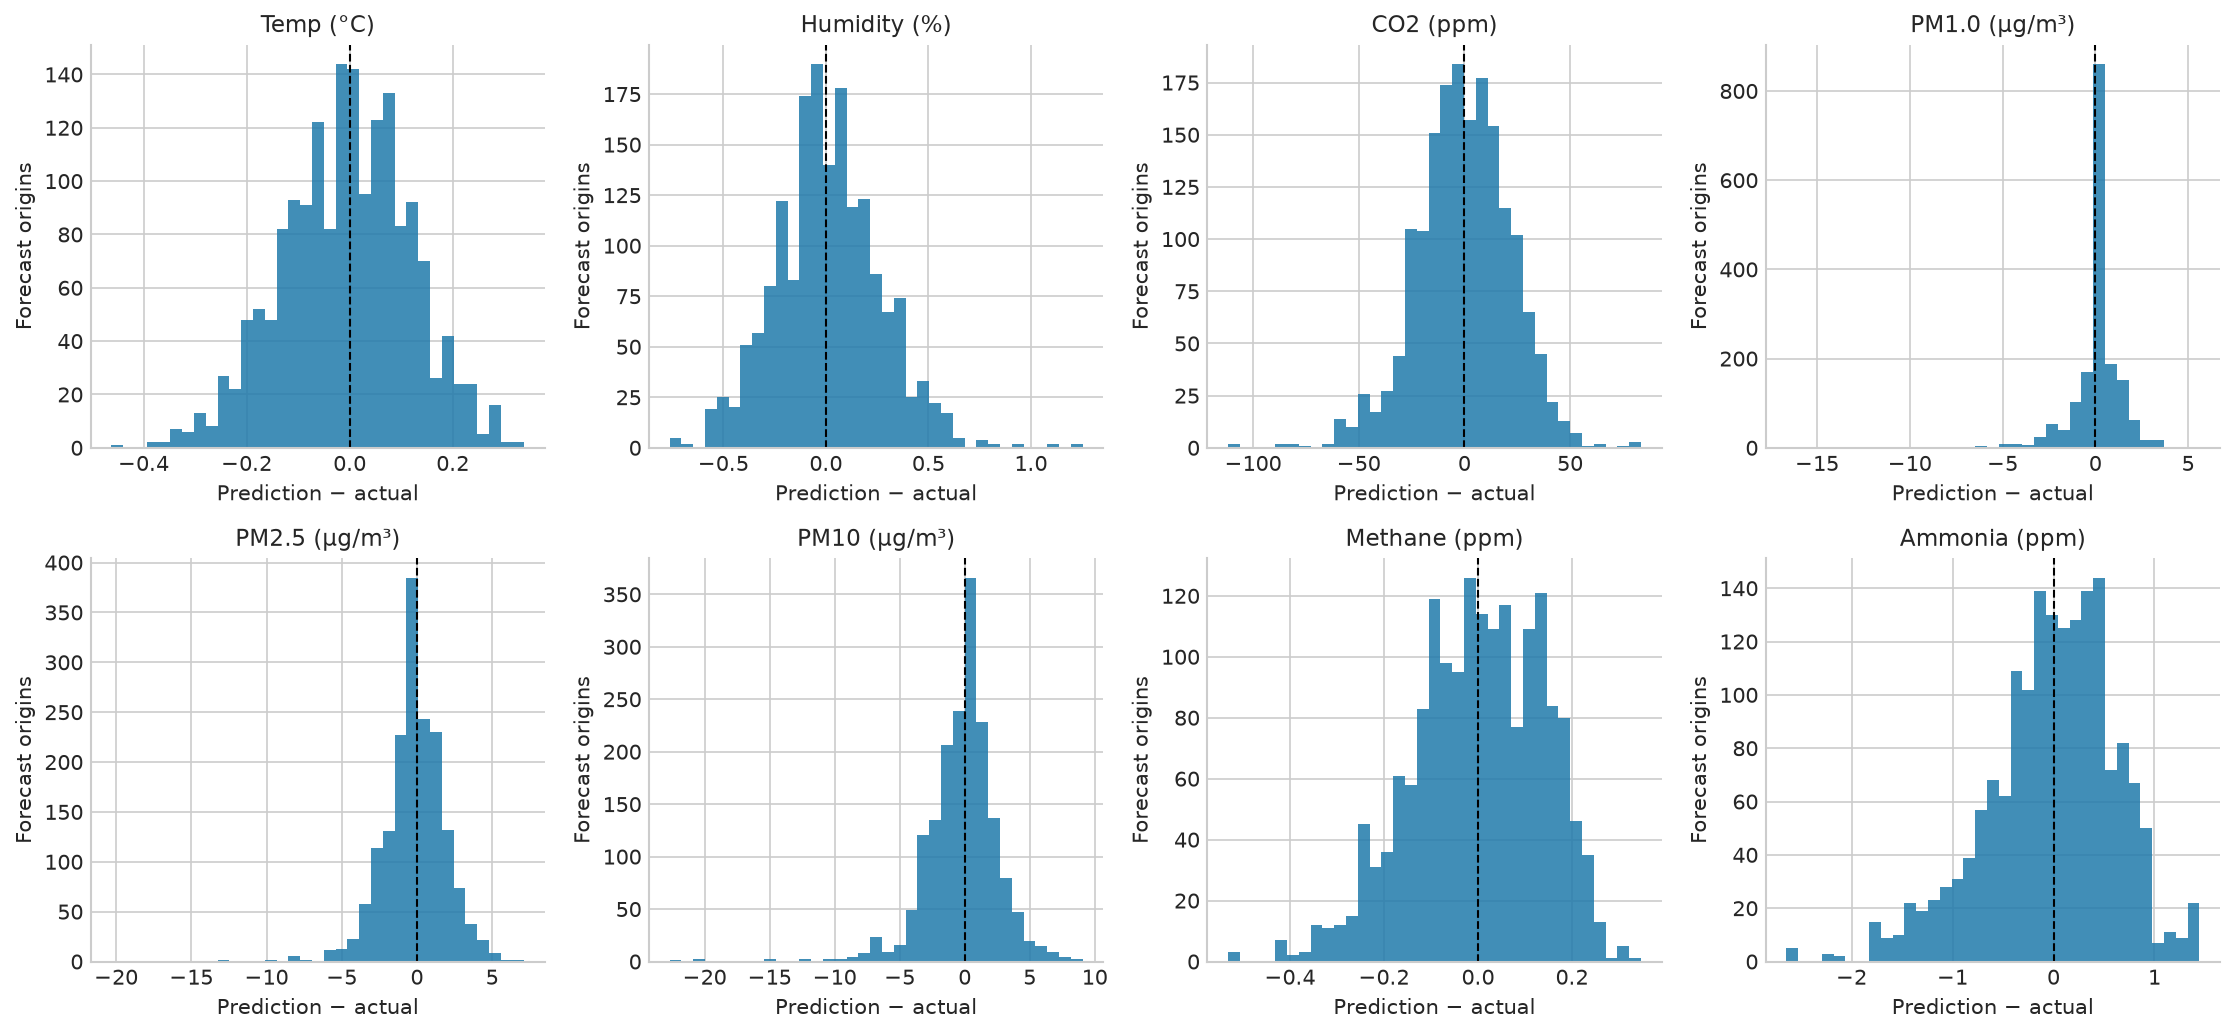

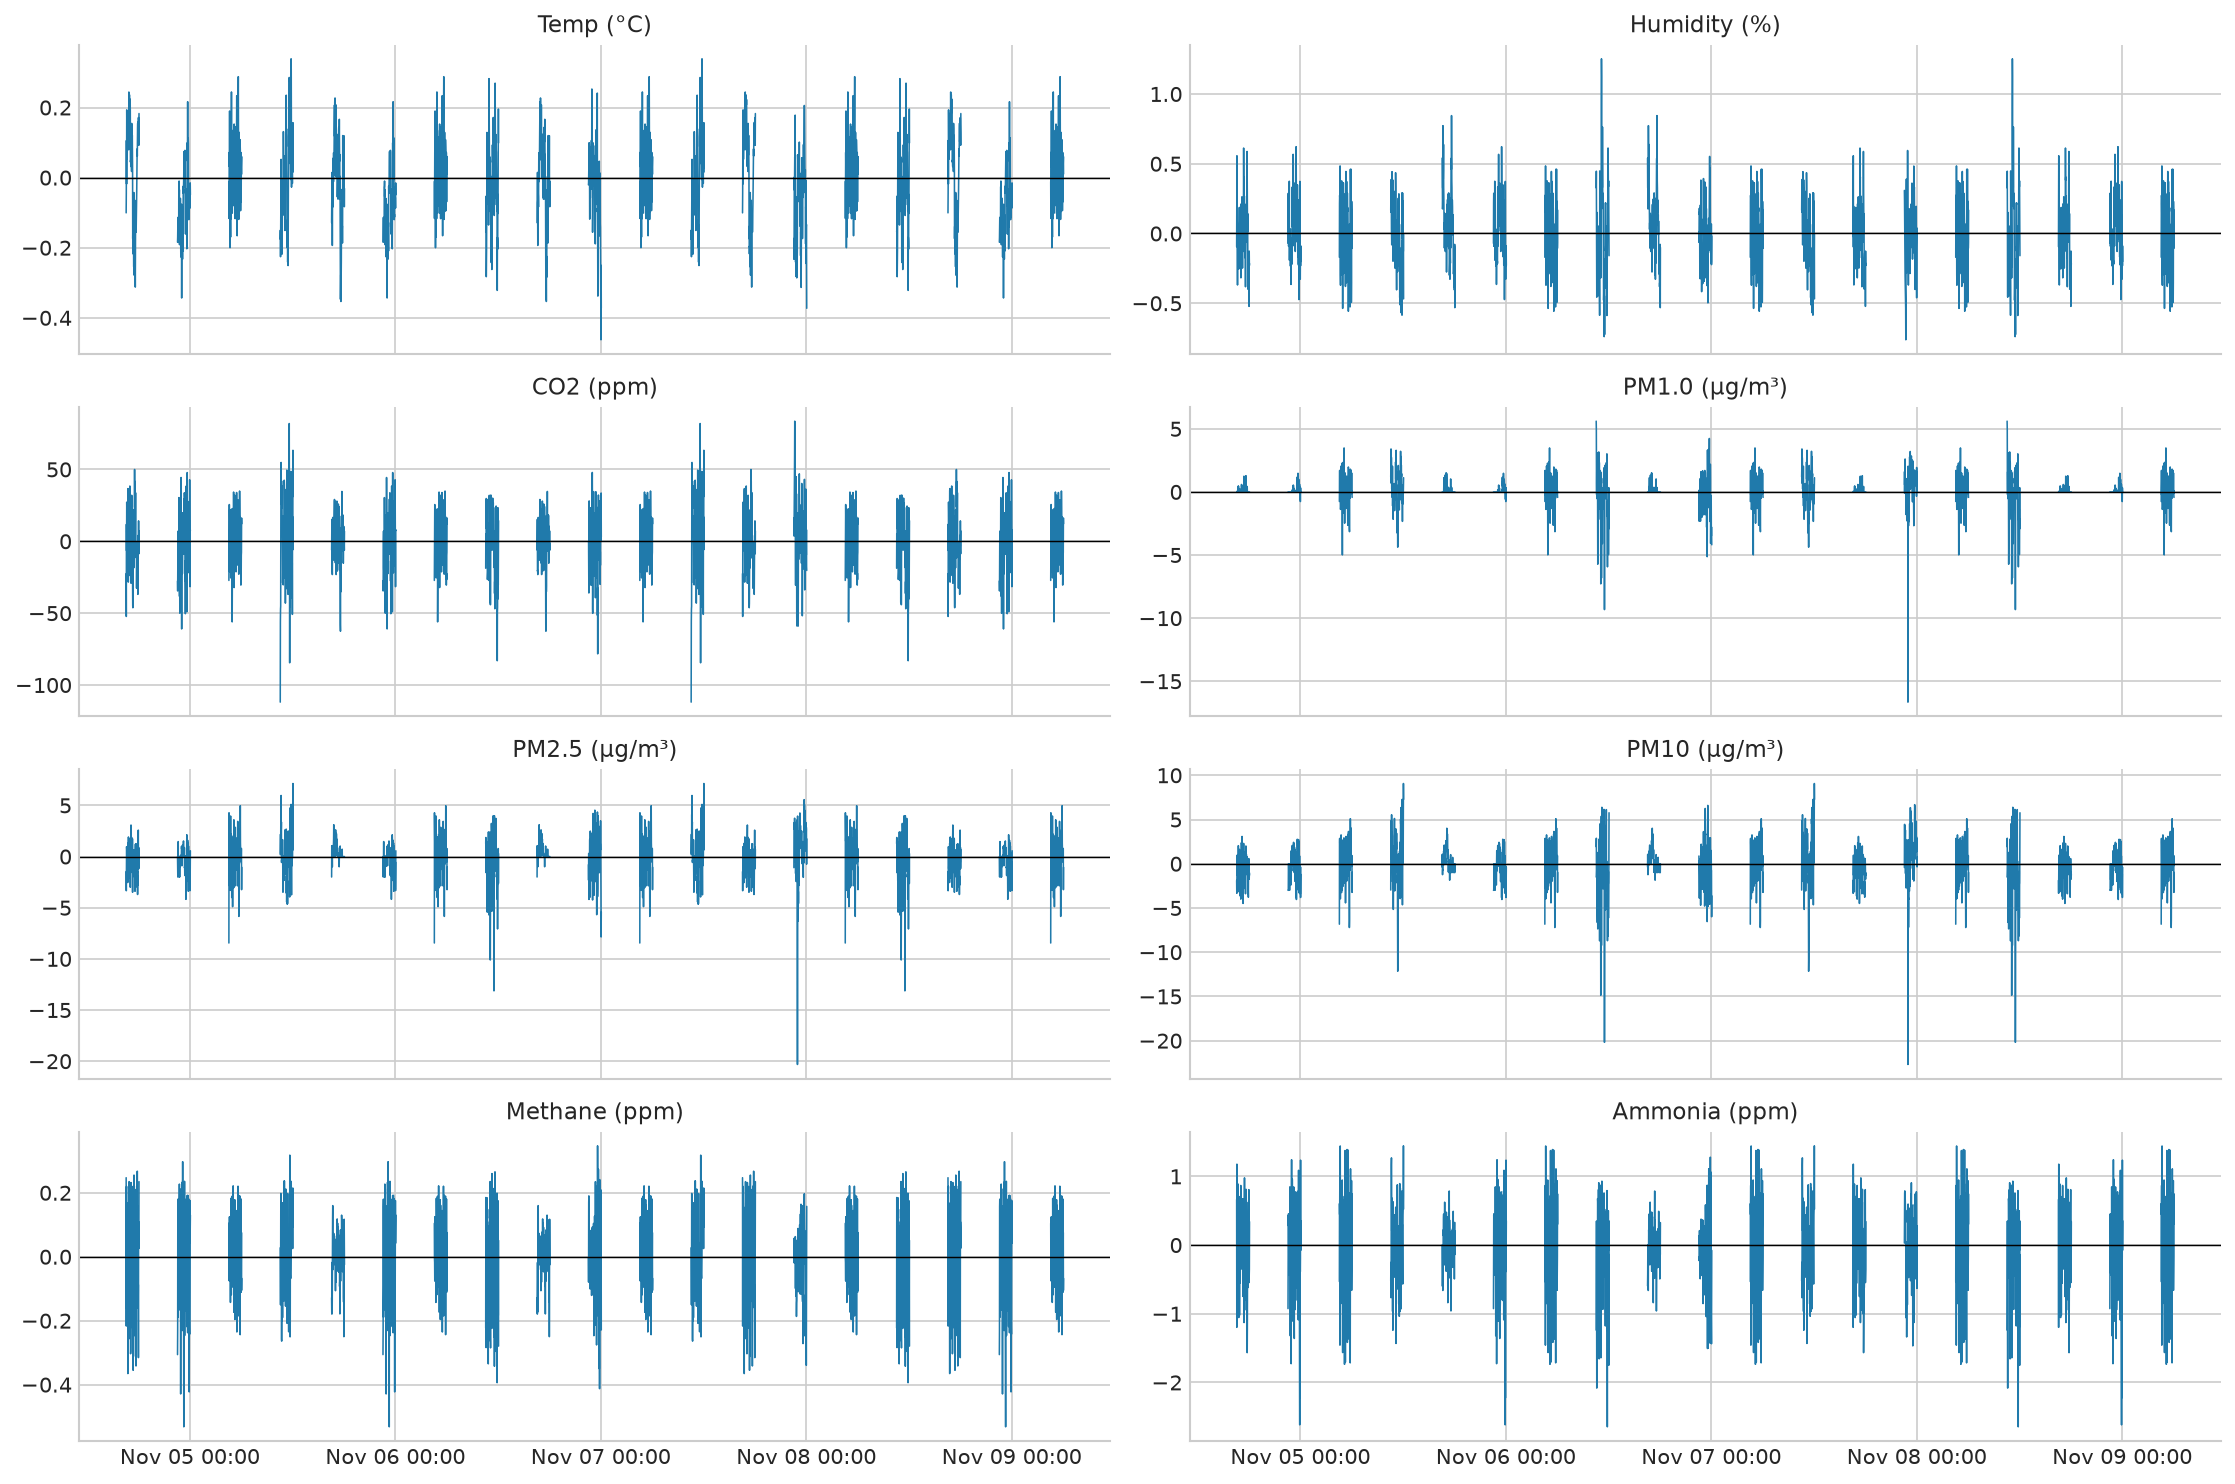

In [ ]:
model_order=['Persistence','Ridge','GRU','TCN']
for metric in ['r2','rmse','mae']:
    fig,axes=plt.subplots(2,4,figsize=(16,7))
    for j,ax in enumerate(axes.flat):
        table=endpoint[endpoint.sensor==SENSORS[j]].set_index('model').reindex(model_order)
        ax.bar(range(4),table[metric],color=[COLORS[n] for n in model_order])
        ax.set_xticks(range(4),model_order,rotation=25);ax.set_title(SENSORS[j])
        ax.set_ylabel(metric.upper() if metric=='r2' else f'{metric.upper()} ({UNITS[j]})')
        if metric=='r2': ax.axhline(.75,color='black',ls='--',lw=1)
        selected=model_order.index(WINNER)
        ax.patches[selected].set_edgecolor('black');ax.patches[selected].set_linewidth(2)
    fig.suptitle(f'+120-minute {metric.upper()} · black outline = validation-selected model'+(' · dashed target = 0.75' if metric=='r2' else ''),fontsize=13)
    fig.tight_layout(rect=[0,0,1,.95]);savefig(f'08_endpoint_{metric}')

winner_metrics=metrics[metrics.model==WINNER]
fig,axes=plt.subplots(3,1,figsize=(14,11))
for ax,metric in zip(axes,['r2','rmse','mae']):
    matrix=winner_metrics.pivot(index='sensor',columns='horizon_minutes',values=metric).reindex(SENSORS).to_numpy()
    # Row labels retain sensor units; numerical scales differ across sensors.
    im=ax.imshow(matrix,aspect='auto',cmap='RdBu_r' if metric=='r2' else 'viridis',
                 extent=[.5,120.5,7.5,-.5])
    ax.set_yticks(range(8),[f'{s} ({u})' for s,u in zip(SHORT,UNITS)])
    ax.set_xlabel('Forecast lead (minutes)');ax.set_title(f'{WINNER}: {metric.upper()} by horizon')
    fig.colorbar(im,ax=ax,label=metric.upper())
fig.tight_layout();savefig('09_horizon_heatmaps')

fig,axes=plt.subplots(2,4,figsize=(15,7))
for j,ax in enumerate(axes.flat):
    for name in [WINNER,'Persistence']:
        table=metrics[(metrics.sensor==SENSORS[j])&(metrics.model==name)]
        ax.plot(table.horizon_minutes,table.mae,label=name,color=COLORS[name],ls='--' if name=='Persistence' else '-')
    ax.set_title(SENSORS[j]);ax.set_xlabel('Lead (minutes)');ax.set_ylabel('MAE');ax.legend(fontsize=8)
fig.tight_layout();savefig('10_error_growth_by_horizon')

target_index=data.index[positions['test']]+pd.Timedelta(minutes=F)
fig,axes=plt.subplots(4,2,figsize=(15,12),sharex=True)
for j,ax in enumerate(axes.flat):
    frame=pd.DataFrame({'Actual':actual_test[:,-1,j],WINNER:test_predictions[WINNER][:,-1,j],
                        'Persistence':test_predictions['Persistence'][:,-1,j]},index=target_index)
    frame=frame.reindex(pd.date_range(target_index.min(),target_index.max(),freq='min'))
    for label,color,style in [('Actual','#222222','-'),(WINNER,COLORS[WINNER],'-'),('Persistence',COLORS['Persistence'],'--')]:
        ax.plot(frame.index,frame[label],label=label,color=color,ls=style,lw=.9)
    ax.set_title(SENSORS[j]);ax.legend(fontsize=7);ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d %H:%M'))
fig.suptitle('Exactly +120-minute forecasts · gaps remain visible · UTC')
fig.tight_layout(rect=[0,0,1,.97]);savefig('11_endpoint_timelines')

fig,axes=plt.subplots(2,4,figsize=(15,7))
for j,ax in enumerate(axes.flat):
    y,p=actual_test[:,-1,j],test_predictions[WINNER][:,-1,j]
    ax.scatter(y,p,s=7,alpha=.3,color=COLORS[WINNER],rasterized=True)
    lo,hi=min(y.min(),p.min()),max(y.max(),p.max())
    ax.plot([lo,hi],[lo,hi],'k--',lw=1);ax.set_title(SENSORS[j]);ax.set_xlabel('Actual');ax.set_ylabel('Predicted')
fig.tight_layout();savefig('12_endpoint_scatter')

fig,axes=plt.subplots(2,4,figsize=(15,7))
for j,ax in enumerate(axes.flat):
    residual=test_predictions[WINNER][:,-1,j]-actual_test[:,-1,j]
    ax.hist(residual,bins=35,color=COLORS[WINNER],alpha=.85)
    ax.axvline(0,color='black',ls='--',lw=1);ax.set_title(SENSORS[j]);ax.set_xlabel('Prediction − actual');ax.set_ylabel('Forecast origins')
fig.tight_layout();savefig('13_residual_distributions')

fig,axes=plt.subplots(4,2,figsize=(15,10),sharex=True)
for j,ax in enumerate(axes.flat):
    residual=pd.Series(test_predictions[WINNER][:,-1,j]-actual_test[:,-1,j],index=target_index)
    residual=residual.reindex(pd.date_range(target_index.min(),target_index.max(),freq='min'))
    ax.plot(residual.index,residual,lw=.75,color=COLORS[WINNER]);ax.axhline(0,color='black',lw=.7)
    ax.set_title(SENSORS[j]);ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d %H:%M'))
fig.tight_layout();savefig('14_residual_timelines')


## 6. Export the selected forecaster to Joblib
The artifact contains the model type, parameters, sensor order, units, input/output
lengths, normalization, split dates, configuration, and package versions. Neural
weights are CPU NumPy arrays, not live GPU objects. Ridge stores its coefficients
and feature scaling. Persistence can also be exported if it wins validation.

The loader below rebuilds the selected architecture. It can use CUDA or CPU for
inference. It needs the definitions in this notebook, but does not need the original
training-session model or access to the dataset to make predictions.


In [ ]:
MODEL_PATH=RESULTS/'microclimate_forecaster.joblib'
artifact=dict(format_version=1,model_type=WINNER,sensors=SENSORS,units=UNITS,
              history=H,horizon=F,sampling_minutes=1,mean=MEAN,std=STD,configuration=CONFIG,
              versions=VERSIONS,source_sha256=SOURCE_HASH,selection=selection,
              architecture=dict(gru_hidden=64,gru_layers=2,tcn_channels=32,
                                tcn_dilations=[1,2,4,8,16,32],head_hidden=128),
              target_definition='Sensor values at each minute t+1 through t+120, conditioned on t-119 through t.',
              scope='Evaluation on supplied series; not independent field validation or reference-instrument calibration.')
if WINNER in ['GRU','TCN']:
    artifact['state_dict']={k:v.detach().cpu().numpy().copy() for k,v in candidate_models[WINNER].state_dict().items()}
elif WINNER=='Ridge':
    scaler,ridge=candidate_models['Ridge'].steps[0][1],candidate_models['Ridge'].steps[1][1]
    artifact['ridge']=dict(feature_mean=scaler.mean_,feature_scale=scaler.scale_,
                           coefficients=ridge.coef_,intercept=ridge.intercept_,alpha=ridge.alpha)
joblib.dump(artifact,MODEL_PATH,compress=3)

def load_forecaster(model_path,device='cpu'):
    bundle=joblib.load(model_path)
    if bundle.get('format_version')!=1 or bundle['history']!=120 or bundle['horizon']!=120:
        raise ValueError('Unsupported model format or input/output lengths.')
    requested=torch.device(device)
    if requested.type=='cuda' and not torch.cuda.is_available():
        raise RuntimeError('CUDA requested but unavailable; explicitly choose CPU for inference.')
    result={'bundle':bundle,'device':requested}
    if bundle['model_type'] in ['GRU','TCN']:
        model=GRUForecaster() if bundle['model_type']=='GRU' else TCNForecaster()
        model.load_state_dict({k:torch.from_numpy(v.copy()) for k,v in bundle['state_dict'].items()})
        result['model']=model.to(requested).eval()
    return result

def forecast_next_120_minutes(recent_readings,forecaster):
    b=forecaster['bundle']
    if not isinstance(recent_readings,pd.DataFrame) or list(recent_readings.columns)!=b['sensors']:
        raise ValueError('Input must be a DataFrame with the eight training sensor columns in order.')
    if not isinstance(recent_readings.index,pd.DatetimeIndex) or recent_readings.index.tz is None:
        raise ValueError('Input requires a timezone-aware DatetimeIndex.')
    if len(recent_readings)!=120:
        raise ValueError('Provide exactly 120 one-minute observations.')
    index=recent_readings.index.tz_convert('UTC')
    if not index.is_monotonic_increasing or index.has_duplicates or not index.equals(index.floor('min')):
        raise ValueError('Input timestamps must be unique, ascending and aligned to minute bins.')
    if not np.all(np.diff(index.asi8)==60*10**9):
        raise ValueError('Input minutes must be consecutive; do not fill gaps implicitly.')
    a=recent_readings.to_numpy(dtype=np.float32)
    if not np.isfinite(a).all(): raise ValueError('Input readings must be finite.')
    if (a[:,1]<0).any() or (a[:,1]>100).any() or (a[:,2:]<0).any() or (a[:,3]>a[:,4]).any() or (a[:,4]>a[:,5]).any():
        raise ValueError('Input readings violate sensor constraints.')
    z=(a-b['mean'])/b['std']
    phase=2*np.pi*(index.hour*60+index.minute)/1440
    x=np.column_stack([z,np.sin(phase),np.cos(phase)]).astype(np.float32)[None]
    name=b['model_type']
    if name=='Persistence': prediction_z=np.repeat(z[-1][None,None,:],120,axis=1)
    elif name=='Ridge':
        r=b['ridge']; xx=(engineered(x)-r['feature_mean'])/r['feature_scale']
        prediction_z=(xx@r['coefficients'].T+r['intercept']).reshape(1,120,8)+z[-1][None,None,:]
    else:
        with torch.inference_mode():
            prediction_z=forecaster['model'](torch.from_numpy(x).to(forecaster['device'])).cpu().numpy()
    prediction=project(prediction_z*b['std']+b['mean'])[0]
    future=pd.date_range(index[-1]+pd.Timedelta(minutes=1),periods=120,freq='min',name='Timestamp (UTC)')
    return pd.DataFrame(prediction,index=future,columns=b['sensors'])

reloaded=load_forecaster(MODEL_PATH,device='cuda')
print('Exported:',MODEL_PATH.name,'| Type:',WINNER,'| Bytes:',MODEL_PATH.stat().st_size)


**Saved completed-run results.** Restored from retained run artifacts; training was not rerun.

**Verified saved model:** `microclimate_forecaster.joblib`  
**Model type:** GRU  
**Size:** 642,643 bytes  
**SHA-256:** `eaef59203a1654e4c51c626420f0a558e3aab939c30b881bcaeaad370763b959`  
The saved artifact supports CPU/GPU inference through the client loader.

## 7. Worked example: input → reloaded model → predictions → actual readings
Use the **first eligible test origin**, chosen by position rather than forecast
quality. The full input has 120 rows. Displayed previews show the beginning and
end; the CSV retains every row. All predictions below come from the Joblib loader.


**Saved completed-run results.** Restored from retained run artifacts; training was not rerun.

### Recorded example input: first and last three rows

Timestamp (UTC),Temp (°C),Humidity (%),CO2 (ppm),PM1.0 (µg/m³),PM2.5 (µg/m³),PM10 (µg/m³),Methane (ppm),Ammonia (ppm)
2026-11-04 12:34:00+00:00,28.89,87.89,1092,17,28,32,1.32742,5.32352
2026-11-04 12:35:00+00:00,28.96,88.11,1160,18,29,31,1.09721,3.74452
2026-11-04 12:36:00+00:00,28.96,87.95,1130,20,30,33,0.944182,3.08671
2026-11-04 14:31:00+00:00,29.39,88.16,1148,1,7,7,0.730392,5.08703
2026-11-04 14:32:00+00:00,29.31,87.87,1124,1,6,7,1.10174,2.75008
2026-11-04 14:33:00+00:00,29.3,87.71,1157,1,5,7,1.05931,2.94706


### Input → prediction → target at selected horizons

lead_minutes,sensor,predicted,actual,persistence
1,Temp (°C),29.2813,29.27,29.3
1,Humidity (%),87.713,88.12,87.71
1,CO2 (ppm),1143.07,1119,1157
1,PM1.0 (µg/m³),0.82009,1,1
1,PM2.5 (µg/m³),4.5317,4,5
1,PM10 (µg/m³),6.56173,5,7
1,Methane (ppm),0.960335,0.733764,1.05931
1,Ammonia (ppm),3.53729,3.13551,2.94706
30,Temp (°C),28.9213,28.87,29.3
30,Humidity (%),87.9049,88.24,87.71


model,sensor,units,r2,rmse,mae
GRU,Temp (°C),°C,0.83035,0.0784239,0.0610902
Persistence,Temp (°C),°C,-5.4787,0.484636,0.445667
GRU,Humidity (%),percentage points,0.0160701,0.26681,0.222084
Persistence,Humidity (%),percentage points,-4.43177,0.626888,0.567417
GRU,CO2 (ppm),ppm,0.0066429,24.3836,20.0144
Persistence,CO2 (ppm),ppm,-1.73139,40.4332,33.4917
GRU,PM1.0 (µg/m³),µg/m³,0.0407632,0.50517,0.268933
Persistence,PM1.0 (µg/m³),µg/m³,-1.97572,0.889757,0.791667
GRU,PM2.5 (µg/m³),µg/m³,-0.632084,1.82465,1.46464
Persistence,PM2.5 (µg/m³),µg/m³,-1.43064,2.22673,1.825


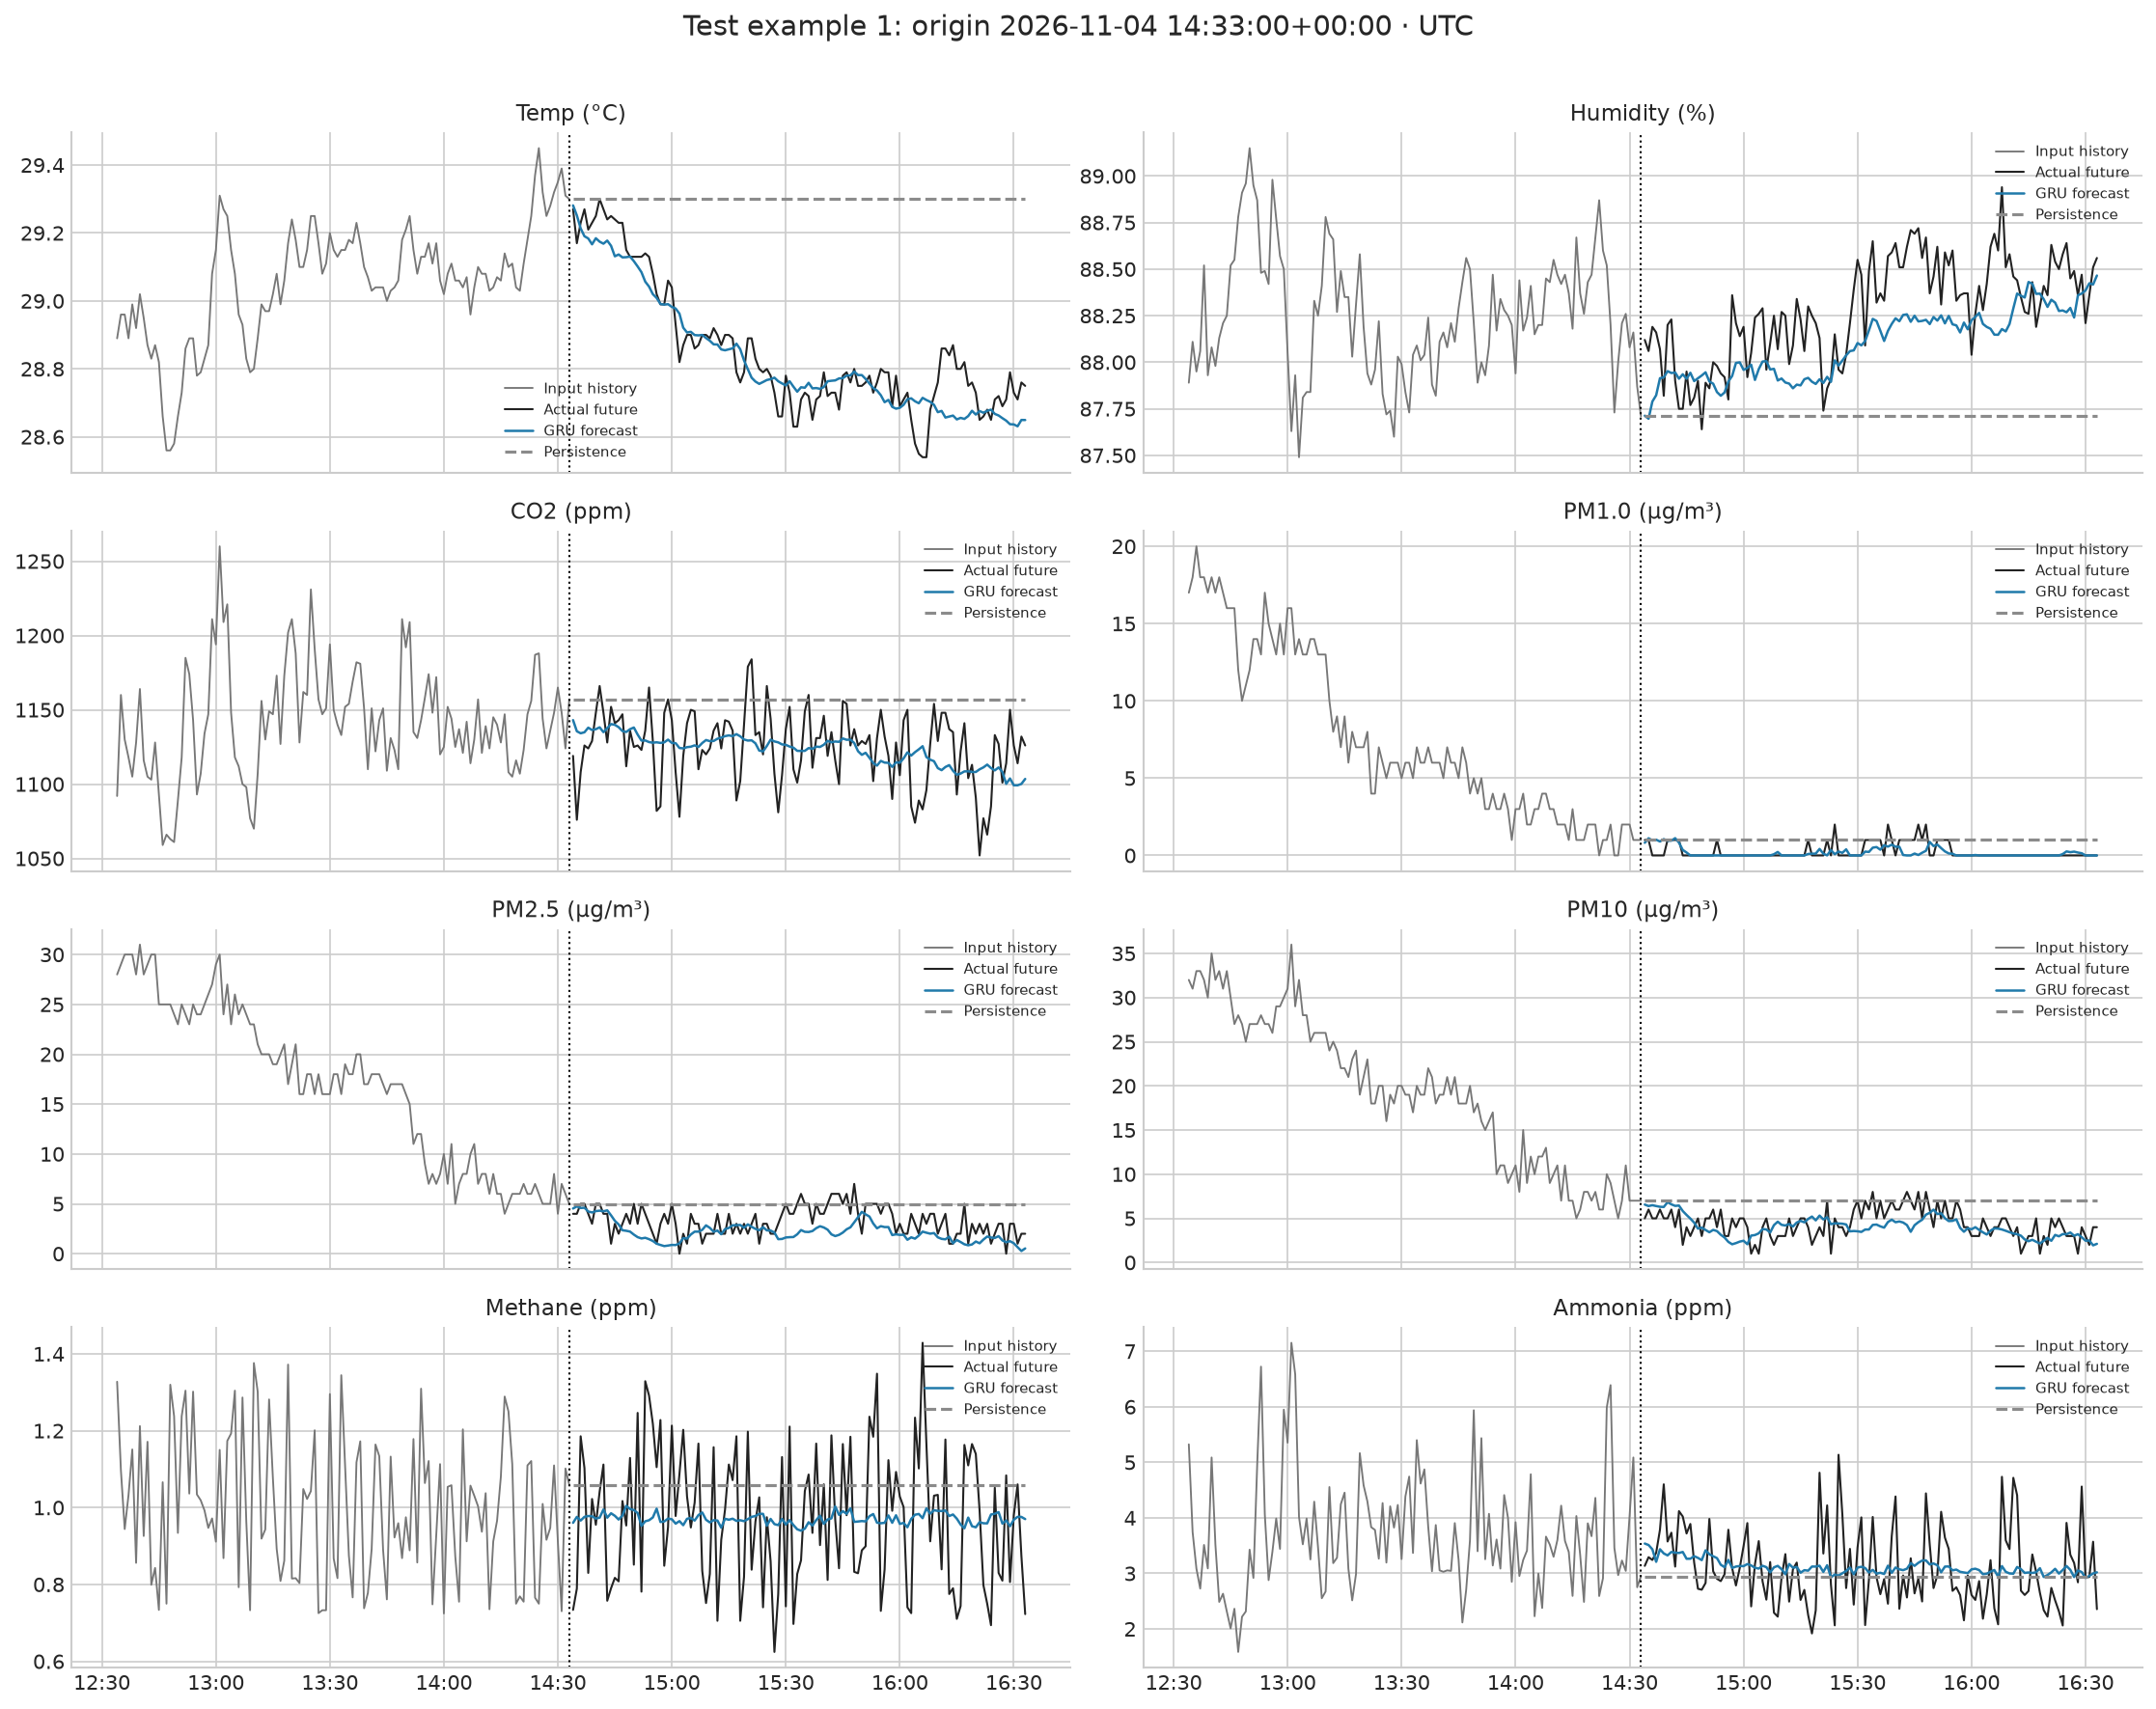

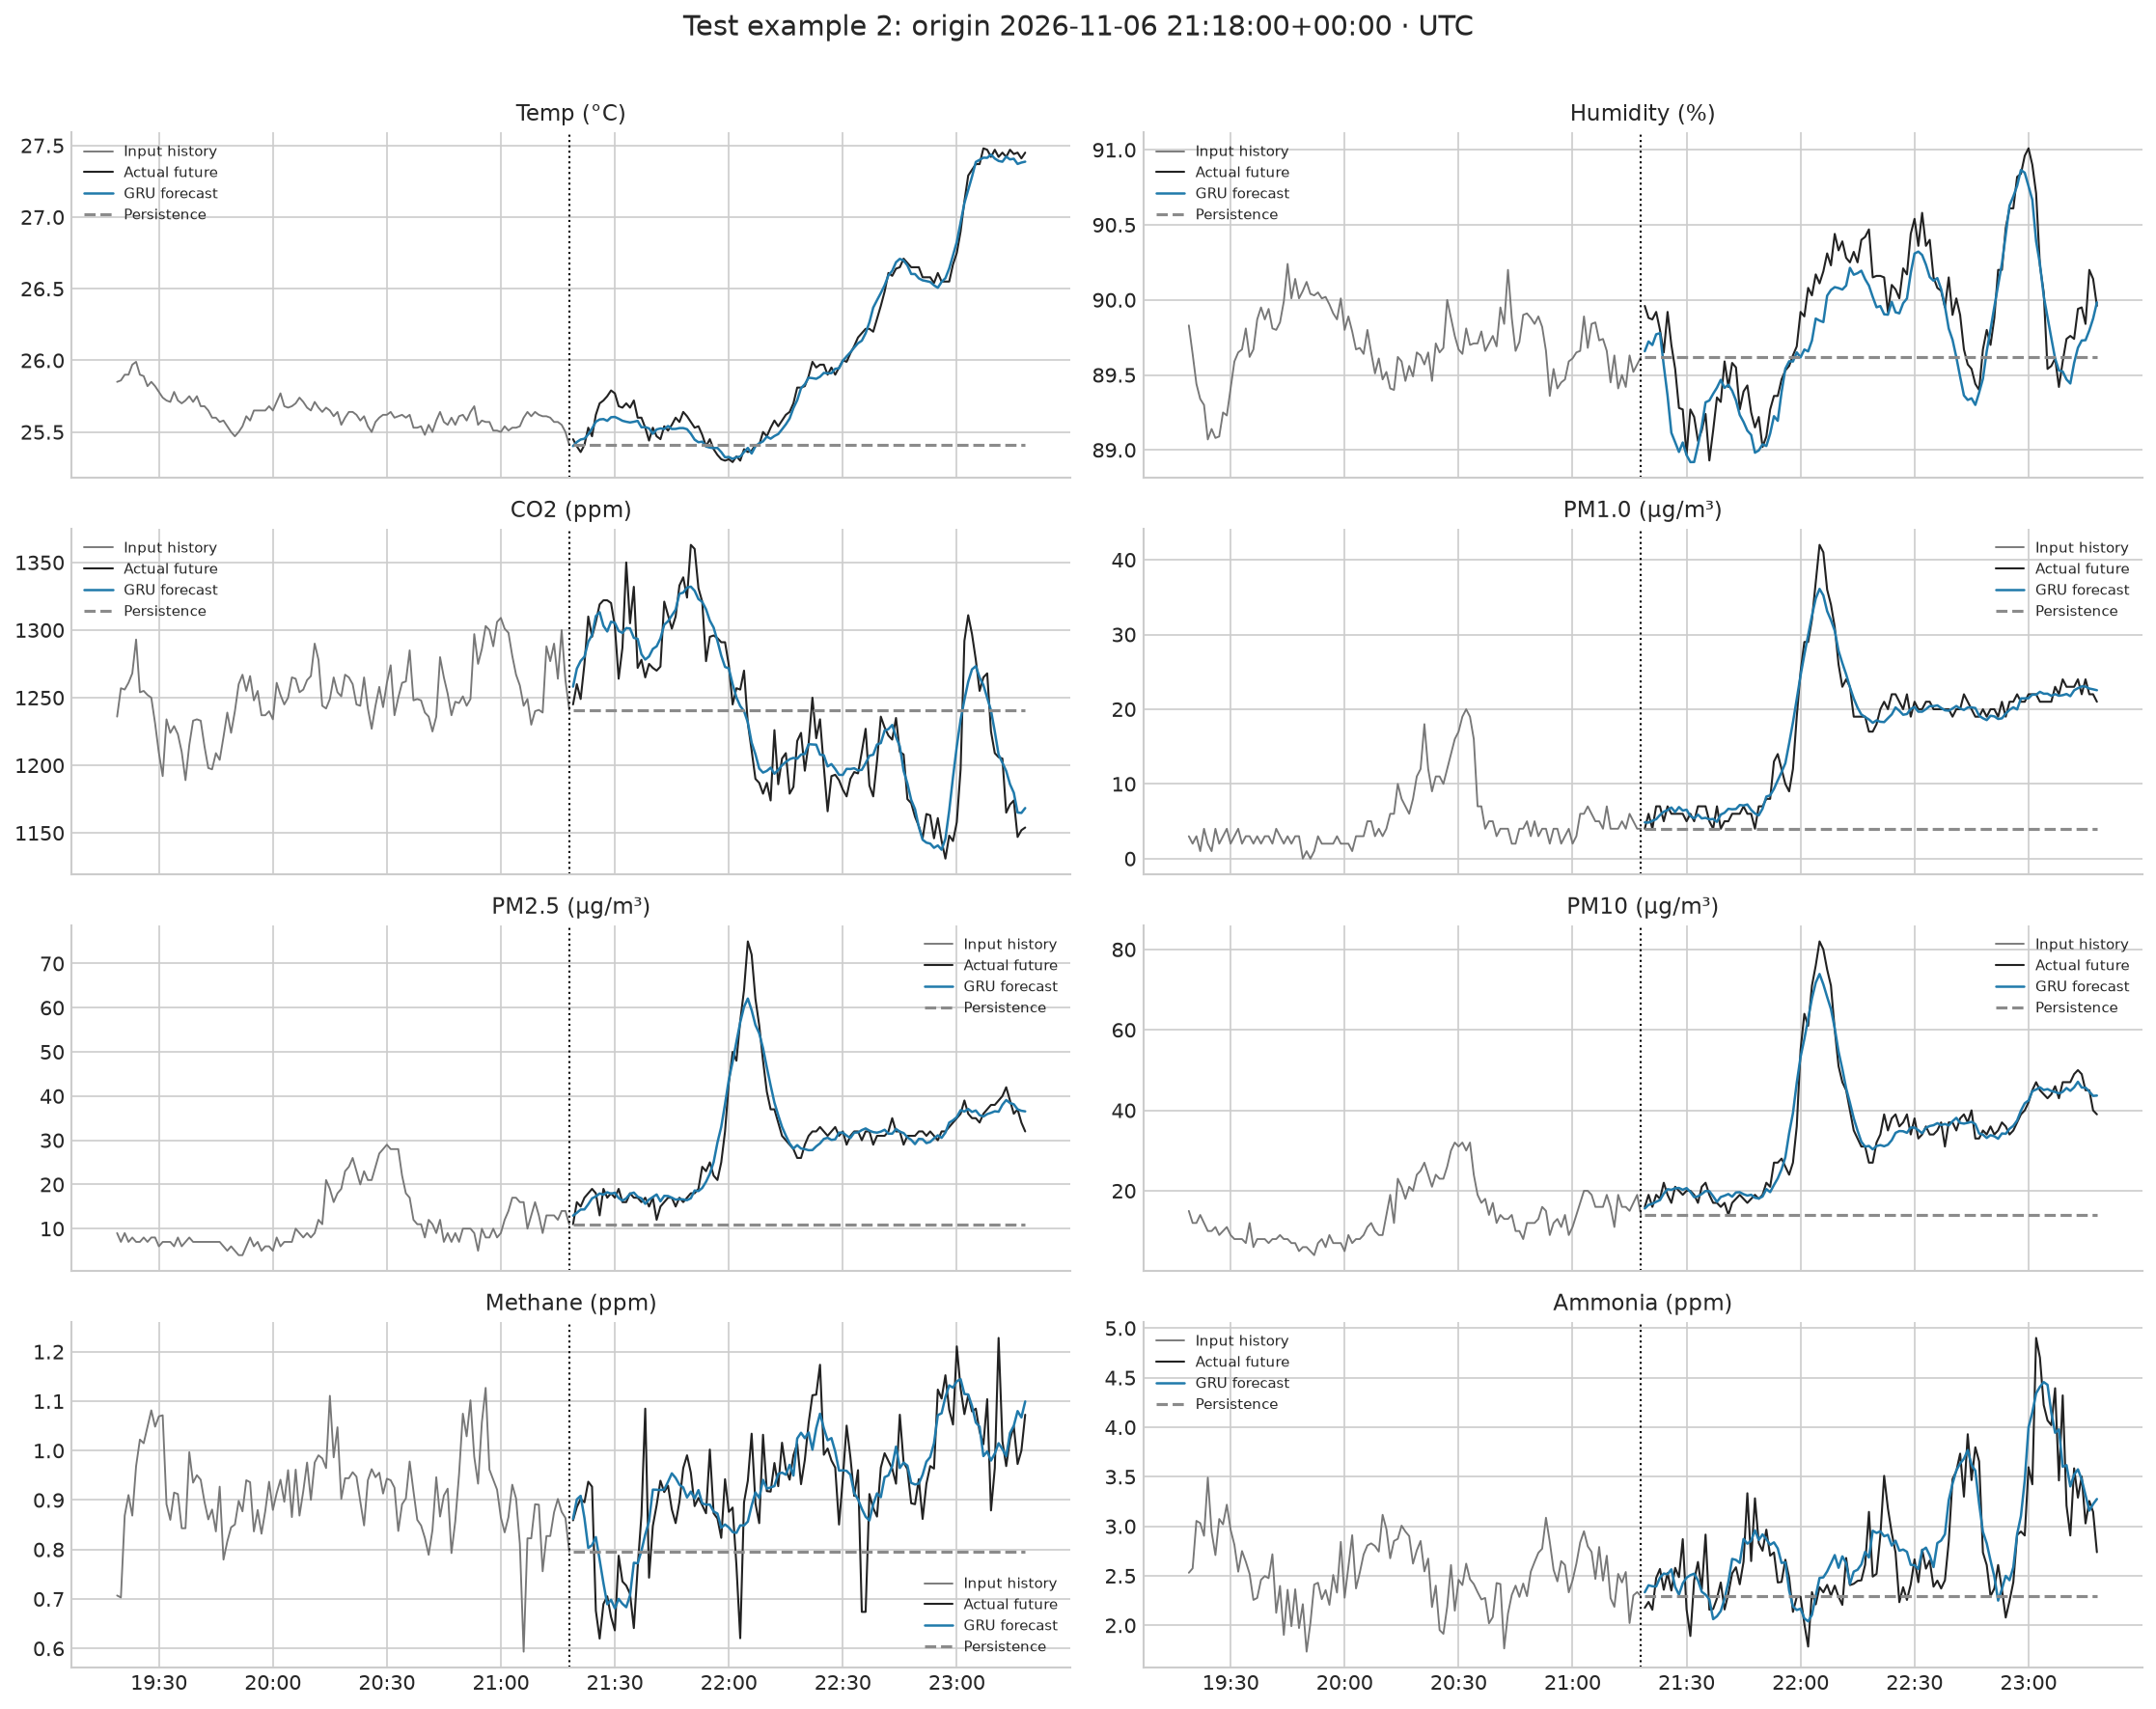

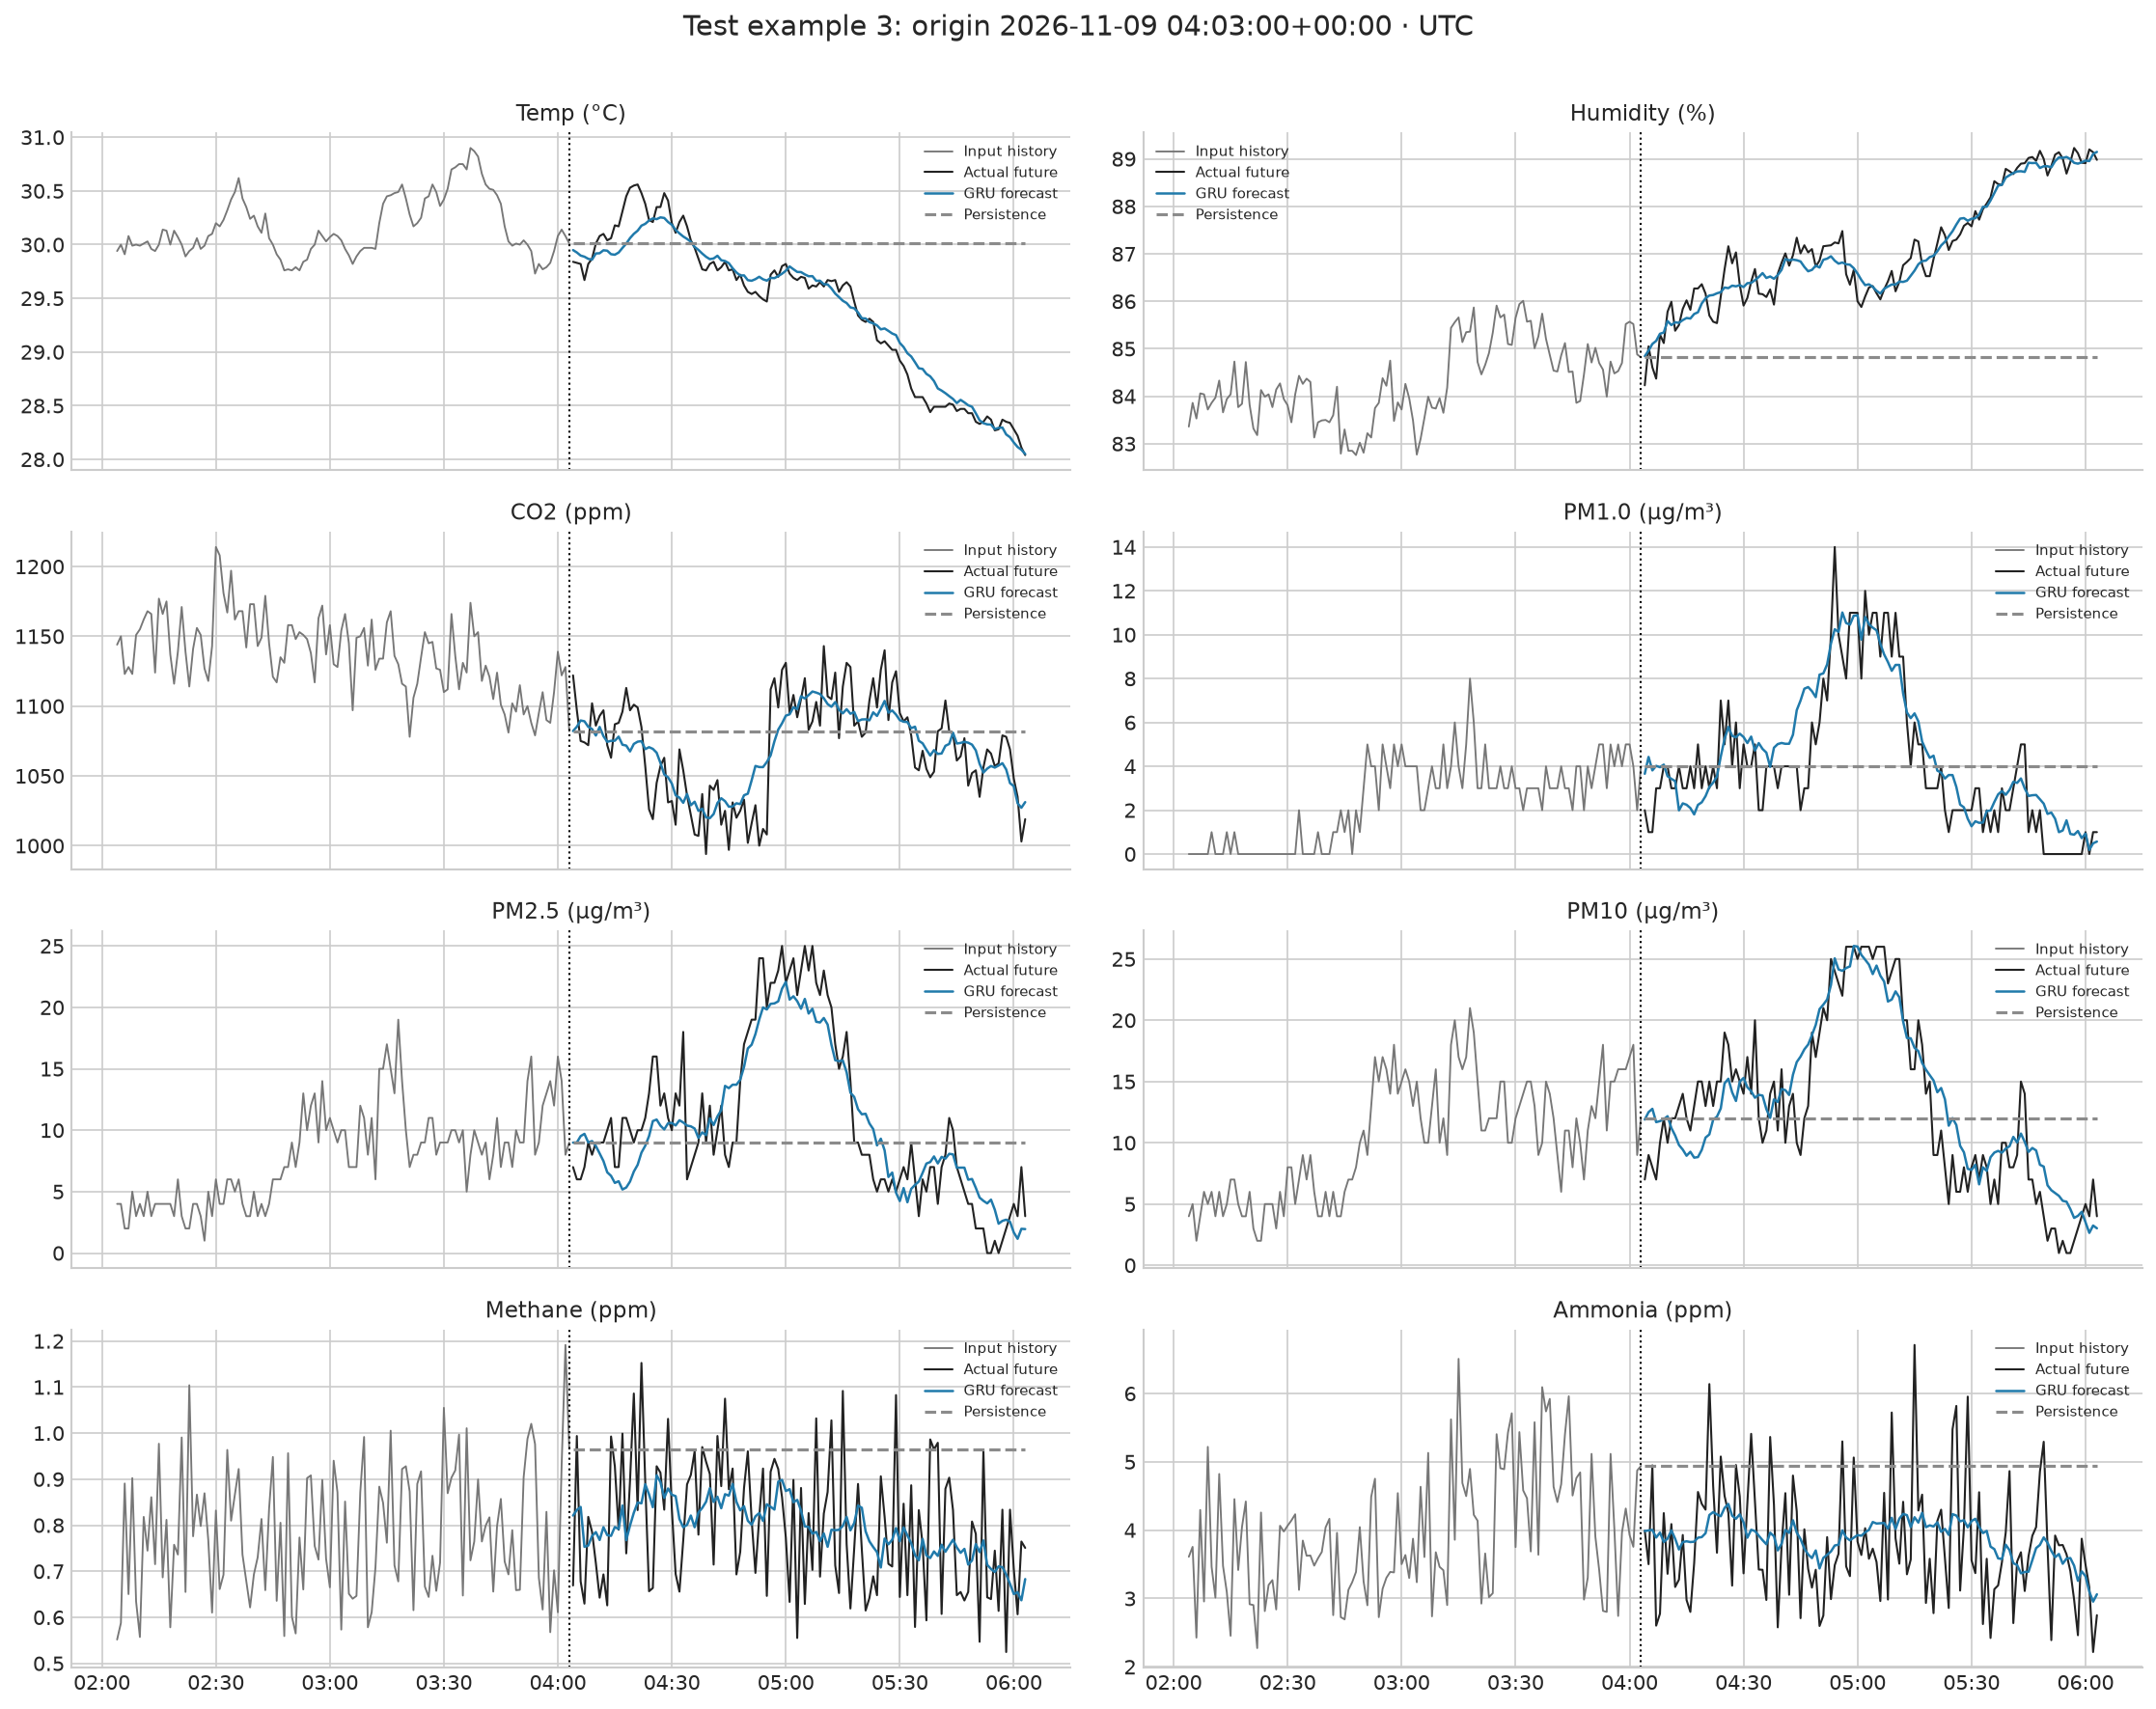

In [ ]:
example_position=int(positions['test'][0])
example_input=data.iloc[example_position-H+1:example_position+1].copy()
example_actual=data.iloc[example_position+1:example_position+F+1].copy()
example_forecast=forecast_next_120_minutes(example_input,reloaded)
example_baseline=pd.DataFrame(np.repeat(example_input.iloc[-1].to_numpy()[None,:],120,axis=0),
                              index=example_forecast.index,columns=SENSORS)
display(Markdown(f'**Input:** {example_input.index[0]} through {example_input.index[-1]}.<br>**Output:** {example_forecast.index[0]} through {example_forecast.index[-1]}.'))
display(pd.concat([example_input.head(3),example_input.tail(3)]))
print('Input shape:',example_input.shape,'| Forecast shape:',example_forecast.shape)
selected_leads=np.array([1,30,60,90,120])
example_display=[]
for lead in selected_leads:
    for j,sensor in enumerate(SENSORS):
        example_display.append(dict(lead_minutes=int(lead),sensor=sensor,
            predicted=float(example_forecast.iloc[lead-1,j]),actual=float(example_actual.iloc[lead-1,j]),
            persistence=float(example_baseline.iloc[lead-1,j])))
display(pd.DataFrame(example_display).round(4))
example_metrics=[]
for j,sensor in enumerate(SENSORS):
    for label,prediction in [(WINNER,example_forecast),('Persistence',example_baseline)]:
        example_metrics.append(dict(model=label,sensor=sensor,units=UNITS[j],
                                    **metric_values(example_actual.iloc[:,j],prediction.iloc[:,j])))
display(pd.DataFrame(example_metrics).round(4))
example_input.to_csv(RESULTS/'example_input.csv',index_label='Timestamp (UTC)')
example_actual.to_csv(RESULTS/'example_actual.csv',index_label='Timestamp (UTC)')
example_forecast.to_csv(RESULTS/'example_predictions.csv',index_label='Timestamp (UTC)')
example_baseline.to_csv(RESULTS/'example_persistence.csv',index_label='Timestamp (UTC)')
pd.DataFrame(example_display).to_csv(RESULTS/'example_selected_horizons.csv',index=False)
pd.DataFrame(example_metrics).to_csv(RESULTS/'example_metrics.csv',index=False)

def forecast_figure(position,title,filename):
    recent=data.iloc[position-H+1:position+1]
    actual=data.iloc[position+1:position+F+1]
    prediction=forecast_next_120_minutes(recent,reloaded)
    fig,axes=plt.subplots(4,2,figsize=(15,12),sharex=True)
    for j,ax in enumerate(axes.flat):
        ax.plot(recent.index,recent.iloc[:,j],color='#777777',label='Input history',lw=.9)
        ax.plot(actual.index,actual.iloc[:,j],color='#222222',label='Actual future',lw=1)
        ax.plot(prediction.index,prediction.iloc[:,j],color=COLORS[WINNER],label=f'{WINNER} forecast',lw=1.2)
        ax.plot(prediction.index,np.repeat(recent.iloc[-1,j],F),color=COLORS['Persistence'],ls='--',label='Persistence')
        ax.axvline(recent.index[-1],color='black',ls=':',lw=1)
        ax.set_title(SENSORS[j]);ax.legend(fontsize=7);ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    fig.suptitle(title+' · UTC',fontsize=14);fig.tight_layout(rect=[0,0,1,.97]);savefig(filename)

example_indices=[int(positions['test'][i]) for i in [0,len(positions['test'])//2,-1]]
for i,position in enumerate(example_indices):
    forecast_figure(position,f'Test example {i+1}: origin {data.index[position]}',f'15_forecast_example_{i+1}')


## 8. Latest available input: a forward forecast without known future readings
Use the final 120 consecutive minute bins. The plot and table contain predictions
only beyond the latest available timestamp; there is no future ground truth to
score. Timestamps describe the supplied series, not the computer's current time.


**Saved completed-run results.** Restored from retained run artifacts; training was not rerun.

### Saved latest-origin forecast: +1 and +120 minutes

Timestamp (UTC),Temp (°C),Humidity (%),CO2 (ppm),PM1.0 (µg/m³),PM2.5 (µg/m³),PM10 (µg/m³),Methane (ppm),Ammonia (ppm)
2026-11-09 06:04:00+00:00,28.0346,89.0399,1023.69,0.766263,2.79658,4.20607,0.712398,2.99016
2026-11-09 08:03:00+00:00,27.3634,89.7835,1041.85,1.67574,5.08856,6.93846,0.691214,2.80944


No future actual readings are supplied for this forecast.

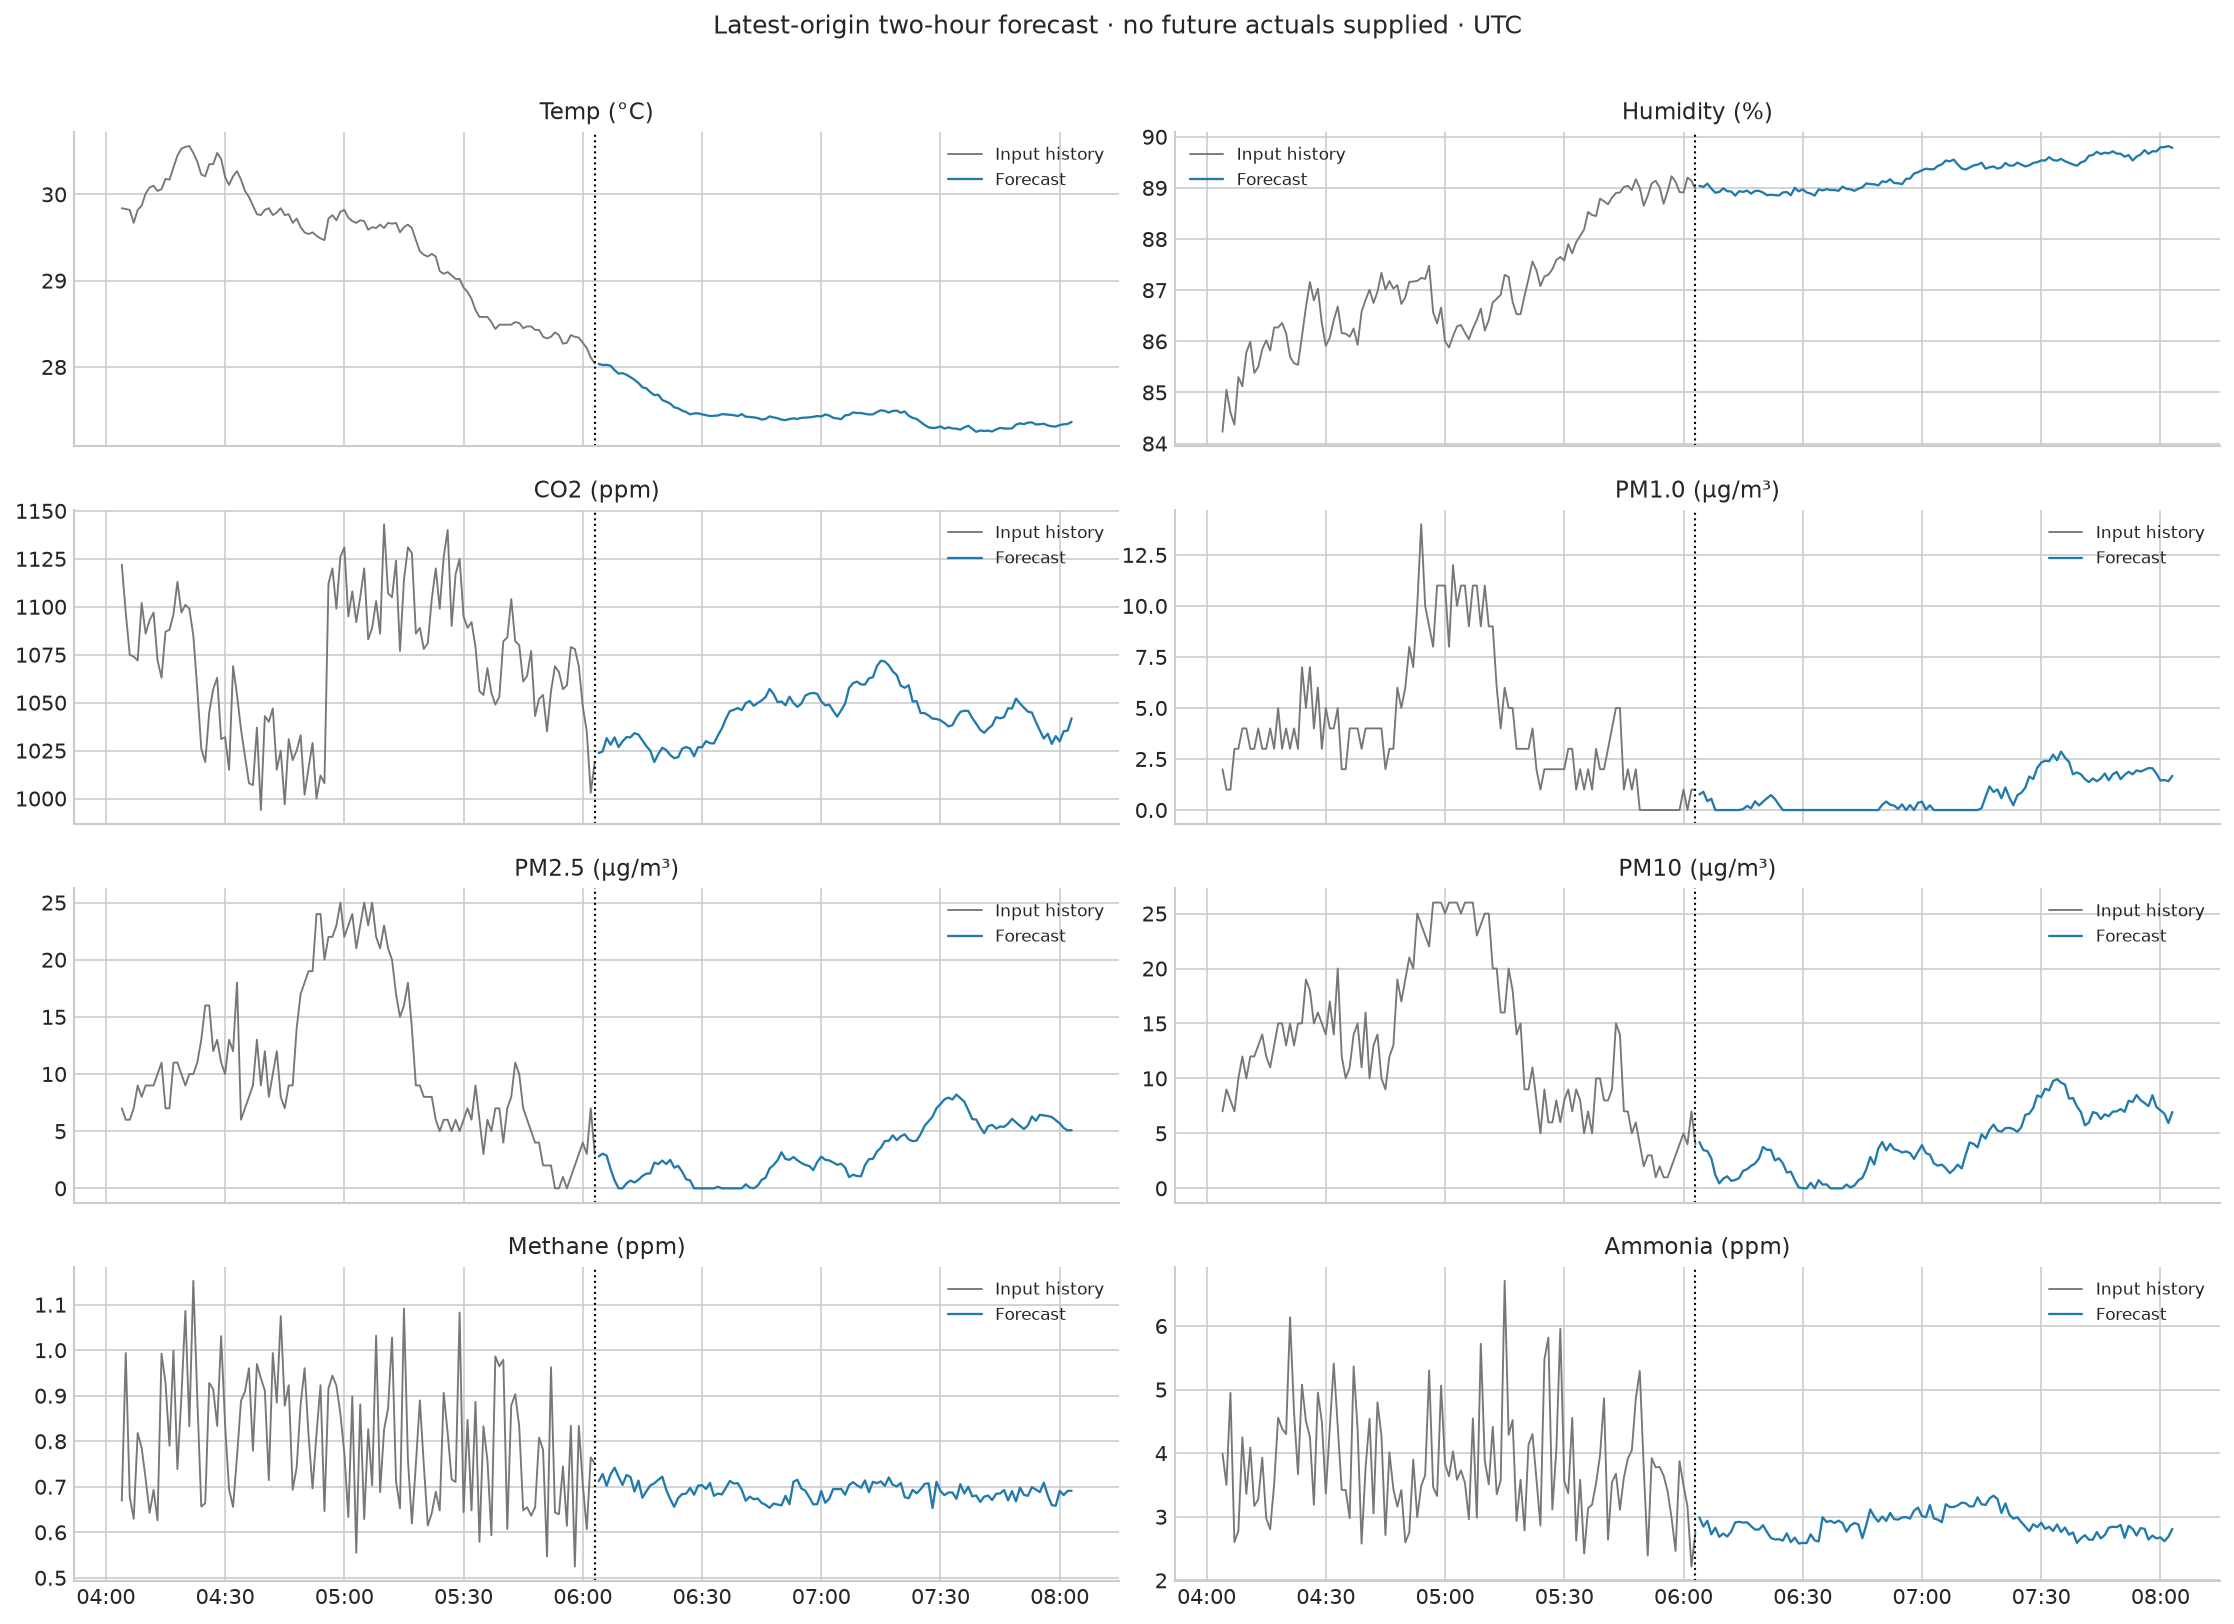

In [ ]:
latest_input=data.iloc[-H:].copy()
latest_forecast=forecast_next_120_minutes(latest_input,reloaded)
latest_forecast.to_csv(RESULTS/'latest_forecast.csv',index_label='Timestamp (UTC)')
latest_input.to_csv(RESULTS/'latest_input.csv',index_label='Timestamp (UTC)')
display(Markdown(f'Forecast origin: **{latest_input.index[-1]}**. Exactly two hours later: **{latest_forecast.index[-1]}**.'))
display(pd.DataFrame({'latest_input':latest_input.iloc[-1],
                      'prediction_at_120_minutes':latest_forecast.iloc[-1]}).round(4))
fig,axes=plt.subplots(4,2,figsize=(15,11),sharex=True)
for j,ax in enumerate(axes.flat):
    ax.plot(latest_input.index,latest_input.iloc[:,j],color='#777777',label='Input history',lw=.9)
    ax.plot(latest_forecast.index,latest_forecast.iloc[:,j],color=COLORS[WINNER],label='Forecast',lw=1.1)
    ax.axvline(latest_input.index[-1],color='black',ls=':',lw=1);ax.set_title(SENSORS[j]);ax.legend(fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
fig.suptitle('Latest-origin two-hour forecast · no future actuals supplied · UTC')
fig.tight_layout(rect=[0,0,1,.97]);savefig('16_latest_forecast')


## 9. Verification and final interpretation
These checks cover window alignment, complete histories and targets, partition
boundaries, normalization, direct metric arithmetic, input rejection, output
constraints, and artifact reload equivalence. They cannot establish biological
realism or predictive accuracy outside the evaluated series.


In [ ]:
checks=[]
def record(name,condition):
    assert bool(condition),name
    checks.append({'check':name,'passed':True})

for name,indices in positions.items():
    for t in indices:
        assert np.isfinite(INPUTS[t-H+1:t+1]).all() and np.isfinite(Z[t+1:t+F+1]).all()
        assert not blocked.iloc[t-H+1:t+F+1].any()
    record(f'{name}: every 240-minute window is complete and transition-free',True)
record('Training targets precede validation',all(data.index[t+F]<TRAIN_END for t in positions['train']))
record('Validation targets lie inside validation',all(data.index[t+1]>=TRAIN_END and data.index[t+F]<VAL_END for t in positions['validation']))
record('Test targets lie inside test',all(data.index[t+1]>=VAL_END for t in positions['test']))
record('Normalization fitted only before training cutoff',np.allclose(MEAN,data.loc[data.index<TRAIN_END].mean(),atol=1e-5))
record('Exact +1 and +120-minute output timestamps',example_forecast.index[0]==example_input.index[-1]+pd.Timedelta(minutes=1) and example_forecast.index[-1]==example_input.index[-1]+pd.Timedelta(minutes=120))
record('Forecast output shape',example_forecast.shape==(120,8))
# Serialization must be checked with the SAME input batch size and precision.
# Batch-128 and batch-1 cuDNN GRU paths can differ slightly even with identical weights.
if WINNER in ['GRU','TCN']:
    original_model = candidate_models[WINNER].eval()
    restored_state = reloaded['bundle']['state_dict']
    record('Exported neural weights restored exactly', all(
        np.array_equal(value.detach().cpu().numpy(), restored_state[key])
        for key,value in original_model.state_dict().items()))
    one_input = torch.from_numpy(INPUTS[example_position-H+1:example_position+1].copy()).unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        original_single = project(unscale(original_model(one_input).float().cpu().numpy()))[0]
elif WINNER == 'Ridge':
    one_input = INPUTS[example_position-H+1:example_position+1][None]
    original_single = project(unscale(candidate_models['Ridge'].predict(engineered(one_input)).reshape(1,F,8)
                                     + LAST['test'][0][None,None,:]))[0]
else:
    original_single = project(unscale(np.repeat(LAST['test'][0][None,None,:],F,axis=1)))[0]
record('Reloaded artifact reproduces selected model at the same batch size',
       np.allclose(example_forecast.to_numpy(),original_single,rtol=2e-5,atol=2e-4))
batch_difference = np.abs(example_forecast.to_numpy()-test_predictions[WINNER][0])
normalized_batch_difference = batch_difference / STD
record('Single vs batched inference agrees within 0.001 training standard deviations',
       np.max(normalized_batch_difference) < 1e-3)
display(pd.DataFrame({'sensor':SENSORS,
                      'max_batch_size_difference':batch_difference.max(axis=0),
                      'difference_in_training_std_units':normalized_batch_difference.max(axis=0)}))
cpu_forecaster=load_forecaster(MODEL_PATH,'cpu')
cpu_forecast=forecast_next_120_minutes(example_input,cpu_forecaster)
record('Artifact also supports CPU inference',np.allclose(cpu_forecast,example_forecast,rtol=2e-4,atol=2e-3))
for name,prediction in test_predictions.items():
    record(f'{name}: physically constrained outputs',np.isfinite(prediction).all() and (prediction[...,1]>=0).all() and (prediction[...,1]<=100).all() and (prediction[...,2:]>=0).all() and (prediction[...,3]<=prediction[...,4]).all() and (prediction[...,4]<=prediction[...,5]).all())
known_y=np.array([1.,2.,4.,8.]);known_p=np.array([1.5,2.,3.,7.])
computed=metric_values(known_y,known_p)
record('MAE independent cross-check',np.isclose(computed['mae'],mean_absolute_error(known_y,known_p)))
record('RMSE independent cross-check',np.isclose(computed['rmse'],np.sqrt(mean_squared_error(known_y,known_p))))
record('R² independent cross-check',np.isclose(computed['r2'],r2_score(known_y,known_p)))
record('Constant-target R² remains undefined',np.isnan(metric_values(np.ones(4),np.zeros(4))['r2']))
bad_inputs={'insufficient_history':example_input.iloc[1:],
            'incorrect_columns':example_input.rename(columns={SENSORS[0]:'wrong'}),
            'missing_value':example_input.copy(), 'missing_minute':example_input.copy()}
bad_inputs['missing_value'].iloc[0,0]=np.nan
bad_inputs['missing_minute'].index=bad_inputs['missing_minute'].index.where(np.arange(H)<60,bad_inputs['missing_minute'].index+pd.Timedelta(minutes=1))
for name,bad in bad_inputs.items():
    try: forecast_next_120_minutes(bad,reloaded)
    except ValueError: record(f'Reject invalid inference input: {name}',True)
    else: raise AssertionError(f'Did not reject {name}')
record('Source CSV unchanged',hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()==SOURCE_HASH)
record('Winner was frozen before test evaluation',json.loads((RESULTS/'selection.json').read_text())['winner']==WINNER and not selection['test_used_for_selection'])
check_table=pd.DataFrame(checks);check_table.to_csv(RESULTS/'verification.csv',index=False);display(check_table)

winning_endpoint=endpoint[endpoint.model==WINNER].copy()
display(Markdown(f'## Result: **{WINNER}** is the best candidate tested by validation score.'))
display(winning_endpoint[['sensor','r2','rmse','mae','mae_improvement_percent','r2_above_075']].round(4))
met=int(winning_endpoint.r2_above_075.sum())
better=int((winning_endpoint.mae_improvement_percent>0).sum())
display(Markdown(f'At exactly two hours: **{met}/8 sensors** exceed R² > 0.75; **{better}/8 sensors** have lower MAE than persistence. '+
                 'These test comparisons do not change model selection. Results are specific to the supplied series, and do not establish calibrated sensor accuracy or operational reliability.'))

manifest=dict(configuration=CONFIG,versions=VERSIONS,device=torch.cuda.get_device_name(0),
              source_sha256=SOURCE_HASH,model_type=WINNER,selection=selection,
              partitions=split_table.to_dict('records'),
              n_test_origins=len(positions['test']),forecast_values_per_origin=F*8,
              test_target_times_are_overlapping=True,independent_field_validation=False,
              metric_target_r2=.75,endpoint_sensors_above_target=met,
              endpoint_sensors_beating_persistence_mae=better,
              figures=figure_files,verification_passed=len(checks))
(RESULTS/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
(RESULTS/'requirements-lock.txt').write_text('--extra-index-url https://download.pytorch.org/whl/cu126'+chr(10)+chr(10).join(f'{p}=={v}' for p,v in VERSIONS.items())+chr(10))
pd.DataFrame([dict(sensor=s,mean=float(m),std=float(st),units=u) for s,m,st,u in zip(SENSORS,MEAN,STD,UNITS)]).to_csv(RESULTS/'normalization.csv',index=False)
print('All checks passed:',len(checks))
print('Model:',MODEL_PATH.name)
print('Example: example_input.csv → example_predictions.csv; actuals: example_actual.csv')


**Saved completed-run results.** Restored from retained run artifacts; training was not rerun.

## Verification: 27 checks passed

check,passed
train: every 240-minute window is complete and transition-free,True
validation: every 240-minute window is complete and transition-free,True
test: every 240-minute window is complete and transition-free,True
Training targets precede validation,True
Validation targets lie inside validation,True
Test targets lie inside test,True
Normalization fitted only before training cutoff,True
Exact +1 and +120-minute output timestamps,True
Forecast output shape,True
Exported neural weights restored exactly,True


The export restores exact weights and reproduces batch-128 cached test predictions exactly. The corrected check compares matching batch sizes. Single-versus-batch variation is checked separately; its maximum was 0.000188697 training standard deviations. No retraining was performed during verification.

## Final interpretation: GRU

sensor,r2,rmse,mae,mae_improvement_percent,r2_above_075
Temp (°C),0.98444,0.123994,0.0989231,87.567,True
Humidity (%),0.941966,0.259086,0.201708,84.5371,True
CO2 (ppm),0.850041,22.2031,17.2338,72.9618,True
PM1.0 (µg/m³),0.971382,1.37827,0.785858,84.3498,True
PM2.5 (µg/m³),0.972669,2.10428,1.49248,81.5468,True
PM10 (µg/m³),0.966329,2.69592,1.87902,80.0527,True
Methane (ppm),0.425073,0.138899,0.112741,35.7837,False
Ammonia (ppm),0.410457,0.644626,0.499818,38.6423,False


At exactly +120 minutes, **6/8 sensors** exceed R² > 0.75 and **8/8** beat persistence on MAE. Methane and ammonia remain below the R² target. Scores describe the supplied series, not independent field validation or reference-instrument calibration.

## Consolidated metrics file

The following cell generates **[metrics_summary.csv](metrics_summary.csv)** using
saved evaluation results only. It can run independently of training and does not
require PyTorch, a GPU, or model weights.

The file contains **72 rows**: all four candidates, both evaluation scopes (all
120 forecast horizons and exactly +120 minutes), eight overall summaries and
64 per-sensor summaries. Per-sensor RMSE/MAE retain their original units.

For each model, **overall R² is the unweighted mean of defined per-sensor R²
scores**. Overall normalized RMSE is the square root of the mean per-sensor
standardized MSE; normalized MAE is the mean per-sensor MAE divided by its training
standard deviation. This gives equal sensor weight without mixing °C, ppm and
µg/m³. Raw overall RMSE/MAE are deliberately blank because those units cannot be
meaningfully combined. These are summaries, not sums of R²/RMSE/MAE.


In [ ]:
# Standalone export: uses saved metrics only; no training or GPU is required.
import csv
import html
import json
import math
from pathlib import Path

def export_metrics_summary(results_directory):
    directory = Path(results_directory)
    def read(name):
        with (directory / name).open(newline='', encoding='utf-8') as stream:
            return list(csv.DictReader(stream))
    scales = {row['sensor']: float(row['std']) for row in read('normalization.csv')}
    if not all(math.isfinite(value) and value > 0 for value in scales.values()):
        raise ValueError('Training standard deviations must be positive and finite.')
    selected = json.loads((directory / 'selection.json').read_text())['winner']
    test_origins = json.loads((directory / 'run_manifest.json').read_text())['n_test_origins']
    units = {row['sensor']: row['units'] for row in read('normalization.csv')}
    rows = []
    for scope, filename, leads in [
        ('all_120_horizons', 'metrics_all_horizons.csv', 120),
        ('exactly_120_minutes', 'metrics_at_120_minutes.csv', 1),
    ]:
        inputs = read(filename)
        models = list(dict.fromkeys(row['model'] for row in inputs))
        for model in models:
            sensors = [row for row in inputs if row['model'] == model]
            if len(sensors) != 8 or len({row['sensor'] for row in sensors}) != 8:
                raise ValueError('Expected eight unique sensors per candidate.')
            normalized_mse = []
            normalized_mae = []
            defined_r2 = []
            for row in sensors:
                sensor = row['sensor']
                r2, rmse, mae = (float(row[key]) for key in ['r2', 'rmse', 'mae'])
                if not math.isfinite(rmse) or not math.isfinite(mae):
                    raise ValueError('Nonfinite MAE or RMSE in saved metrics.')
                normalized_mse.append((rmse / scales[sensor]) ** 2)
                normalized_mae.append(mae / scales[sensor])
                if math.isfinite(r2): defined_r2.append(r2)
                rows.append(dict(scope=scope, level='per_sensor', model=model, sensor=sensor,
                    units=units[sensor], r2=r2 if math.isfinite(r2) else '', rmse=rmse, mae=mae,
                    normalized_rmse=rmse/scales[sensor], normalized_mae=mae/scales[sensor],
                    sensor_count=1, r2_defined_sensors=int(math.isfinite(r2)),
                    sensors_above_r2_075=int(math.isfinite(r2) and r2 > .75),
                    test_origins=test_origins, evaluated_forecast_values=test_origins*leads,
                    validation_selected=(model == selected)))
            rows.append(dict(scope=scope, level='overall', model=model, sensor='ALL_8_SENSORS',
                units='normalized error: training standard deviations; raw MAE/RMSE not pooled',
                r2=sum(defined_r2)/len(defined_r2) if defined_r2 else '', rmse='', mae='',
                normalized_rmse=math.sqrt(sum(normalized_mse)/8),
                normalized_mae=sum(normalized_mae)/8, sensor_count=8,
                r2_defined_sensors=len(defined_r2), sensors_above_r2_075=sum(value>.75 for value in defined_r2),
                test_origins=test_origins, evaluated_forecast_values=test_origins*leads*8,
                validation_selected=(model == selected)))
    overall = [row for row in rows if row['level']=='overall']
    per_sensor = [row for row in rows if row['level']=='per_sensor']
    output = directory / 'metrics_summary.csv'
    with output.open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(overall + per_sensor)
    return output, overall, per_sensor

location = Path.cwd().resolve()
for candidate in [location, *location.parents]:
    if (candidate / 'metrics_all_horizons.csv').exists():
        metrics_directory = candidate
        break
    if (candidate / 'outputs/forecasting_results/metrics_all_horizons.csv').exists():
        metrics_directory = candidate / 'outputs/forecasting_results'
        break
else:
    raise FileNotFoundError('Run from the project or saved-results directory.')

metrics_summary_path, overall_metrics, per_sensor_metrics = export_metrics_summary(metrics_directory)
print('Saved:', metrics_summary_path.name)
print('72 rows: 8 overall model summaries + 64 per-sensor summaries.')
print('Scopes: all 120 horizons, and exactly +120 minutes.')
print('Overall R² is the mean of defined per-sensor R² scores.')
print('Overall RMSE/MAE use training-standard-deviation units; raw mixed-unit errors are not pooled.')

summary_headers = ['scope','model','r2','normalized_rmse','normalized_mae','sensors_above_r2_075','validation_selected']
def summary_html(values, headers):
    def text(value):
        return f'{value:.6f}' if isinstance(value,float) else str(value)
    return '<table><thead><tr>'+''.join('<th>'+html.escape(key)+'</th>' for key in headers)+'</tr></thead><tbody>'+''.join(
        '<tr>'+''.join('<td>'+html.escape(text(row[key]))+'</td>' for key in headers)+'</tr>' for row in values)+'</tbody></table>'

overall_summary_html = summary_html(overall_metrics, summary_headers)
try:
    from IPython.display import display, HTML
except ImportError:
    for row in overall_metrics:
        print(row['scope'], row['model'], 'macro R²=', round(row['r2'],6),
              'normalized RMSE=',round(row['normalized_rmse'],6),
              'normalized MAE=',round(row['normalized_mae'],6))
else:
    display(HTML(overall_summary_html))
    chosen = [row for row in per_sensor_metrics if row['validation_selected']]
    display(HTML(summary_html(chosen,['scope','sensor','units','r2','rmse','mae'])))


Saved: metrics_summary.csv
72 rows: 8 overall model summaries + 64 per-sensor summaries.
Scopes: all 120 horizons, and exactly +120 minutes.
Overall R² is the mean of defined per-sensor R² scores.
Overall RMSE/MAE use training-standard-deviation units; raw mixed-unit errors are not pooled.
all_120_horizons Persistence macro R²= 0.115306 normalized RMSE= 0.868643 normalized MAE= 0.578768
all_120_horizons Ridge macro R²= 0.728477 normalized RMSE= 0.498306 normalized MAE= 0.329808
all_120_horizons GRU macro R²= 0.814841 normalized RMSE= 0.424359 normalized MAE= 0.254692
all_120_horizons TCN macro R²= 0.805049 normalized RMSE= 0.434405 normalized MAE= 0.265444
exactly_120_minutes Persistence macro R²= -0.454756 normalized RMSE= 1.040743 normalized MAE= 0.752526
exactly_120_minutes Ridge macro R²= 0.724024 normalized RMSE= 0.499291 normalized MAE= 0.34652
exactly_120_minutes GRU macro R²= 0.815295 normalized RMSE= 0.418926 normalized MAE= 0.249326
exactly_120_minutes TCN macro R²= 0.804733 

scope,model,r2,normalized_rmse,normalized_mae,sensors_above_r2_075,validation_selected
all_120_horizons,Persistence,0.115306,0.868643,0.578768,1,False
all_120_horizons,Ridge,0.728477,0.498306,0.329808,5,False
all_120_horizons,GRU,0.814841,0.424359,0.254692,6,True
all_120_horizons,TCN,0.805049,0.434405,0.265444,6,False
exactly_120_minutes,Persistence,-0.454756,1.040743,0.752526,0,False
exactly_120_minutes,Ridge,0.724024,0.499291,0.346520,5,False
exactly_120_minutes,GRU,0.815295,0.418926,0.249326,6,True
exactly_120_minutes,TCN,0.804733,0.429202,0.257737,6,False


## Selected GRU metrics and comparison graphs

Two separate dashboards summarize the **exactly +120-minute** test metrics.
The first shows the selected model's overall scores and the eight sensor-unit
results. The second compares GRU with TCN, Ridge and persistence. Overall RMSE
and MAE are normalized by training standard deviations; macro R² averages the
per-sensor R² scores. These graphs use saved evaluation files and do not retrain.


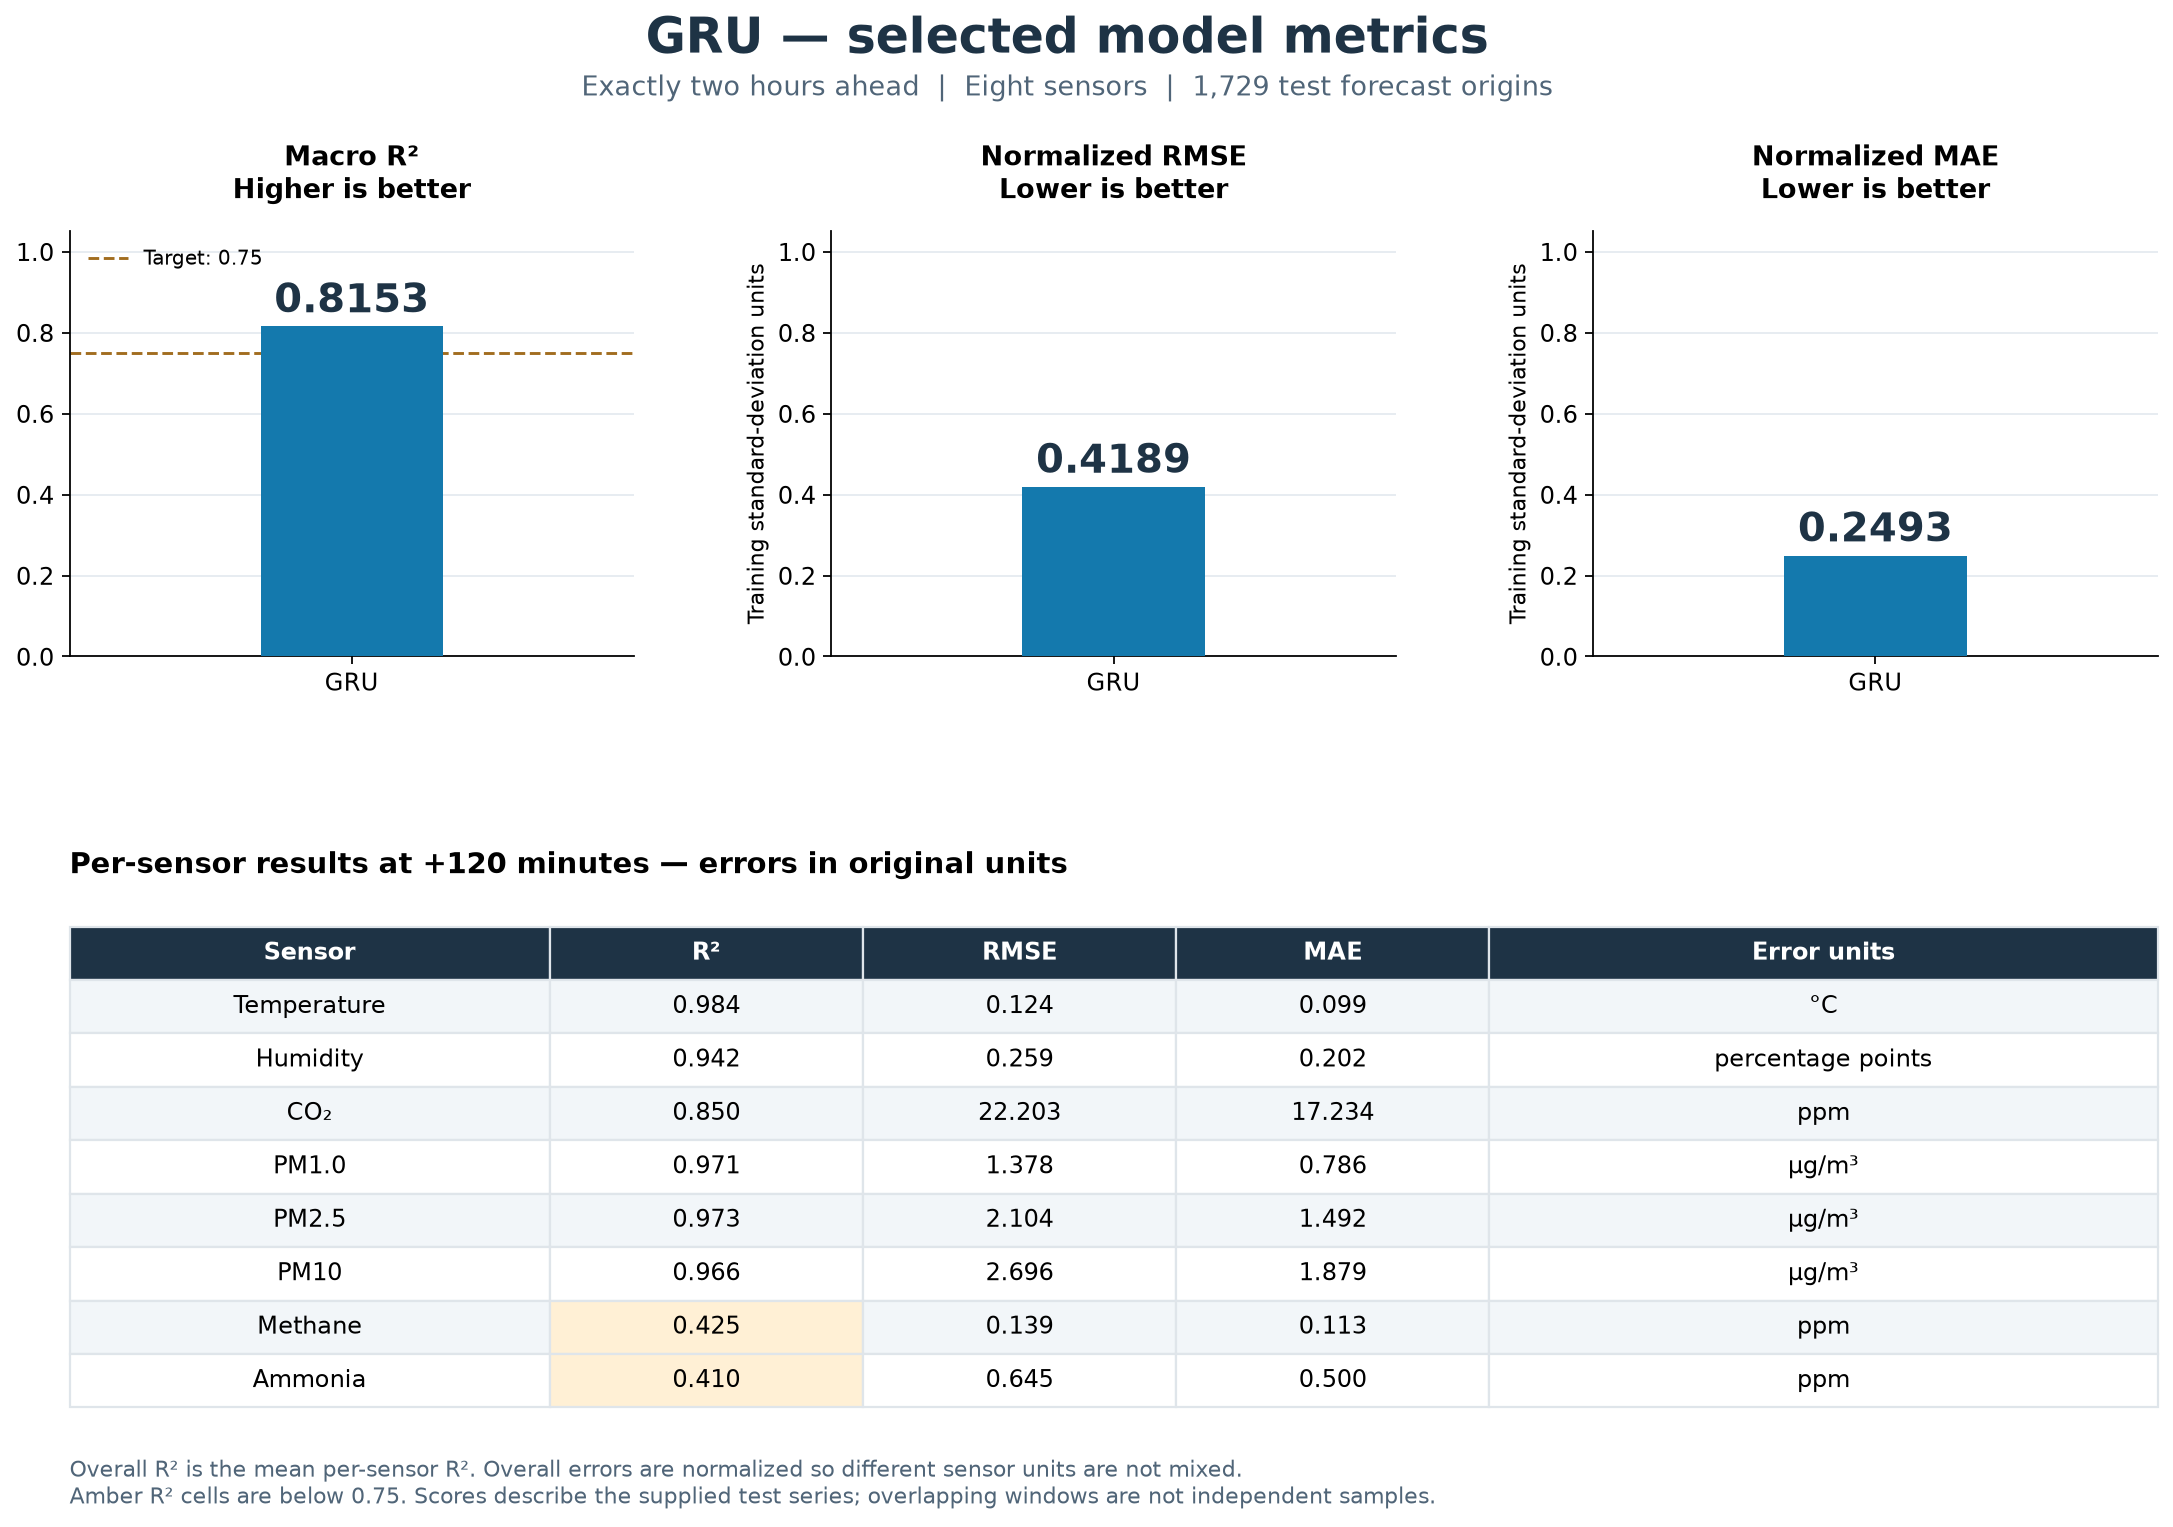

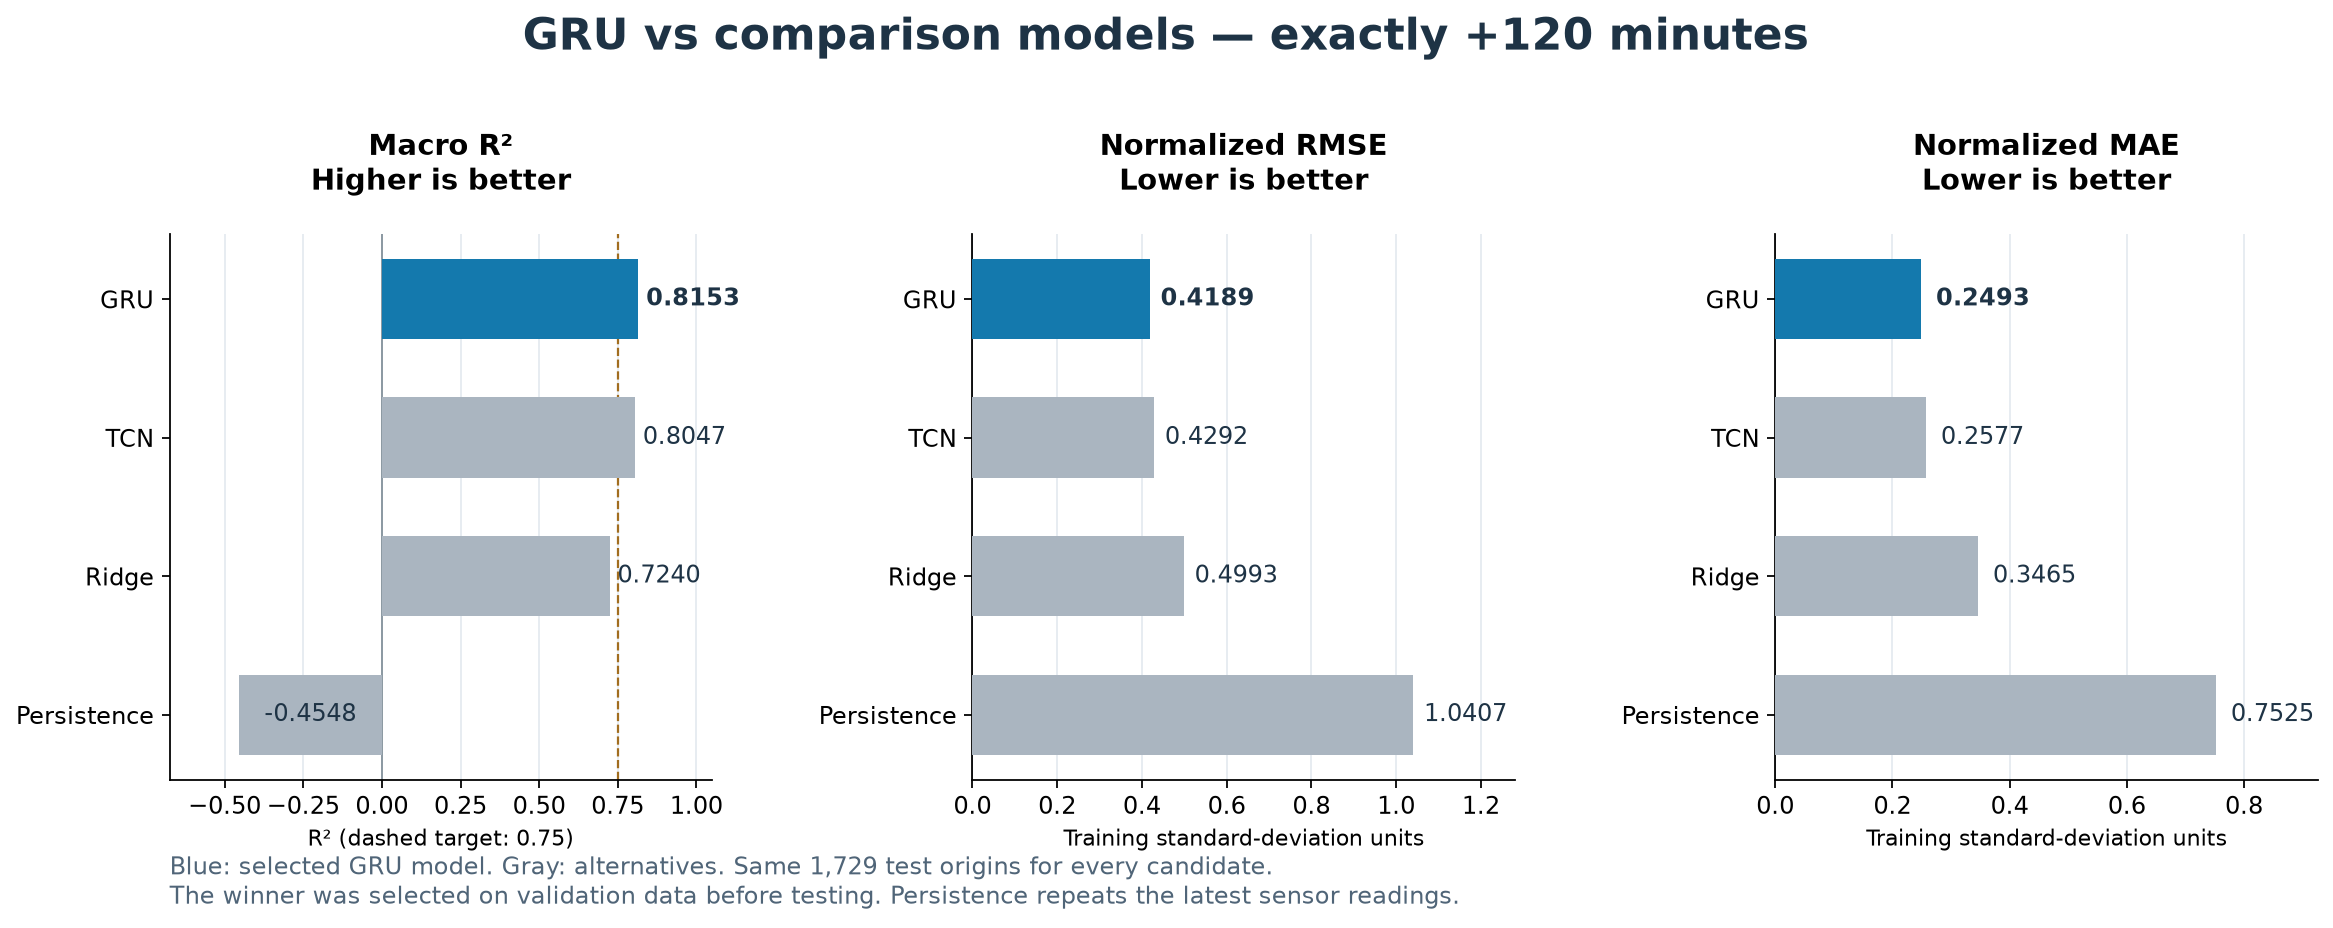

In [ ]:
"""Generate two metric dashboards from the saved completed-run CSV files."""
from pathlib import Path
import csv
import json

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

current = Path.cwd().resolve()
for parent in [current, *current.parents]:
    if (parent / 'metrics_summary.csv').exists():
        results = parent
        break
    if (parent / 'outputs/forecasting_results/metrics_summary.csv').exists():
        results = parent / 'outputs/forecasting_results'
        break
else:
    raise FileNotFoundError('Run from the project or forecasting-results directory.')

with (results / 'metrics_summary.csv').open(newline='', encoding='utf-8') as stream:
    rows = list(csv.DictReader(stream))
selected = json.loads((results / 'selection.json').read_text())['winner']
scope = [row for row in rows if row['scope'] == 'exactly_120_minutes']
overall = {row['model']: row for row in scope if row['level'] == 'overall'}
sensors = [row for row in scope if row['level'] == 'per_sensor' and row['model'] == selected]
assert len(sensors) == 8
figure_directory = results / 'figures'
figure_directory.mkdir(exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'figure.facecolor': 'white'})
blue, gray, ink = '#1479AD', '#AAB5C0', '#1E3345'
metric_specs = [('r2', 'Macro R²\nHigher is better'),
                ('normalized_rmse', 'Normalized RMSE\nLower is better'),
                ('normalized_mae', 'Normalized MAE\nLower is better')]

# Graph 1: selected model totals, plus all sensor metrics in their own units.
fig = plt.figure(figsize=(14.5, 10))
grid = GridSpec(2, 3, figure=fig, height_ratios=[1.4, 1.65], hspace=.54, wspace=.35)
for i, (key, title) in enumerate(metric_specs):
    ax = fig.add_subplot(grid[0, i])
    value = float(overall[selected][key])
    ax.bar([0], [value], color=blue, width=.42, zorder=3)
    ax.set_xlim(-.65, .65)
    ax.set_ylim(0, 1.05)
    ax.set_xticks([0], [selected])
    ax.set_title(title, fontsize=12, pad=15)
    ax.text(0, value+.035, f'{value:.4f}', ha='center', fontsize=18, weight='bold', color=ink)
    ax.grid(axis='y', color='#E5EAF0', zorder=0)
    ax.set_axisbelow(True)
    if key == 'r2':
        ax.axhline(.75, color='#A16D1F', ls='--', lw=1.3, label='Target: 0.75')
        ax.legend(loc='upper left', fontsize=9, frameon=False)
    else:
        ax.set_ylabel('Training standard-deviation units', fontsize=10)

table_ax = fig.add_subplot(grid[1, :])
table_ax.axis('off')
table_ax.set_title('Per-sensor results at +120 minutes — errors in original units',
                   fontsize=13, loc='left', pad=15)
names = ['Temperature', 'Humidity', 'CO₂', 'PM1.0', 'PM2.5', 'PM10', 'Methane', 'Ammonia']
unit_labels = ['°C', 'percentage points', 'ppm', 'µg/m³', 'µg/m³', 'µg/m³', 'ppm', 'ppm']
values = [[name, f"{float(row['r2']):.3f}", f"{float(row['rmse']):.3f}",
           f"{float(row['mae']):.3f}", unit]
          for name, unit, row in zip(names, unit_labels, sensors)]
table = table_ax.table(cellText=values, colLabels=['Sensor', 'R²', 'RMSE', 'MAE', 'Error units'],
                       colWidths=[.23, .15, .15, .15, .32], loc='center', cellLoc='center',
                       bbox=[0, 0, 1, .96])
table.auto_set_font_size(False)
table.set_fontsize(11)
for (i,j), cell in table.get_celld().items():
    cell.set_edgecolor('#DFE5EA')
    if i == 0:
        cell.set_facecolor(ink)
        cell.set_text_props(color='white', weight='bold')
    else:
        cell.set_facecolor('#F2F6F9' if i % 2 else 'white')
        if j == 1 and float(sensors[i-1]['r2']) < .75:
            cell.set_facecolor('#FFF0D5')
fig.suptitle(f'{selected} — selected model metrics', fontsize=22, weight='bold', color=ink, y=.975)
fig.text(.5, .925, 'Exactly two hours ahead  |  Eight sensors  |  1,729 test forecast origins',
         ha='center', fontsize=12, color='#506578')
fig.subplots_adjust(left=.07, right=.97, top=.84, bottom=.105)
fig.text(.07, .045, 'Overall R² is the mean per-sensor R². Overall errors are normalized so different sensor units are not mixed.\n'
         'Amber R² cells are below 0.75. Scores describe the supplied test series; overlapping windows are not independent samples.',
         fontsize=10, color='#506578')
selected_graph = figure_directory / '17_gru_metrics.png'
fig.savefig(selected_graph, dpi=160, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)

# Graph 2: separate, fair comparison using the same scope and normalization.
order = [selected] + [row['model'] for row in sorted(overall.values(), key=lambda row: -float(row['r2']))
                     if row['model'] != selected]
fig, axes = plt.subplots(1, 3, figsize=(15, 6.2))
for ax, (key, title) in zip(axes, metric_specs):
    scores = [float(overall[name][key]) for name in order]
    bars = ax.barh(order, scores, color=[blue if name == selected else gray for name in order],
                   height=.58, zorder=3)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=13, pad=20)
    ax.axvline(0, color='#82909A', lw=.8)
    ax.grid(axis='x', color='#E5EAF0')
    ax.set_axisbelow(True)
    for name, value, bar in zip(order, scores, bars):
        ax.text(value+.025 if value >= 0 else value/2, bar.get_y()+bar.get_height()/2,
                f'{value:.4f}', va='center', ha='left' if value >= 0 else 'center',
                color=ink, weight='bold' if name == selected else 'normal', fontsize=11)
    if key == 'r2':
        ax.set_xlim(min(-.65, min(scores)-.22), 1.05)
        ax.axvline(.75, color='#A16D1F', ls='--', lw=1, label='Target: 0.75')
        ax.set_xlabel('R² (dashed target: 0.75)', fontsize=10)
    else:
        ax.set_xlim(0, max(scores)*1.23)
        ax.set_xlabel('Training standard-deviation units', fontsize=10)
fig.suptitle(f'{selected} vs comparison models — exactly +120 minutes', fontsize=20,
             weight='bold', color=ink, y=.98)
fig.subplots_adjust(left=.085, right=.98, top=.76, bottom=.21, wspace=.48)
fig.text(.085, .085, f'Blue: selected {selected} model. Gray: alternatives. Same 1,729 test origins for every candidate.\n'
         'The winner was selected on validation data before testing. Persistence repeats the latest sensor readings.',
         fontsize=11, color='#506578')
comparison_graph = figure_directory / '18_model_comparison.png'
fig.savefig(comparison_graph, dpi=160, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)
print('Saved:', selected_graph.name, 'and', comparison_graph.name)


## Using the exported model later
Run the imports, model definitions, `engineered`, `project`, loader and forecast
function definitions from this notebook; training is not required to use an
existing artifact. Then:

```python
forecaster = load_forecaster(RESULTS / 'microclimate_forecaster.joblib', device='cuda')
recent = pd.read_csv(RESULTS / 'example_input.csv', index_col=0)
recent.index = pd.to_datetime(recent.index, utc=True)
prediction = forecast_next_120_minutes(recent, forecaster)
display(prediction)
```

Provide exactly 120 consecutive, minute-aligned readings with the same columns
and units. Use `device='cpu'` for inference without a GPU. The forecast does not
require actual future readings; those are used only to evaluate historical examples.
